# A* pour plusieurs robot (sans tâche)

On utilise les classes existantes pour généraliser à un ensemble de robot qu'on affecte à une pièce.

In [224]:
# import de module

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.cm as cm
import numpy as np
import pandas as pd
import networkx as nx
from networkx.algorithms.community import greedy_modularity_communities
import community.community_louvain as community_louvain
import community as community_louvain
from matplotlib.patches import Circle
from sklearn.cluster import KMeans
import copy
import pulp
from copy import deepcopy

### Classe Mur

In [225]:
class Mur:
    """ 
    Classe pour les murs de la pièce    
    """

    def __init__(self, position):
        """ 
        Paramètre:
        ----------
        position : liste de deux listes
            position des deux extrémités du mur
        """
        self.position = position
        self.longueur = np.sqrt(
            (position[1][0] - position[0][0])**2 + (position[1][1] - position[0][1])**2)
        self.type = "mur"

    def __repr__(self):
        return f"Mur de longueur {self.longueur} et de position {self.position}"

    def __str__(self):
        return f"{self.type} de longueur {self.longueur} et de position {self.position}"


print("Test de la classe Mur")
mur1 = Mur([[0, 0], [0, 1]])
print(mur1)

Test de la classe Mur
mur de longueur 1.0 et de position [[0, 0], [0, 1]]


### Classe Porte

In [226]:
# On créé une classe pour les portes de la pièce

class Porte:
    """
    Classe pour les portes de la pièce
    """

    def __init__(self, position, statut):
        """
        Constructeur de la classe
        Paramètres:
        -----------
        positon: position de la porte définis comme une liste des coordonnées de début et de fin (cf. murs)
        exemple : position = [[0,0], [0,1]]
        statut: ouvert ou fermé
        """

        self.position = position
        self.statut = statut
        self.largeur = np.sqrt(
            (position[1][0] - position[0][0])**2 + (position[1][1] - position[0][1])**2)
        self.type = "porte"

    def __str__(self):
        """
        Méthode pour afficher les informations de la porte
        :return: les informations de la porte
        """
        return f"Porte à la position {self.position} de largeur {self.largeur} et de statut {self.statut}"

    def __repr__(self):
        """
        Méthode pour afficher les informations de la porte
        :return: les informations de la porte
        """
        return f"Porte à la position {self.position} de largeur {self.largeur} et de statut {self.statut}"

    def ouvrir(self):
        """
        Méthode pour ouvrir la porte
        Ne retourne rien
        """
        self.statut = "ouverte"

    def fermer(self):
        """ 
        Méthode pour fermer la porte
        Ne retourne rien
        """
        self.statut = "fermee"


print("Test de la classe Porte")
porte1 = Porte([[0, 0], [0, 1]], "fermee")
print(porte1)

Test de la classe Porte
Porte à la position [[0, 0], [0, 1]] de largeur 1.0 et de statut fermee


### Classe Pièce

In [310]:
# On créer une pièce pour que le robot cicule dedans

class Piece:
    """
    Une pièce est définie par sa longueur, sa largeur et la liste des murs interne qui la compose.
    C'est par defaut un rectangle de longueur et largeur donnée.
    Les murs sont des segments de droite, définis par deux points en coordonnées cartésiennes
    """

    def __init__(self, longueur, largeur, liste_murs, liste_portes):
        '''
        Parameters :
        longueur : longueur de la pièce
        largeur : largeur de la pièce
        liste_murs : liste des murs de la pièce, sous la forme d'une liste de classe mur
        listes_portes : liste de portes de la pièce, sous la forme d'une liste de classe porte
        depart : coordonnées du point de départ du robot    
        arrivee : coordonnées du point d'arrivée du robot
        '''

        self.longueur = longueur
        self.largeur = largeur

        self.liste_murs = liste_murs  # sans les murs extérieurs, ni les portes fermées
        liste_position = [[[0, 0], [0, largeur]], [[0, largeur], [longueur, largeur]], [
            [longueur, largeur], [longueur, 0]], [[longueur, 0], [0, 0]]]
        self.murs_exterieurs = [Mur(position) for position in liste_position]

        self.liste_portes = liste_portes
        self.portes_ouvertes = [
            portes for portes in liste_portes if portes.statut == "ouverte"]
        self.portes_fermees = [
            portes for portes in liste_portes if portes.statut == "fermee"]

        # A modifier en introduisant une classe robot
        self.liste_robot = []
        self.robot_size = {}
        self.depart = []
        self.arrivee = []
        self.robot_associe = False

    def __repr__(self):
        if self.robot_associe:
            return f"Pièce de longueur {self.longueur} et de largeur {self.largeur}, contenant le robot {self.robot.nom} "
        else:
            return f"Pièce de longueur {self.longueur} et de largeur {self.largeur}, sans robot associé"

    def __str__(self):
        if self.robot_associe:
            return f"Pièce de longueur {self.longueur} et de largeur {self.largeur}, contenant le robot {self.robot.nom} "
        else:
            return f"Pièce de longueur {self.longueur} et de largeur {self.largeur}, sans robot associé"

    def associer_robot(self, robot):
        """
        Associe des robot à la pièce
        Paramètres:
        robot: robot à associer
        """
        self.liste_robot.append(robot)
        self.robot_associe = True

        # on dimentionne le parcours pour le plus gros robot. Là où il passe, tous les autres passent
        self.robot_size[robot] = robot.taille

        self.depart.append(robot.position)

    def visualiser_toutes_rodadas_ensemble_complete_adapte(
    self, resultats_globaux, liste_robots, df_tasks, grid_size=1, plot_grille=True, save_path=None
):


        rounds = resultats_globaux["historique_rodadas"]
        num_rounds = len(rounds)

        plt.figure(figsize=(12, 12))

        # Plot muros e portas
        list_plot = [self.murs_exterieurs, self.liste_murs, self.portes_fermees]
        liste_couleur = ['black','black','red']
        liste_largeur = [3,2,2]
        for i in range(len(list_plot)):
            for mur in list_plot[i]:
                pos = mur.position
                plt.plot([pos[0][0],pos[1][0]],[pos[0][1],pos[1][1]],
                        color=liste_couleur[i], linewidth=liste_largeur[i])

        # Plot grid
        if plot_grille:
            xg, yg = self.grille(grid_size)
            for x in xg:
                for y in yg:
                    plt.scatter(x, y, color='blue', marker='+', s=30, alpha=0.3)

        # Definir estilo para cada rodada
        cmap = cm.get_cmap('tab10', num_rounds)
        styles = ['-', '--', '-.', ':', (0, (5, 5)), (0, (3, 5, 1, 5))]

        for r_idx, rod in enumerate(rounds):
            style = styles[r_idx % len(styles)]
            alpha = 0.8 - r_idx * (0.6 / max(1, num_rounds-1))
            color = cmap(r_idx)

            robots_rodada = rod["robots_utilises"]
            for robot_nom in robots_rodada:
                robot = next(r for r in liste_robots if r.nom == robot_nom)
                taches = rod["affectation_taches"].get(robot_nom, [])
                if not taches:
                    continue

                depart = robot.position  # ponto de partida da rodada

                etapes = [(robot.nom, depart)] + [
                    (robot.nom, (df_tasks.loc[t, "Coord_X"], df_tasks.loc[t,"Coord_Y"], str(t)))
                    for t in taches
                ]

                # Construir lista de etapas para tsp
                tps = [(et[1][0], et[1][1], et[1][2]) for et in etapes[1:]]
                pathes, etapes_calc = self.plus_court_chemin_tsp(depart, tps, robot, grid_size)

                # Plotar cada segmento
                for seg, étape in zip(pathes, etapes_calc):
                    px = [p[0] for p in seg]
                    py = [p[1] for p in seg]
                    plt.plot(px, py, linestyle=style, color=color, linewidth=3, alpha=alpha)
                    plt.scatter(étape[0], étape[1], color=color, marker='o', s=50, alpha=alpha)
                    plt.text(étape[0]+0.2, étape[1]+0.2, str(étape[2]), fontsize=9, color=color)

                # Opcional: marcar ponto de partida da rodada (somente para primeira tarefa)
                plt.scatter(depart[0], depart[1], marker='^', color=color, s=60, alpha=alpha,
                            label=f"{robot.nom} (R{r_idx+1})" if taches else "")

        plt.title("Chemins des robots - toutes rodadas")
        plt.axis('equal')
        plt.legend(loc='upper right', fontsize=8, ncol=2)

        if save_path:
            plt.savefig(save_path, dpi=300)
            print(f"Saved: {save_path}")
        else:
            plt.show()

    def afficher(self, plot_grille=True, grid_size=2, plot_accessible=False, plot_path=True):
        """
        Affiche la pièce
        """
    
        # On plot les mur et les portes fermées
        list_plot = [self.murs_exterieurs,
                    self.liste_murs, self.portes_fermees]
        liste_couleur = ['black', 'black', 'red']
        liste_largeur = [3, 2, 2]

        plt.figure(figsize=(10, 10))
        for i in range(len(list_plot)):
            for mur in list_plot[i]:
                position = mur.position
                plt.plot([position[0][0], position[1][0]], [position[0][1], position[1][1]], color=liste_couleur[i],
                        linewidth=liste_largeur[i])

        # On plot la grille
        if plot_grille:
            x_grille, y_grille = self.grille(grid_size)
            for x in x_grille:
                for y in y_grille:
                    plt.scatter(x, y, color='blue',
                                marker='+', s=50, linewidth=1)

        # On plot le chemin trouvé
        demarage = self.depart

        if plot_path:
            colors = ['green', 'blue', 'red']

            for i in range(len(self.liste_robot)):
                # on trace le chemin pour chacun des robots
                robot = self.liste_robot[i]
                depart = demarage[i]
                pathes, etapes = self.plus_court_chemin_tsp(
                    depart, grid_size, robot)
                # on génère une liste de couleurs pour les étapes

                couleur = colors[i]
                for j in range(len(etapes)):
                    plt.plot([p[0] for p in pathes[j]], [p[1]
                            for p in pathes[j]], color=couleur, linewidth=4)
                    plt.scatter(etapes[j][0], etapes[j][1],
                                color=couleur, marker='o', s=50, linewidth=4)
                    plt.text(etapes[j][0], etapes[j][1],
                            etapes[j][2], fontsize=12)

                plt.scatter(demarage[i][0], demarage[i][1], color='black',
                            marker='^', s=70, linewidth=4, label=f"Départ {robot.nom}")
        plt.title("TECHLAB")
        plt.legend()
        plt.axis('equal')
        plt.show()

    def afficher_taches(self, df_tasks, grid_size=2, plot_grille=True, task_color='red'):
        """
        Affiche uniquement les points des tâches sur la carte de la pièce,
        sans tracer les trajectoires des robots.

        Paramètres :
        - df_tasks : DataFrame contenant les colonnes 'Coord_X' et 'Coord_Y' des tâches
        - grid_size : pas de la grille (même qu'utilisé dans afficher())
        - plot_grille : bool, si True on affiche la grille
        - task_color : couleur des points représentant les tâches
        """

        # On plot les mur et les portes fermées
        list_plot = [self.murs_exterieurs,
                    self.liste_murs, self.portes_fermees]
        liste_couleur = ['black', 'black', 'red']
        liste_largeur = [3, 2, 2]

        plt.figure(figsize=(10, 10))
        for i in range(len(list_plot)):
            for mur in list_plot[i]:
                position = mur.position
                plt.plot([position[0][0], position[1][0]], [position[0][1], position[1][1]], color=liste_couleur[i],
                        linewidth=liste_largeur[i])

        # On plot la grille
        if plot_grille:
            x_grille, y_grille = self.grille(grid_size)
            for x in x_grille:
                for y in y_grille:
                    plt.scatter(x, y, color='blue',
                                marker='+', s=50, linewidth=1)
                    
        # Superposer les tâches
        for idx, row in df_tasks.iterrows():
            x, y = row['Coord_X'], row['Coord_Y']
            nom = row.get('Intitulé', f"Tâche {idx}")  # Récupère le nom de la tâche ou utilise un nom par défaut
            plt.scatter(x, y, color='blue', marker='o', s=100, edgecolor='black', linewidth=1)
            plt.text(x + 0.3, y + 0.3, nom, fontsize=8, color='black')

        plt.title("Tâches dans la pièce")
        plt.axis('equal')
        plt.show()


    def afficher_clusters(self, df_tasks, grid_size=2, plot_grille=True):
        """
        Affiche les tâches colorées par cluster et dessine un cercle délimitant chaque cluster.

        Paramètres :
        - df_tasks : DataFrame contenant 'Coord_X', 'Coord_Y' et 'Cluster'
        - grid_size : pas de la grille
        - plot_grille : bool, si True on affiche la grille
        """

        # On plot les mur et les portes fermées
        list_plot = [self.murs_exterieurs,
                    self.liste_murs, self.portes_fermees]
        liste_couleur = ['black', 'black', 'red']
        liste_largeur = [3, 2, 2]

        plt.figure(figsize=(10, 10))
        for i in range(len(list_plot)):
            for mur in list_plot[i]:
                position = mur.position
                plt.plot([position[0][0], position[1][0]], [position[0][1], position[1][1]], color=liste_couleur[i],
                        linewidth=liste_largeur[i])

        # On plot la grille
        if plot_grille:
            x_grille, y_grille = self.grille(grid_size)
            for x in x_grille:
                for y in y_grille:
                    plt.scatter(x, y, color='blue',
                                marker='+', s=50, linewidth=1)

        ax = plt.gca()  # Récupère les axes du graphique en cours

        # Clusters et couleurs
        clusters = df_tasks['Cluster'].values
        unique_clusters = np.unique(clusters)
        cmap = plt.cm.get_cmap('tab10', len(unique_clusters))

        # Tâches colorées par cluster
        for idx, row in df_tasks.iterrows():
            cluster_id = row['Cluster']
            x, y = row['Coord_X'], row['Coord_Y']
            nom = row.get('Intitulé', f"Tâche {idx}")  # Récupère le nom de la tâche ou utilise un nom par défaut
            ax.scatter(x, y,
                    color=cmap(cluster_id),
                    s=100,
                    edgecolor='black',
                    linewidth=1,
                    marker='o',
                    label=f"Cluster {cluster_id}" if idx == df_tasks[df_tasks['Cluster'] == cluster_id].index[0] else "")
            plt.text(x + 0.3, y + 0.3, nom, fontsize=8, color='black')

        # Légende sans doublons
        handles, labels = ax.get_legend_handles_labels()
        by_label = dict(zip(labels, handles))
        ax.legend(by_label.values(), by_label.keys(), title="Clusters")

        # Cercles de délimitation pour chaque cluster
        for cluster_id in unique_clusters:
            subset = df_tasks[df_tasks['Cluster'] == cluster_id]
            coords = subset[['Coord_X', 'Coord_Y']].values
            center = coords.mean(axis=0)
            radius = max(np.linalg.norm(coords - center, axis=1))
            circle = Circle(center, radius,
                            edgecolor=cmap(cluster_id),
                            facecolor='none',
                            linestyle='--',
                            linewidth=2)
            ax.add_patch(circle)
    

        plt.title("Tâches colorées par cluster avec cercles")
        plt.axis('equal')
        plt.show()

    def afficher_clusters_kmeans(self, df_tasks, grid_size=2, plot_grille=True):
        """
        Affiche les tâches groupées avec K-Means sur la carte de la pièce,
        en coloriant chaque cluster et en dessinant un cercle autour de chacun.

        Paramètres :
        - df_tasks : DataFrame contenant 'Coord_X', 'Coord_Y' et 'Cluster'
        - grid_size : taille de la grille
        - plot_grille : bool, si True affiche les points de la grille
        """

        # Tracer les murs et portes fermées
        list_plot = [self.murs_exterieurs, self.liste_murs, self.portes_fermees]
        liste_couleur = ['black', 'black', 'red']
        liste_largeur = [3, 2, 2]

        plt.figure(figsize=(10, 10))
        for i in range(len(list_plot)):
            for mur in list_plot[i]:
                position = mur.position
                plt.plot([position[0][0], position[1][0]],
                        [position[0][1], position[1][1]],
                        color=liste_couleur[i],
                        linewidth=liste_largeur[i])

        # Tracer la grille
        if plot_grille:
            x_grille, y_grille = self.grille(grid_size)
            for x in x_grille:
                for y in y_grille:
                    plt.scatter(x, y, color='blue', marker='+', s=50, linewidth=1)

        # Affichage des tâches par cluster
        unique_clusters = np.unique(df_tasks['Cluster'])
        cmap = plt.cm.get_cmap('tab10', len(unique_clusters))

        for idx, row in df_tasks.iterrows():
            cluster_id = row['Cluster']
            x, y = row['Coord_X'], row['Coord_Y']
            nom = row.get('Intitulé', f"Tâche {idx}")  # Récupère le nom de la tâche ou utilise un nom par défaut
            plt.scatter(x, y, color=cmap(cluster_id), s=100, edgecolor='black',
                        linewidth=1, label=f"Cluster {cluster_id}" if idx == df_tasks[df_tasks['Cluster'] == cluster_id].index[0] else "")
            plt.text(x + 0.3, y + 0.3, nom, fontsize=8, color='black')

        # Cercles autour des clusters
        for cluster_id in unique_clusters:
            subset = df_tasks[df_tasks['Cluster'] == cluster_id]
            coords = subset[['Coord_X', 'Coord_Y']].values
            center = coords.mean(axis=0)
            radius = max(np.linalg.norm(coords - center, axis=1)) + 2  # marge de sécurité
            cercle = Circle(center, radius, edgecolor=cmap(cluster_id), facecolor='none',
                            linestyle='--', linewidth=2)
            plt.gca().add_patch(cercle)

        # Légende
        handles, labels = plt.gca().get_legend_handles_labels()
        by_label = dict(zip(labels, handles))
        plt.legend(by_label.values(), by_label.keys(), title="Clusters")

        plt.title("Tâches regroupées par K-Means")
        plt.axis('equal')
        plt.show()

    def afficher_mds(self, df_tasks, types_consideres, rayon, grid_size=2, plot_grille=True):
        """
        Affiche les tâches d'un certain type, en mettant en évidence celles sélectionnées par le MDS.

        Paramètres :
        - df_tasks : DataFrame contenant les colonnes 'Coord_X', 'Coord_Y', 'Type'
        - types_consideres : liste des types de tâches à afficher et couvrir
        - rayon : rayon utilisé pour la couverture
        - grid_size : taille de la grille
        - plot_grille : booléen, si True affiche la grille
        """
        # === CALCUL DU MDS INCORPORÉ ===
        mds_total = set()
        for tache_type in types_consideres:
            # Filtrer les tâches de ce type
            df_filtre = df_tasks[df_tasks["Intitulé"] == tache_type]
            coords = df_filtre[["Coord_X", "Coord_Y"]].values
            ids = df_filtre.index.tolist()


            # Construire le graphe de proximité
            G = nx.Graph()
            for i, idx in enumerate(ids):
                G.add_node(idx)
                for j in range(i + 1, len(ids)):
                    idx2 = ids[j]
                    dist = np.linalg.norm(coords[i] - coords[j])
                    
                    x1, y1 = coords[i]
                    x2, y2 = coords[j]
                    print(f"Distance entre {idx} ({x1:.1f}, {y1:.1f}) et {idx2} ({x2:.1f}, {y2:.1f}) : {dist:.2f}")

                    if dist <= rayon:
                        print("  → Ajout d'une arête !")
                        G.add_edge(idx, idx2)

                    else:
                        print("  → Pas d'arête ajoutée.")

            # Trouver le MDS pour ce type
            try:
                mds = nx.algorithms.approximation.min_weighted_dominating_set(G)
            except:
                mds = nx.algorithms.approximation.dominating_set.min_weighted_dominating_set(G)

            mds_total.update(mds)

        # === AFFICHAGE ===
        df_filtre = df_tasks[df_tasks["Intitulé"].isin(types_consideres)]

        list_plot = [self.murs_exterieurs, self.liste_murs, self.portes_fermees]
        liste_couleur = ['black', 'black', 'red']
        liste_largeur = [3, 2, 2]

        plt.figure(figsize=(10, 10))
        for i in range(len(list_plot)):
            for mur in list_plot[i]:
                position = mur.position
                plt.plot([position[0][0], position[1][0]],
                        [position[0][1], position[1][1]],
                        color=liste_couleur[i],
                        linewidth=liste_largeur[i])

        if plot_grille:
            x_grille, y_grille = self.grille(grid_size)
            for x in x_grille:
                for y in y_grille:
                    plt.scatter(x, y, color='blue', marker='+', s=50, linewidth=1)

        for idx, row in df_tasks.iterrows():
            if row["Intitulé"] in types_consideres:
                x, y = row["Coord_X"], row["Coord_Y"]
                nom = row["Intitulé"] if "Intitulé" in row else f"T{idx}"
                if idx in mds_total:
                    plt.scatter(x, y, color='green', s=150, edgecolor='black', linewidth=1.5,
                                label="Dominante" if idx == list(mds_total)[0] else "")
                else:
                    autres = list(set(df_tasks[df_tasks["Intitulé"].isin(types_consideres)].index) - mds_total)
                    plt.scatter(x, y, color='lightgray', s=100, edgecolor='black', linewidth=1,
                                label="Normale" if idx == autres[0] else "")
                plt.text(x + 0.5, y + 0.5, nom, fontsize=8, color='black')

        plt.legend(title="Tâches")
        plt.title(f"Couverture des zones (MDS) - Rayon = {rayon}")
        plt.axis('equal')
        plt.show()


    def trouver_mds_par_cluster_et_type(self, df_tasks, types_consideres, rayon, grid_size=2, plot_grille=True):
        """
        Version qui calcule le MDS séparément pour chaque type de tâche dans chaque cluster.
        
        Paramètres:
        -----------
        df_tasks : DataFrame pandas
            DataFrame contenant les tâches avec les colonnes 'Coord_X', 'Coord_Y', 'Intitulé' et 'Cluster'
        types_consideres : list
            Liste des types de tâches à considérer (ex: ["Mesure_Température", "Surveiller"])
        rayon : float
            Rayon de couverture pour déterminer si une tâche peut en couvrir une autre
        grid_size : float, optionnel
            Taille de la grille pour l'affichage (par défaut 2)
        plot_grille : bool, optionnel
            Si True, affiche la grille sur le graphique (par défaut True)
            
        Retourne:
        ---------
        dict
            Dictionnaire avec les clusters comme clés et les ensembles MDS comme valeurs
        """
        
        # Vérifier que la colonne 'Cluster' existe
        if 'Cluster' not in df_tasks.columns:
            raise ValueError("La colonne 'Cluster' n'existe pas dans le DataFrame.")
        
        # Filtrer les tâches des types considérés
        df_filtre = df_tasks[df_tasks["Intitulé"].isin(types_consideres)]
        clusters_uniques = df_filtre['Cluster'].unique()
        
        mds_par_cluster = {}
        graphes_par_cluster = {}
        
        # Pour chaque cluster
        for cluster in clusters_uniques:
            df_cluster = df_filtre[df_filtre['Cluster'] == cluster]
            
            if df_cluster.empty:
                mds_par_cluster[cluster] = set()
                continue
            
            # Initialiser le MDS pour ce cluster
            mds_cluster = set()
            graphes_cluster = {}
            
            print(f"Cluster {cluster}:")
            
            # Pour chaque type de tâche dans ce cluster
            for type_tache in types_consideres:
                # Filtrer les tâches de ce type dans ce cluster
                df_type = df_cluster[df_cluster["Intitulé"] == type_tache]
                
                # S'il n'y a pas de tâches de ce type dans ce cluster, passer au suivant
                if df_type.empty:
                    print(f"  - Type '{type_tache}': Aucune tâche de ce type")
                    continue
                
                print(f"  - Type '{type_tache}': {len(df_type)} tâches")
                
                # Extraire les coordonnées et les indices pour ce type
                coords = df_type[["Coord_X", "Coord_Y"]].values
                ids = df_type.index.tolist()
                
                # Construire un graphe pour ce type dans ce cluster
                G = nx.Graph()
                
                # Ajouter tous les nœuds
                for i, idx in enumerate(ids):
                    G.add_node(idx)
                
                # Connecter les nœuds selon la distance ET la visibilité
                for i in range(len(ids)):
                    for j in range(i + 1, len(ids)):
                        idx1, idx2 = ids[i], ids[j]
                        
                        # Calculer la distance
                        dist = np.linalg.norm(coords[i] - coords[j])
                        
                        # Connecter si dans le rayon ET pas d'obstacle
                        if dist <= rayon and not self.seg_coupe_obstacle(coords[i], coords[j]):
                            G.add_edge(idx1, idx2)
                
                # Stocker le graphe pour ce type dans ce cluster
                graphes_cluster[type_tache] = G
                
                # Calculer le MDS pour ce type dans ce cluster
                if G.number_of_nodes() > 0:
                    try:
                        if G.number_of_edges() > 0:
                            # Il y a des connexions, on peut appliquer l'algorithme MDS
                            mds_type = nx.algorithms.approximation.min_weighted_dominating_set(G)
                            print(f"    → MDS calculé: {len(mds_type)} tâches dominantes sur {len(df_type)}")
                        else:
                            # Aucune connexion : les tâches sont trop éloignées pour se dominer
                            mds_type = set(G.nodes())
                            print(f"    → Aucune connexion (rayon trop petit): toutes les {len(df_type)} tâches restent dominantes")
                    except Exception as e:
                        print(f"    → Erreur lors du calcul du MDS: {e}")
                        # Fallback: toutes les tâches restent dominantes
                        mds_type = set(G.nodes())
                    
                    # Ajouter le MDS de ce type au MDS global du cluster
                    mds_cluster.update(mds_type)
                else:
                    print(f"    → Aucune tâche de type '{type_tache}' dans le cluster {cluster}")
            
            # Stocker le MDS pour ce cluster
            mds_par_cluster[cluster] = mds_cluster
            
            # Stocker les graphes pour ce cluster
            graphes_par_cluster[cluster] = graphes_cluster
            
            # Résumé pour ce cluster
            total_taches = len(df_cluster)
            total_dominantes = len(mds_cluster)
            if total_taches > 0:
                taux_reduction = (total_taches - total_dominantes) / total_taches * 100
                print(f"  → Résumé cluster {cluster}: {total_dominantes}/{total_taches} tâches dominantes (réduction: {taux_reduction:.1f}%)")
            print()
        
        # === AFFICHAGE ===
        # Créer une nouvelle figure
        plt.figure(figsize=(15, 12))
        
        # Dessiner l'environnement
        list_plot = [self.murs_exterieurs, self.liste_murs, self.portes_fermees]
        liste_couleur = ['black', 'black', 'red']
        liste_largeur = [3, 2, 2]
        
        for i in range(len(list_plot)):
            for mur in list_plot[i]:
                position = mur.position
                plt.plot([position[0][0], position[1][0]],
                        [position[0][1], position[1][1]],
                        color=liste_couleur[i],
                        linewidth=liste_largeur[i])
        
        # Grille
        if plot_grille:
            x_grille, y_grille = self.grille(grid_size)
            for x in x_grille:
                for y in y_grille:
                    plt.scatter(x, y, color='blue', marker='+', s=50, linewidth=1)
        
        # Récupérer les axes du graphique en cours
        ax = plt.gca()
        
        # Clusters et couleurs
        unique_clusters = clusters_uniques
        cmap = plt.cm.get_cmap('tab10', len(unique_clusters))
        
        # Dessiner les arêtes du graphe pour chaque cluster et chaque type
        for cluster in unique_clusters:
            cluster_color = cmap(cluster)
            if cluster in graphes_par_cluster:
                # Pour chaque type de tâche dans ce cluster
                for type_tache, G in graphes_par_cluster[cluster].items():
                    for u, v in G.edges():
                        u_row = df_tasks.loc[u]
                        v_row = df_tasks.loc[v]
                        plt.plot([u_row["Coord_X"], v_row["Coord_X"]], 
                                [u_row["Coord_Y"], v_row["Coord_Y"]], 
                                color=cluster_color, linestyle='--', linewidth=1, alpha=0.5)
        
        # Variables pour gérer les labels de légende
        labels_dominantes = set()
        labels_dominees = set()
        
        # Tâches colorées par cluster avec distinction dominante/dominée
        for idx, row in df_filtre.iterrows():
            cluster_id = row['Cluster']
            x, y = row['Coord_X'], row['Coord_Y']
            nom = row.get('Intitulé', f"Tâche {idx}")
            
            # Vérifier si la tâche est dominante
            if idx in mds_par_cluster[cluster_id]:
                # Tâche dominante
                label = f"Dominante (Cluster {cluster_id})" if cluster_id not in labels_dominantes else ""
                labels_dominantes.add(cluster_id)
                
                ax.scatter(x, y,
                        color=cmap(cluster_id),
                        s=150,
                        edgecolor='black',
                        linewidth=2,
                        marker='o',
                        label=label)
            else:
                # Tâche dominée
                label = f"Dominée (Cluster {cluster_id})" if cluster_id not in labels_dominees else ""
                labels_dominees.add(cluster_id)
                
                ax.scatter(x, y,
                        color=cmap(cluster_id),
                        s=100,
                        edgecolor='black',
                        linewidth=1,
                        marker='o',
                        alpha=0.5,
                        label=label)
            
            plt.text(x + 0.3, y + 0.3, nom, fontsize=8, color='black')
        
        # Légende sans doublons
        handles, labels = ax.get_legend_handles_labels()
        by_label = dict(zip(labels, handles))
        ax.legend(by_label.values(), by_label.keys(), title="Tâches par cluster")
        
        # Cercles de couverture UNIQUEMENT pour les tâches dominantes
        for cluster_id in unique_clusters:
            cluster_color = cmap(cluster_id)
            
            subset = df_tasks[df_tasks['Cluster'] == cluster_id]
            coords = subset[['Coord_X', 'Coord_Y']].values
            center = coords.mean(axis=0)
            radius = max(np.linalg.norm(coords - center, axis=1)) + 2  # marge de sécurité
            cercle = Circle(center, radius, edgecolor=cmap(cluster_id), facecolor='none',
                            linestyle='--', linewidth=2)
            plt.gca().add_patch(cercle)
        
        plt.title(f"MDS par cluster et par type pour: {', '.join(types_consideres)} (Rayon = {rayon})")
        plt.axis('equal')
        plt.show()
        
        return mds_par_cluster


    def grille(self, grid_size):
        """
        Renvoie la grille de la pièce
        Paramètres:
        grid_size: ecart entre deux points de la grille

        :return: x_grille, y_grille: coordonnées des points de la grille (listes de même taille)
        """

        # on crée une liste de points espacés de grid_size
        x_grille = np.arange(0, self.longueur + 1, grid_size)
        y_grille = np.arange(0, self.largeur + 1, grid_size)

        return x_grille, y_grille

    def coord_mur(self):
        """
        Renvoie les coordonnées des murs de la pièce sous la forme de deux listes
        """
        x_wall = []
        y_wall = []
        liste_murs = self.murs_exterieurs + self.liste_murs + self.portes_fermees
        for mur in liste_murs:
            x_wall.append([mur.position[0][0], mur.position[1][0]])
            y_wall.append([mur.position[0][1], mur.position[1][1]])

        return x_wall, y_wall

    def is_in_wall(self, x_test, y_test, robot_size, do_plot=True):
        """
        Renvoie True si le point (x_test, y_test) est à une distance inférieure à une marge (eg. robot_size) d'un mur, le robot est un cercle de rayon robot_size
        Paramètres:
        x_test, y: coordonnées du point à tester
        robot_size: rayon du robot

        """
        x_wall, y_wall = self.coord_mur()
        nb_murs = len(x_wall)

        for i in range(0, nb_murs):
            # On ne connait pas le mur de facon continue, on le connait par ses points extrêmes
            # on calcule le projeté orthogonal du point sur le mur
            wall = [[x_wall[i][0], y_wall[i][0]], [x_wall[i][1], y_wall[i][1]]]

            vecteur_mur = [wall[1][0]-wall[0][0], wall[1][1]-wall[0][1]]

            vecteur_point_robot = [x_test - wall[0][0], y_test - wall[0][1]]

            projete = np.dot(vecteur_point_robot, vecteur_mur) / \
                np.dot(vecteur_mur, vecteur_mur)
            point_projete = [wall[0][0]+projete*vecteur_mur[0],
                             wall[0][1] + projete*vecteur_mur[1]]

            # on verifie que le point projeté est bien sur le segment
            if point_projete[0] < min(wall[0][0], wall[1][0]) or point_projete[0] > max(wall[0][0], wall[1][0]):
                continue
            if point_projete[1] < min(wall[0][1], wall[1][1]) or point_projete[1] > max(wall[0][1], wall[1][1]):
                continue

            # sur le mur, forme avec le centre du robot un vecteur normal au mur
            dist_projete = np.sqrt(
                (x_test-point_projete[0])**2 + (y_test-point_projete[1])**2)
            if do_plot:
                # on veut que le robot soit à l'echelle sur le plot
                # cf. https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.scatter.html
                s = 172*robot_size
                plt.scatter(x_test, y_test, color='green',
                            marker='o', s=s, linewidth=4)
                plt.scatter(point_projete[0], point_projete[1],
                            color='red', marker='o', s=50, linewidth=2)
                plt.plot([wall[0][0], wall[1][0]], [wall[0][1],
                         wall[1][1]], color='black', linewidth=2)
            
            if dist_projete < robot_size:
                return True

        return False
    

    def seg_coupe_obstacle(self, p1, p2):
        """
        Vérifie si le segment [p1, p2] traverse un mur ou une porte fermée.
        Cette version optimisée utilise l'algèbre vectorielle pour détecter les intersections
        entre segments, ce qui est plus efficace que l'algorithme de Bresenham.
        
        Paramètres:
        -----------
        p1 : tuple ou liste
            Point de départ du segment (x, y)
        p2 : tuple ou liste
            Point d'arrivée du segment (x, y)
            
        Retourne:
        ---------
        bool
            True si le segment coupe un obstacle, False sinon
        """
        import numpy as np
        
        # Convertir p1 et p2 en tableaux numpy pour faciliter les calculs
        p1 = np.array(p1)
        p2 = np.array(p2)
        
        # Liste des obstacles (murs extérieurs, murs intérieurs et portes fermées)
        obstacles = self.murs_exterieurs + self.liste_murs + self.portes_fermees
        
        # Fonction pour déterminer si trois points sont orientés dans le sens anti-horaire
        def ccw(A, B, C):
            """
            Détermine si trois points sont orientés dans le sens anti-horaire.
            
            Paramètres:
            -----------
            A, B, C : tableaux numpy
                Points à vérifier
                
            Retourne:
            ---------
            bool
                True si les points sont orientés dans le sens anti-horaire, False sinon
            """
            return (C[1] - A[1]) * (B[0] - A[0]) > (B[1] - A[1]) * (C[0] - A[0])
        
        # Fonction pour déterminer si deux segments se croisent
        def segments_se_croisent(A, B, C, D):
            """
            Détermine si les segments [A, B] et [C, D] se croisent.
            
            Paramètres:
            -----------
            A, B : tableaux numpy
                Points définissant le premier segment
            C, D : tableaux numpy
                Points définissant le deuxième segment
                
            Retourne:
            ---------
            bool
                True si les segments se croisent, False sinon
            """
            # Les segments se croisent si et seulement si:
            # (A, C, D) et (B, C, D) ont des orientations différentes, et
            # (A, B, C) et (A, B, D) ont des orientations différentes
            return ccw(A, C, D) != ccw(B, C, D) and ccw(A, B, C) != ccw(A, B, D)
        
        # Vérifier pour chaque obstacle s'il y a intersection avec le segment [p1, p2]
        for obstacle in obstacles:
            # Récupérer les coordonnées de l'obstacle
            obstacle_p1 = np.array(obstacle.position[0])
            obstacle_p2 = np.array(obstacle.position[1])
            
            # Vérifier si les segments se croisent
            if segments_se_croisent(p1, p2, obstacle_p1, obstacle_p2):
                return True  # Il y a une intersection
        
        # Cas particulier: vérifier si les points sont colinéaires et si le segment [p1, p2]
        # contient un point d'un obstacle
        for obstacle in obstacles:
            obstacle_p1 = np.array(obstacle.position[0])
            obstacle_p2 = np.array(obstacle.position[1])
            
            # Fonction pour vérifier si un point est sur un segment
            def point_sur_segment(P, A, B):
                """
                Vérifie si le point P est sur le segment [A, B].
                
                Paramètres:
                -----------
                P, A, B : tableaux numpy
                    Points à vérifier
                    
                Retourne:
                ---------
                bool
                    True si P est sur [A, B], False sinon
                """
                # P est sur [A, B] si P est colinéaire à A et B, et
                # les coordonnées de P sont entre celles de A et B
                return (min(A[0], B[0]) <= P[0] <= max(A[0], B[0]) and
                        min(A[1], B[1]) <= P[1] <= max(A[1], B[1]))
            
            # Vérifier si un point de l'obstacle est sur le segment [p1, p2]
            if point_sur_segment(obstacle_p1, p1, p2) or point_sur_segment(obstacle_p2, p1, p2):
                return True
            
            # Vérifier si un point du segment [p1, p2] est sur l'obstacle
            if point_sur_segment(p1, obstacle_p1, obstacle_p2) or point_sur_segment(p2, obstacle_p1, obstacle_p2):
                return True
        
        # Si aucune intersection n'a été trouvée, le segment ne coupe pas d'obstacle
        return False
    

    def accessible(self, grid_size, robot):
        """
        Renvoie True si le point (x_test, y_test) est accessible, c'est à dire si il n'est pas trop proche un mur,
        ou dans une porte fermée
        Paramètres:
        x_test, y: coordonnées du point à tester
        robot_size: rayon du robot
        doplot: si True, affiche les point accessibles en orange
        """
        robot_size = self.robot_size[robot]
        x_grid, y_grid = self.grille(grid_size)

        accessible = []

        for i in range(len(x_grid)):
            for j in range(len(y_grid)):
                if not self.is_in_wall(x_grid[i], y_grid[j], robot_size, do_plot=False):
                    accessible.append((x_grid[i], y_grid[j]))

        return accessible

    def get_graphe(self, grid_size, robot):
        """
        Renvoie le graphe (liste d'adjacence) de la pièce, c'est-à-dire la grille de la pièce moins les points non accessibles.
        Cette version optimisée utilise KDTree pour réduire la complexité de O(n²) à O(n log n).
        
        Paramètres:
        -----------
        grid_size : float
            Écart entre deux points de la grille
        robot : objet Robot
            Robot pour lequel on construit le graphe (pour tenir compte de sa taille)
            
        Retourne:
        ---------
        dict
            Dictionnaire représentant le graphe, où les clés sont les points accessibles
            et les valeurs sont les listes des voisins accessibles
        """
        from scipy.spatial import KDTree
        
        # Obtenir la liste des points accessibles
        accessible = self.accessible(grid_size, robot)
        
        # Initialiser le graphe comme un dictionnaire vide
        graphe = {point: [] for point in accessible}
        
        # Distance maximale entre deux points connectés
        max_distance = grid_size * 5
        
        # Si aucun point n'est accessible, retourner un graphe vide
        if not accessible:
            return graphe
        
        # Convertir la liste de points en tableau numpy pour KDTree
        points_array = np.array(accessible)
        
        # Créer un KDTree pour une recherche efficace des voisins
        tree = KDTree(points_array)
        
        # Pour chaque point accessible, trouver ses voisins
        for i, point in enumerate(accessible):
            # Trouver tous les points à une distance inférieure à max_distance
            indices = tree.query_ball_point(point, max_distance)
            
            # Pour chaque voisin potentiel
            for j in indices:
                # Ne pas considérer le point lui-même
                if i == j:
                    continue
                
                # Récupérer les coordonnées du voisin
                voisin = accessible[j]
                
                # Vérifier qu'il n'y a pas d'obstacle entre le point et son voisin
                if not self.seg_coupe_obstacle(point, voisin):
                    # Ajouter le voisin à la liste d'adjacence du point
                    graphe[point].append(voisin)
        
        return graphe

    def plus_court_chemin_tsp(self, depart, grid_size, robot, k=1, verifier_collisions=True):
        """
        Fonction qui utilise le TSP pour trouver le chemin optimal entre toutes les tâches.
        Cette version améliorée inclut:
        - Robustesse face aux environnements déconnectés
        - Stratégies de repli en cas d'échec
        - Vérification des collisions entre robots
        
        Paramètres:
        -----------
        depart : liste ou tuple
            Coordonnées du point de départ (x, y)
        grid_size : float
            Écart entre deux points de la grille
        robot : objet Robot
            Robot pour lequel on planifie le chemin
        k : float, optionnel
            Facteur d'échelle (par défaut 1)
        verifier_collisions : bool, optionnel
            Si True, vérifie les collisions avec d'autres robots (par défaut True)
            
        Retourne:
        ---------
        tuple
            (pathes, etapes) où:
            - pathes est une liste de chemins (chaque chemin est une liste de points)
            - etapes est une liste de points d'étape avec leurs descriptions
        """
        
        # Essayer la planification normale
        try:
            # Construire le graphe de navigation
            g = self.get_graphe(grid_size, robot)
            graphe = nx.Graph(g)
            
            # Vérifier si le graphe est connexe
            if not nx.is_connected(graphe):
                print("Attention: L'environnement contient des régions déconnectées.")
                
                # Identifier les composantes connexes
                composantes = list(nx.connected_components(graphe))
                print(f"Nombre de régions déconnectées: {len(composantes)}")
                
                # Trouver la composante qui contient le point de départ
                depart_tuple = (depart[0] * k, depart[1] * k)
                composante_depart = None
                
                for comp in composantes:
                    if depart_tuple in comp:
                        composante_depart = comp
                        break
                
                if composante_depart is None:
                    # Le point de départ n'est pas dans le graphe, trouver le point accessible le plus proche
                    print("Le point de départ n'est pas dans une région accessible.")
                    points_accessibles = list(graphe.nodes())
                    if not points_accessibles:
                        raise ValueError("Aucun point accessible dans l'environnement.")
                    
                    # Trouver le point accessible le plus proche du départ
                    distances = [np.sqrt((p[0] - depart_tuple[0])**2 + (p[1] - depart_tuple[1])**2) for p in points_accessibles]
                    idx_min = np.argmin(distances)
                    depart_tuple = points_accessibles[idx_min]
                    
                    # Trouver la composante qui contient ce point
                    for comp in composantes:
                        if depart_tuple in comp:
                            composante_depart = comp
                            break
                
                # Filtrer le graphe pour ne garder que la composante de départ
                graphe = graphe.subgraph(composante_depart).copy()
            
            # Construire la liste des lieux à visiter
            liste_lieux = [(depart[0] * k, depart[1] * k)]  # Point de départ
            
            # Ajouter les lieux des tâches
            for tache in robot.taches:
                lieux = [[l[0] * k, l[1] * k] for l in tache.liste_lieux]
                liste_lieux += lieux
            
            # Vérifier quels lieux sont accessibles
            lieux_accessibles = []
            lieux_inaccessibles = []
            
            for lieu in liste_lieux:
                lieu_tuple = tuple(lieu)
                if lieu_tuple in graphe:
                    lieux_accessibles.append(lieu_tuple)
                else:
                    lieux_inaccessibles.append(lieu_tuple)
            
            if lieux_inaccessibles:
                print(f"Attention: {len(lieux_inaccessibles)} lieux sont inaccessibles.")
                
                # Pour chaque lieu inaccessible, trouver le point accessible le plus proche
                for lieu in lieux_inaccessibles:
                    points_accessibles = list(graphe.nodes())
                    distances = [np.sqrt((p[0] - lieu[0])**2 + (p[1] - lieu[1])**2) for p in points_accessibles]
                    idx_min = np.argmin(distances)
                    lieu_proche = points_accessibles[idx_min]
                    print(f"  Lieu inaccessible {lieu} remplacé par {lieu_proche}")
                    lieux_accessibles.append(lieu_proche)
            
            # Créer un graphe complet pour le TSP
            n_lieux = len(lieux_accessibles)
            tsp_graph = nx.complete_graph(n_lieux)
            positions = {i: lieux_accessibles[i] for i in range(n_lieux)}
            
            # Calculer les poids des arêtes (distances via le plus court chemin)
            for i in tsp_graph.nodes():
                for j in tsp_graph.nodes():
                    if i != j:
                        try:
                            # Utiliser A* pour trouver le plus court chemin entre les points
                            tsp_graph.edges[i, j]['weight'] = nx.shortest_path_length(
                                graphe, positions[i], positions[j], weight="weight")
                        except nx.NetworkXNoPath:
                            # Si pas de chemin, mettre un poids infini
                            tsp_graph.edges[i, j]['weight'] = float('inf')
            
            # Trouver le chemin optimal avec le TSP
            try:
                tsp_cycle = nx.approximation.traveling_salesman_problem(
                    tsp_graph, weight="weight", cycle=True)
            except Exception as e:
                print(f"Erreur lors de la résolution du TSP: {e}")
                # Utiliser une approche gloutonne simple comme repli
                tsp_cycle = [0]  # Commencer par le point de départ
                non_visites = set(range(1, n_lieux))
                
                while non_visites:
                    dernier = tsp_cycle[-1]
                    # Trouver le point non visité le plus proche
                    prochain = min(non_visites, 
                                key=lambda j: tsp_graph.edges[dernier, j]['weight'] 
                                if tsp_graph.edges[dernier, j]['weight'] != float('inf') else 1e10)
                    tsp_cycle.append(prochain)
                    non_visites.remove(prochain)
                
                # Fermer le cycle
                tsp_cycle.append(0)
            
            # Convertir les indices du TSP en coordonnées réelles et calculer les chemins
            pathes = []
            etapes = []
            
            for i in range(len(tsp_cycle) - 1):
                start_idx = tsp_cycle[i]
                end_idx = tsp_cycle[i + 1]
                start = positions[start_idx]
                end = positions[end_idx]
                
                # Ajouter l'étape
                etapes.append([end[0], end[1], f"Tâche {i}"])
                
                try:
                    # Trouver le chemin avec A*
                    chemin = nx.astar_path(graphe, start, end, weight="weight")
                    pathes.append(chemin)
                except nx.NetworkXNoPath:
                    print(f"Pas de chemin entre {start} et {end}. Utilisation d'une ligne droite.")
                    # Utiliser une ligne droite comme repli
                    pathes.append([start, end])
            
            # Vérifier les collisions si demandé
            if verifier_collisions and hasattr(self, 'liste_robot') and len(self.liste_robot) > 1:
                collisions = self.verifier_collisions_entre_robots(robot, pathes)
                if collisions:
                    print(f"Attention: {len(collisions)} collisions potentielles détectées.")
                    # On pourrait implémenter ici des stratégies d'évitement de collisions
            
            return pathes, etapes
        
        except Exception as e:
            print(f"Erreur lors de la planification: {e}")
            return self.plus_court_chemin_fallback(depart, grid_size, robot, k)

    def plus_court_chemin_fallback(self, depart, grid_size, robot, k=1):
        """
        Version de repli pour la planification de chemin, utilisée quand la méthode principale échoue.
        Essaie différentes stratégies pour trouver un chemin valide.
        
        Paramètres:
        -----------
        depart : liste ou tuple
            Coordonnées du point de départ (x, y)
        grid_size : float
            Écart entre deux points de la grille
        robot : objet Robot
            Robot pour lequel on planifie le chemin
        k : float, optionnel
            Facteur d'échelle (par défaut 1)
            
        Retourne:
        ---------
        tuple
            (pathes, etapes) où:
            - pathes est une liste de chemins (chaque chemin est une liste de points)
            - etapes est une liste de points d'étape avec leurs descriptions
        """
        
        print("Tentative de planification alternative...")
        
        # Stratégie 1: Utiliser une grille plus fine
        try:
            print("Essai avec une grille plus fine...")
            return self.plus_court_chemin_tsp(depart, grid_size/2, robot, k, False)
        except Exception as e:
            print(f"Échec de la stratégie 1: {e}")
        
        # Stratégie 2: Réduire temporairement la taille du robot
        try:
            print("Essai avec une taille de robot réduite...")
            robot_temp = copy.deepcopy(robot)
            robot_temp.taille *= 0.8
            return self.plus_court_chemin_tsp(depart, grid_size, robot_temp, k, False)
        except Exception as e:
            print(f"Échec de la stratégie 2: {e}")
        
        # Stratégie 3: Planifier pour chaque tâche séparément
        print("Planification pour chaque tâche séparément...")
        pathes = []
        etapes = []
        position_courante = depart
        
        for i, tache in enumerate(robot.taches):
            robot_temp = copy.deepcopy(robot)
            robot_temp.taches = [tache]
            
            try:
                p, e = self.plus_court_chemin_tsp(position_courante, grid_size, robot_temp, k, False)
                pathes.extend(p)
                etapes.extend(e)
                
                # Mettre à jour la position courante pour la prochaine tâche
                if e:
                    position_courante = [e[-1][0]/k, e[-1][1]/k]
            except Exception as e:
                print(f"Impossible de planifier pour la tâche {i}: {e}")
        
        if not pathes:
            # Dernier recours: retourner un chemin vide avec un avertissement
            print("Impossible de trouver un chemin valide. Retour d'un chemin vide.")
            return [], []
        
        return pathes, etapes

    def verifier_collisions_entre_robots(self, robot_courant, trajectoire_courante):
        """
        Vérifie s'il y a des collisions potentielles entre la trajectoire planifiée
        pour un robot et les trajectoires des autres robots.
        
        Paramètres:
        -----------
        robot_courant : objet Robot
            Robot pour lequel on vérifie les collisions
        trajectoire_courante : liste
            Liste de chemins planifiés pour le robot courant
            
        Retourne:
        ---------
        liste
            Liste de tuples (temps, robot_id1, robot_id2) indiquant les collisions
        """

        
        collisions = []
        
        # Aplatir la trajectoire courante en une seule liste de points
        traj_courante = []
        for chemin in trajectoire_courante:
            traj_courante.extend(chemin)
        
        # Pour chaque autre robot dans la pièce
        for autre_robot in self.liste_robot:
            # Ne pas vérifier les collisions avec soi-même
            if autre_robot == robot_courant:
                continue
            
            # Vérifier si l'autre robot a une trajectoire planifiée
            if not hasattr(autre_robot, 'trajectoire_planifiee'):
                continue
            
            # Aplatir la trajectoire de l'autre robot
            traj_autre = []
            for chemin in autre_robot.trajectoire_planifiee:
                traj_autre.extend(chemin)
            
            # Distance minimale pour éviter une collision
            dist_min = robot_courant.taille + autre_robot.taille
            
            # Vérifier chaque point dans le temps
            max_time = max(len(traj_courante), len(traj_autre))
            for t in range(max_time):
                # Positions au temps t (ou dernière position connue)
                pos_courante = traj_courante[min(t, len(traj_courante)-1)]
                pos_autre = traj_autre[min(t, len(traj_autre)-1)]
                
                # Calculer la distance
                dist = np.sqrt((pos_courante[0]-pos_autre[0])**2 + (pos_courante[1]-pos_autre[1])**2)
                
                # Si la distance est inférieure à la distance minimale, il y a collision
                if dist < dist_min:
                    collisions.append((t, robot_courant.nom, autre_robot.nom))
        
        return collisions
    
    def plus_court_chemin_tsp_otimise(self, depart, graphe, grid_size, robot, k=1):
        ''' 
        Fonction qui utilise le TSP pour trouver le chemin optimal entre toutes les tâches.
        Cette function est utilisé seulement pour trouver le meiller point de depart
        Paramètres :
        - depart : coordonnées du point de départ.
        - graphe : graphe déjà construit pour éviter de le recalculer.
        - grid_size : écart entre deux points de la grille.
        - robot : objet représentant le robot.
        - k : facteur d'échelle.

        Retourne :
        - pathes : Liste des chemins optimaux.
        - etapes : Liste des étapes du chemin.
        - distance_totale : Somme des longueurs des chemins.
        '''

        # Étape 1 : Construire la liste des lieux (tâches) à visiter
        liste_lieux = [(depart[0] * k, depart[1] * k)]  # Inclut le point de départ
        for tache in robot.taches:
            lieux = [[l[0] * k, l[1] * k] for l in tache.liste_lieux]
            liste_lieux += lieux

        # Étape 2 : Créer un graphe complet pour le TSP
        tsp_graph = nx.complete_graph(len(liste_lieux))
        positions = {i: tuple(liste_lieux[i]) for i in range(len(liste_lieux))}

        # Calculer les poids des arêtes (distances euclidiennes)
        for i in tsp_graph.nodes():
            for j in tsp_graph.nodes():
                if i != j:
                    try:
                        tsp_graph.edges[i, j]['weight'] = nx.shortest_path_length(graphe, positions[i], positions[j], weight="weight")
                    except nx.NetworkXNoPath:
                        tsp_graph.edges[i, j]['weight'] = float('inf')  # Penaliza caminhos impossíveis

        # Étape 3 : Trouver le chemin optimal avec le TSP
        tsp_cycle = nx.approximation.traveling_salesman_problem(
            tsp_graph, weight="weight", cycle=True
        )

        # Étape 4 : Convertir les indices du TSP en coordonnées réelles
        pathes = []
        etapes = []
        distance_totale = 0

        for i in range(len(tsp_cycle) - 1):
            start_idx = tsp_cycle[i]
            end_idx = tsp_cycle[i + 1]
            start = positions[start_idx]
            end = positions[end_idx]
            etapes.append([end[0], end[1], f"Tâche {i}"])

            try:
                chemin = nx.astar_path(graphe, start, end, weight="weight")
                pathes.append(chemin)
                distance_totale += len(chemin)
            except nx.NetworkXNoPath:
                raise ValueError("Il n'y a pas de chemin entre le point de départ et le point d'arrivée")

        return pathes, etapes, distance_totale


    def planifier_avec_contraintes(self, robots, grid_size=2):
        """
        Planifie les trajets pour plusieurs robots en tenant compte de leurs contraintes
        temporelles et de distance
        
        Paramètres:
        -----------
        robots : liste
            Liste des robots pour lesquels planifier les trajets
        grid_size : float, optionnel
            Taille de la grille pour la planification (par défaut 2)
            
        Retourne:
        ---------
        dict
            Dictionnaire avec les robots comme clés et les tuples (pathes, etapes) comme valeurs
        """
        
        resultats = {}
    
        for robot in robots:
            # Ne pas sauvegarder l'état initial
            
            # Planifier le trajet
            pathes, etapes = self.plus_court_chemin_tsp(robot.position, grid_size, robot)
            
            # Vérifier si le robot peut effectuer ce trajet
            trajet_complet = []
            for path in pathes:
                trajet_complet.extend(path)
                
            peut_effectuer, distance, temps = robot.peut_effectuer_trajet(trajet_complet, robot.taches)
            
            if peut_effectuer:
                # Le robot peut effectuer le trajet
                resultats[robot] = (pathes, etapes, True, distance, temps)
                robot.trajectoire_planifiee = pathes
                
                # Mettre à jour les compteurs cumulatifs
                robot.distance_parcourue += distance
                robot.temps_ecoule += temps
            else:
                # Le robot ne peut pas effectuer le trajet
                resultats[robot] = (pathes, etapes, False, distance, temps)
                robot.trajectoire_planifiee = []
        
        return resultats

    def afficher_planification(self, resultats, plot_grille=True, grid_size=2):
        """
        Affiche la planification des trajets pour plusieurs robots avec des informations
        sur les contraintes temporelles et de distance
        
        Paramètres:
        -----------
        resultats : dict
            Dictionnaire retourné par planifier_avec_contraintes
        plot_grille : bool, optionnel
            Si True, affiche la grille (par défaut True)
        grid_size : float, optionnel
            Taille de la grille pour l'affichage (par défaut 2)
        """
        
        # Configurer la figure
        plt.figure(figsize=(12, 10))
        
        # Dessiner les murs et les portes fermées
        list_plot = [self.murs_exterieurs, self.liste_murs, self.portes_fermees]
        liste_couleur = ['black', 'black', 'red']
        liste_largeur = [3, 2, 2]

        for i in range(len(list_plot)):
            for mur in list_plot[i]:
                position = mur.position
                plt.plot([position[0][0], position[1][0]], [position[0][1], position[1][1]], 
                        color=liste_couleur[i], linewidth=liste_largeur[i])

        # Dessiner la grille
        if plot_grille:
            x_grille, y_grille = self.grille(grid_size)
            for x in x_grille:
                for y in y_grille:
                    plt.scatter(x, y, color='blue', marker='+', s=50, linewidth=1)
        
        # Couleurs pour les différents robots
        colors = ['green', 'blue', 'red', 'purple', 'orange', 'cyan', 'magenta', 'yellow']
        
        # Pour chaque robot, dessiner son trajet
        for i, (robot, (pathes, etapes, peut_effectuer, distance, temps)) in enumerate(resultats.items()):
            # Choisir une couleur pour ce robot
            color = colors[i % len(colors)]
            
            # Style de ligne selon que le robot peut effectuer le trajet ou non
            linestyle = '-' if peut_effectuer else ':'
            alpha = 1.0 if peut_effectuer else 0.5
            
            # Dessiner le point de départ
            plt.scatter(robot.position[0], robot.position[1], color=color, 
                    marker='^', s=100, label=f"{robot.nom} (Départ)")
            
            # Dessiner les chemins
            for j, path in enumerate(pathes):
                plt.plot([p[0] for p in path], [p[1] for p in path], 
                        color=color, linestyle=linestyle, linewidth=2, alpha=alpha)
            
            # Dessiner les étapes
            for j, etape in enumerate(etapes):
                plt.scatter(etape[0], etape[1], color=color, marker='o', s=80)
                plt.text(etape[0] + 0.5, etape[1] + 0.5, etape[2], fontsize=10)
            
            # Ajouter des informations sur les contraintes
            if not peut_effectuer:
                plt.text(robot.position[0], robot.position[1] - 2, 
                        f"⚠️ Contraintes non respectées", color='red', fontsize=10)
        
        # Ajouter une légende
        plt.legend()
        
        # Ajouter un titre
        plt.title("Planification des trajets avec contraintes temporelles et de distance")
        
        # Configurer les axes
        plt.axis('equal')
        
        # Afficher le graphique
        plt.show()
        
        # Afficher un résumé des résultats
        print("\nRésumé de la planification:")
        for robot, (pathes, etapes, peut_effectuer, distance, temps) in resultats.items():
            status = "✅ OK" if peut_effectuer else "❌ Impossible"
            print(f"{robot.nom}: {status}")
            print(f"  - Distance: {distance:.2f} / {robot.distance_max}")
            
            if robot.heure_debut is not None and robot.heure_fin is not None:
                h_debut, m_debut = robot.heure_debut
                h_fin, m_fin = robot.heure_fin
                duree_journee = (h_fin * 60 + m_fin) - (h_debut * 60 + m_debut)
                
                # Convertir le temps en heures et minutes
                heures = int(temps // 60)
                minutes = int(temps % 60)
                
                print(f"  - Temps: {heures:02d}:{minutes:02d} / {duree_journee // 60:02d}:{duree_journee % 60:02d}")
            print("")

    def maj_porte(self):
        """
        Modifie la liste des murs et des portes fermées en fonction des portes ouvertes ou fermées
        Si une porte est fermée, on l'ajoute à la liste des murs (comme un nouveau mur) et on l'enlève de la liste des portes
        Si une porte est ouverte, on l'ajoute à la liste des portes ouvertes et on l'enlève de la liste des murs
        """

        liste_portes = self.liste_portes

        new_porte_fermee = []
        new_porte_ouverte = []
        for porte in liste_portes:
            if porte.statut == "ouverte":
                new_porte_ouverte.append(porte)
            else:  # porte.statut == "fermee"
                new_porte_fermee.append(porte)

        self.portes_ouvertes = new_porte_ouverte
        self.portes_fermees = new_porte_fermee


## Classe Tâche

On appel tâche un lieu (coordonnées) et une action (chaîne de caractère) à laquelle on associe une [fonction]

Liste d'action : 

    - Surveiller [Surveillance]

    - Ouvrir porte [Bras]

    - Fermer porte [Bras]

    - Recuperer Objet [Manutention]

    - Déposer Objet [Manutention]


*Hypothèse* - Un robot n'a qu'une fonction, et ne peux donc executer qu'un type d'action

In [228]:
class Tache:

    def __init__(self, nom, liste_lieux, liste_action, prerequis='None', duree=0):
        ''' 
        Une tache est définie par son nom, la liste des lieux à visiter et la liste des actions à effectuer
        Paramètres:
        nom : nom de la tache
        liste_lieux : liste des lieux à visiter (dans l'ordre), sous la forme d'une liste de coordonnées
        liste_action : liste des actions à effectuer (dans l'ordre), sous la forme d'une liste de string
        '''

        self.nom = nom
        self.liste_lieux = liste_lieux
        self.liste_action = liste_action
        ordre = [i for i in range(len(liste_lieux))]
        self.prerequis = prerequis
        self.duree = duree

        # representation sous forme de dataframe (pratique pour les calculs)
        self.df = pd.DataFrame(
            {"ordre": ordre, "lieu": liste_lieux, "action": liste_action}).set_index("ordre")

    def __str__(self):
        return f"[Tache:] {self.nom}"

    def __repr__(self):
        return f"Tache {self.nom}"

    def get_lieu(self, ordre):
        """
        Renvoie le lieu à visiter à l'ordre donné
        Paramètres:
        ordre: ordre du lieu à visiter
        """
        return self.liste_lieux[ordre]

    def get_tache(self, ordre):
        """
        Renvoie la tache à effectuer à l'ordre donné
        Paramètres:
        ordre: ordre de la tache à effectuer
        """
        return self.liste_action[ordre]


class Empty_tache:
    """
    Classe pour une tache vide
    """

    def __init__(self):
        self.nom = "empty"
        self.liste_lieux = []
        self.liste_action = []
        self.df = pd.DataFrame(
            {"ordre": [], "lieu": [], "action": []}).set_index("ordre")

    def __str__(self):
        return f"[Tache] vide"

    def __repr__(self):
        return f"Tache vide"

    def get_lieu(self, ordre):
        """
        Renvoie le lieu à visiter à l'ordre donné
        Paramètres:
        ordre: ordre du lieu à visiter
        """
        return self.liste_lieux[ordre]


task = Tache("task1", [[4, 12], [60, 34]], ["start", "surveiller"], "None")
task2 = Empty_tache()
print(task)
task.df

[Tache:] task1


,lieu,action
ordre,,
0,"[4, 12]",start
1,"[60, 34]",surveiller


## Classe Robot

In [229]:
class Robot:
    """
    Classe pour le robot avec des contraintes temporelles et de distance
    """

    def __init__(self, position, taille, nom, fonction='None', taches=[], 
                 distance_max=float('inf'), heure_debut=None, heure_fin=None, vitesse=1.0, cout_par_distance=1.0, capacite = 1.0):
        """
        Constructeur de la classe
        
        Paramètres:
        -----------
        position : liste
            Position du robot définie comme une liste des coordonnées [x, y]
        taille : float
            Taille du robot (rayon du cercle)
        nom : str
            Nom du robot
        fonction : str, optionnel
            Fonction du robot (patrol, clean, etc.)
        taches : liste, optionnel
            Liste des tâches du robot, sous la forme de la classe Tache
        distance_max : float, optionnel
            Distance maximale que le robot peut parcourir par jour (par défaut: infini)
        heure_debut : tuple ou None, optionnel
            Heure de début de la journée de travail du robot sous forme (heure, minute)
        heure_fin : tuple ou None, optionnel
            Heure de fin de la journée de travail du robot sous forme (heure, minute)
        vitesse : float, optionnel
            Vitesse du robot en unités de distance par unité de temps (par défaut: 1.0)
        """

        self.position = position
        self.taille = taille
        self.type = "robot"
        self.nom = nom
        self.taches = taches
        self.current_tache = 0  # indice de la tâche en cours
        self.current_lieu = 0  # indice du lieu en cours
        self.fonction = fonction
        self.cout_par_distance = cout_par_distance
        self.capacite = capacite
        self.disponible = True
        
        # Nouvelles propriétés pour les contraintes
        self.distance_max = distance_max
        self.heure_debut = heure_debut
        self.heure_fin = heure_fin
        self.vitesse = vitesse
        
        # Propriétés pour le suivi
        self.distance_parcourue = 0
        self.temps_ecoule = 0  # en minutes depuis le début de la journée
        self.trajectoire_planifiee = []

    def __str__(self):
        """
        Méthode pour afficher les informations du robot
        :return: les informations du robot
        """
        info_base = f"[Robot] {self.nom}"
        
        if self.heure_debut is not None and self.heure_fin is not None:
            h_debut, m_debut = self.heure_debut
            h_fin, m_fin = self.heure_fin
            info_base += f" (Horaire: {h_debut:02d}:{m_debut:02d} - {h_fin:02d}:{m_fin:02d})"
        
        if self.distance_max != float('inf'):
            info_base += f" (Distance max: {self.distance_max} unités)"
            
        return info_base

    def __repr__(self):
        """
        Méthode pour afficher les informations du robot
        :return: les informations du robot
        """
        return self.__str__()

    def deplacer(self, position):
        """
        Méthode pour déplacer le robot d'une position à une autre
        Met à jour la distance parcourue et le temps écoulé
        
        Paramètres:
        -----------
        position : liste
            Nouvelle position du robot [x, y]
        
        Retourne:
        ---------
        bool
            True si le déplacement est possible, False sinon
        """
        
        # Calculer la distance à parcourir
        distance = np.sqrt((position[0] - self.position[0])**2 + (position[1] - self.position[1])**2)
        
        # Vérifier si le robot peut parcourir cette distance
        if self.distance_parcourue + distance > self.distance_max:
            print(f"Impossible de déplacer {self.nom}: distance maximale dépassée")
            return False
        
        # Calculer le temps nécessaire pour ce déplacement
        temps_deplacement = distance / self.vitesse  # en unités de temps
        
        # Vérifier si le robot peut effectuer ce déplacement dans sa fenêtre horaire
        if self.heure_debut is not None and self.heure_fin is not None:
            # Convertir les heures en minutes depuis le début de la journée
            h_debut, m_debut = self.heure_debut
            h_fin, m_fin = self.heure_fin
            debut_min = h_debut * 60 + m_debut
            fin_min = h_fin * 60 + m_fin
            
            # Vérifier si le déplacement dépasse la fenêtre horaire
            if self.temps_ecoule + temps_deplacement > (fin_min - debut_min):
                print(f"Impossible de déplacer {self.nom}: fenêtre horaire dépassée")
                return False
        
        # Effectuer le déplacement
        self.position = position
        self.distance_parcourue += distance
        self.temps_ecoule += temps_deplacement
        
        return True

    def effectuer_tache(self, tache_idx=None):
        """
        Méthode pour effectuer une tâche, en tenant compte de sa durée
        et des contraintes temporelles du robot
        
        Paramètres:
        -----------
        tache_idx : int ou None, optionnel
            Indice de la tâche à effectuer. Si None, utilise la tâche courante.
        
        Retourne:
        ---------
        bool
            True si la tâche a pu être effectuée, False sinon
        """
        if tache_idx is None:
            tache_idx = self.current_tache
            
        if tache_idx >= len(self.taches):
            print(f"Erreur: indice de tâche {tache_idx} invalide")
            return False
            
        tache = self.taches[tache_idx]
        
        # Vérifier si le robot peut effectuer cette tâche dans sa fenêtre horaire
        if self.heure_debut is not None and self.heure_fin is not None:
            # Convertir les heures en minutes depuis le début de la journée
            h_debut, m_debut = self.heure_debut
            h_fin, m_fin = self.heure_fin
            debut_min = h_debut * 60 + m_debut
            fin_min = h_fin * 60 + m_fin
            
            # Vérifier si la tâche dépasse la fenêtre horaire
            if self.temps_ecoule + tache.duree > (fin_min - debut_min):
                print(f"Impossible d'effectuer la tâche {tache.nom}: fenêtre horaire dépassée")
                return False
        
        # Effectuer la tâche
        lieu = self.current_lieu
        attente = [self.position for _ in range(tache.duree)]
        # On modifie la position du robot pour qu'il reste sur place
        self.position = attente[-1]  # Dernière position après l'attente
        
        # Mettre à jour le temps écoulé
        self.temps_ecoule += tache.duree
        
        # Passer à la tâche suivante
        if tache_idx == self.current_tache:
            self.current_tache += 1
            
        return True
    
    def reset_journee(self):
        """
        Réinitialise les compteurs de distance et de temps pour une nouvelle journée
        """
        self.distance_parcourue = 0
        self.temps_ecoule = 0

    def meet_prerequis(self, tache):
        """
        Méthode pour vérifier si les prérequis de la tache sont rencontrés
        Paramètres:
        tache: tache à vérifier
        :return: True si les prérequis sont rencontrés, False sinon
        """

        if tache.prerequis == "None":
            return True
        else:
            return tache.prerequis == self.fonction

    def peut_effectuer_trajet(self, trajet, taches_associees=None):
        """
        Vérifie si le robot peut effectuer un trajet complet avec les tâches associées
        en respectant ses contraintes de distance et de temps
        
        Paramètres:
        -----------
        trajet : liste
            Liste de points représentant le trajet à effectuer
        taches_associees : liste ou None, optionnel
            Liste des tâches à effectuer aux points d'arrêt du trajet
            
        Retourne:
        ---------
        tuple
            (peut_effectuer, distance_totale, temps_total)
        """
        
        # Calculer la distance totale du trajet
        distance_totale = 0
        for i in range(1, len(trajet)):
            p1 = trajet[i-1]
            p2 = trajet[i]
            distance_totale += np.sqrt((p2[0] - p1[0])**2 + (p2[1] - p1[1])**2)
        
        # Vérifier la contrainte de distance
        if distance_totale > self.distance_max:
            return (False, distance_totale, 0)
        
        # Calculer le temps total (déplacement + tâches)
        temps_deplacement = distance_totale / self.vitesse
        temps_taches = 0
        
        if taches_associees:
            for tache in taches_associees:
                temps_taches += tache.duree
        
        temps_total = temps_deplacement + temps_taches
        
        # Vérifier la contrainte de temps
        if self.heure_debut is not None and self.heure_fin is not None:
            h_debut, m_debut = self.heure_debut
            h_fin, m_fin = self.heure_fin
            duree_journee = (h_fin * 60 + m_fin) - (h_debut * 60 + m_debut)
            
            if temps_total > duree_journee:
                return (False, distance_totale, temps_total)
        
        return (True, distance_totale, temps_total)

    def clear_taches(self):
        """ 
        Enlève toutes les tâches du robot
        """
        self.taches = []

    def sumup_robot(self):
        """
        Renvoie un récapitulatif du robot avec les nouvelles informations
        """
        print("")
        print("-----------------")
        print(f"Robot [{self.nom}]")
        print("-------")
        print("Tâches:")
        i = 0
        for tache in self.taches:
            print(f"Nom: {tache.nom}")
            print(f"Lieux: {tache.liste_lieux}")
            print(f"Actions: {tache.liste_action}")
            print(f"Durée: {tache.duree}")
            print("")
            for lieux in range(len(tache.liste_lieux)):
                i += lieux

        print(f"Quantité de tâches: {i}")
        print(f"Fonction: {self.fonction}")
        print(f"Position: {self.position}")
        print(f"Taille: {self.taille}")
        
        # Nouvelles informations
        print(f"Distance maximale: {self.distance_max}")
        if self.heure_debut is not None and self.heure_fin is not None:
            h_debut, m_debut = self.heure_debut
            h_fin, m_fin = self.heure_fin
            print(f"Horaire de travail: {h_debut:02d}:{m_debut:02d} - {h_fin:02d}:{m_fin:02d}")
        print(f"Vitesse: {self.vitesse} unités/temps")
        print(f"Distance parcourue: {self.distance_parcourue}")
        print(f"Temps écoulé: {self.temps_ecoule} minutes")
        print("-----------------")

    def reset_position(self):
        """
        Replace le robot à sa position initiale
        Paramètres:
        position: nouvelle position du robot
        """
        print(f"Avant reset: {self.position}")
        self.current_lieu = 0
        self.position = list(self.position[0])
        print(f"Après reset: {self.position}")

#self, position, taille, nom, fonction='None', taches=[], distance_max=float('inf'), heure_debut=None, heure_fin=None, vitesse=1.0
print("Test de la classe Robot")
robot1 = Robot([[0, 0]], 1, "robot1", "patrol")
print(robot1)

tache1 = Tache("tache1", [[0, 0], [0, 1]], ["start", "surveiller"], "None", 2)
robot2 = Robot(position=[[1, 1]], taille=1,
               nom="robot2", fonction="clean", taches=[tache1])
print(robot2.position)
robot2.effectuer_tache()

print(robot2.position)
print(robot1.position)
robot2.sumup_robot()

Test de la classe Robot
[Robot] robot1
[[1, 1]]
[[1, 1]]
[[0, 0]]

-----------------
Robot [robot2]
-------
Tâches:
Nom: tache1
Lieux: [[0, 0], [0, 1]]
Actions: ['start', 'surveiller']
Durée: 2

Quantité de tâches: 1
Fonction: clean
Position: [[1, 1]]
Taille: 1
Distance maximale: inf
Vitesse: 1.0 unités/temps
Distance parcourue: 0
Temps écoulé: 2 minutes
-----------------


## Import des murs 

Depuis un fichier xslx qui donne les coordonnées des murs

mur de longueur 10.0 et de position [[56, 40], [56, 30]]


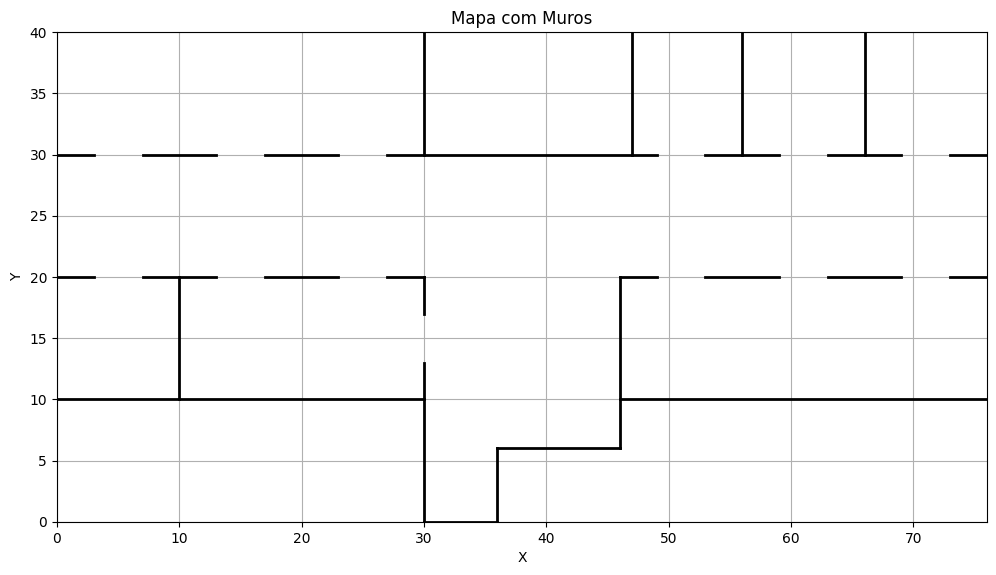

[Mur de longueur 10.0 et de position [[30, 40], [30, 30]],
 Mur de longueur 10.0 et de position [[47, 40], [47, 30]],
 Mur de longueur 10.0 et de position [[56, 40], [56, 30]],
 Mur de longueur 10.0 et de position [[66, 40], [66, 30]],
 Mur de longueur 3.0 et de position [[0, 30], [3, 30]],
 Mur de longueur 6.0 et de position [[7, 30], [13, 30]],
 Mur de longueur 6.0 et de position [[17, 30], [23, 30]],
 Mur de longueur 22.0 et de position [[27, 30], [49, 30]],
 Mur de longueur 6.0 et de position [[53, 30], [59, 30]],
 Mur de longueur 6.0 et de position [[63, 30], [69, 30]],
 Mur de longueur 3.0 et de position [[73, 30], [76, 30]],
 Mur de longueur 3.0 et de position [[0, 20], [3, 20]],
 Mur de longueur 6.0 et de position [[7, 20], [13, 20]],
 Mur de longueur 6.0 et de position [[17, 20], [23, 20]],
 Mur de longueur 3.0 et de position [[27, 20], [30, 20]],
 Mur de longueur 3.0 et de position [[46, 20], [49, 20]],
 Mur de longueur 6.0 et de position [[53, 20], [59, 20]],
 Mur de longueu

In [230]:
# import d'une disposition de murs

# FILEPATH: /C:/Mines_2A/Projet_TECHLAB/ProjectPrograms/ProjectPrograms/Astar_1robot.ipynb
# "C:\Mines_2A\Projet_TECHLAB\ProjectPrograms\ProjectPrograms\Programmes_2024\murs_techlab.xlsx"

# Lis le fichier txt
df_murs = pd.read_excel('../data/murs_techlab.xlsx', header=0)


# On créer une liste de murs
liste_murs = []
for i in range(len(df_murs)):
    position = [[df_murs.iloc[i, 0], df_murs.iloc[i, 1]],
                [df_murs.iloc[i, 2], df_murs.iloc[i, 3]]]
    liste_murs.append(Mur(position))

print(liste_murs[2])


def plot_walls(liste_murs):
    for mur in liste_murs:
        # x_inicial, x_final
        x_values = [mur.position[0][0], mur.position[1][0]]
        # y_inicial, y_final
        y_values = [mur.position[0][1], mur.position[1][1]]
        plt.plot(x_values, y_values, color='black',
                 lw=2)  # Desenha a linha do muro


# Configurar o gráfico
plt.figure(figsize=(12, 8))

# Plotar os muros
plot_walls(liste_murs)

# Ajustes para o gráfico
plt.xlim(0, 76)
plt.ylim(0, 40)
plt.gca().set_aspect('equal', adjustable='box')

# Adicionar título e rótulos
plt.title('Mapa com Muros')
plt.xlabel('X')
plt.ylabel('Y')

# Exibir o gráfico
plt.grid(True)
plt.show()
liste_murs

## Import des portes

Dans un fichier xslx qui donne les coordonnées des portes

In [231]:
# import d'une disposition de portes

# FILEPATH: /C:/Mines_2A/Projet_TECHLAB/ProjectPrograms/ProjectPrograms/Astar_1robot.ipynb
# "C:\Mines_2A\Projet_TECHLAB\ProjectPrograms\ProjectPrograms\Programmes_2024\portes_techlab.xlsx"

# Lis le fichier txt
df_portes = pd.read_excel('../data/portes_techlab.xlsx', header=0)

# On créer une liste de portes
liste_portes = []
for i in range(len(df_portes)):
    liste_portes.append(Porte([[df_portes.iloc[i, 0], df_portes.iloc[i, 1]], [
                        df_portes.iloc[i, 2], df_portes.iloc[i, 3]]], df_portes.iloc[i, 4]))

df_portes
liste_portes[8].ouvrir()
liste_portes[7].ouvrir()
liste_portes[5].ouvrir()
liste_portes[0].ouvrir()
liste_portes[4].ouvrir()
liste_portes[10].ouvrir()
liste_portes

[Porte à la position [[3, 20], [7, 20]] de largeur 4.0 et de statut ouverte,
 Porte à la position [[3, 30], [7, 30]] de largeur 4.0 et de statut fermee,
 Porte à la position [[13, 20], [17, 20]] de largeur 4.0 et de statut fermee,
 Porte à la position [[13, 30], [17, 30]] de largeur 4.0 et de statut fermee,
 Porte à la position [[23, 30], [27, 30]] de largeur 4.0 et de statut ouverte,
 Porte à la position [[49, 30], [53, 30]] de largeur 4.0 et de statut ouverte,
 Porte à la position [[59, 30], [63, 30]] de largeur 4.0 et de statut fermee,
 Porte à la position [[69, 30], [73, 30]] de largeur 4.0 et de statut ouverte,
 Porte à la position [[49, 20], [53, 20]] de largeur 4.0 et de statut ouverte,
 Porte à la position [[59, 20], [63, 20]] de largeur 4.0 et de statut fermee,
 Porte à la position [[69, 20], [73, 20]] de largeur 4.0 et de statut ouverte]

## Algoritme A*

Exemple d'execution dans la classe. Toutes les fonctions sont appelées par la methode *afficher*.

# Exemple 

# Affectation des tâches aux robots

On importe des tâches d'un Excel et on les assignent aux robots. Pour cela on utilise des graphes.

On souhaite qu'une tâche soit construite à partir de sous-tâches (intitulé, coordonées_X, coordonnées_Y, prérequis) qui nécessite une certaine fonction d'un robot. On regroupe les sous-tâches par fonctions. 

In [232]:
# on importes des tâches depuis un fichier xslx

df_sous_taches = pd.read_excel(
    "robots_taches.xlsx", header=0, sheet_name="taches")
df_robots = pd.read_excel("../data/robots_taches.xlsx", header=0, sheet_name="robots")

print(df_robots, df_sous_taches)

    Nom du robot  Depart_x  Depart_y  Taille     Fonction
0         SPOT_1        10        26       2         Bras
1         SPOT_2        60        24       2         Bras
2  UNITREE_GO1_1        38        10       1       Camera
3  UNITREE_GO1_2        40        10       1       Camera
4  UNITREE_GO1_3        42        10       1       Camera
5           R2D2        70        26       1  Thermometre
6           R5D4        72        26       1  Thermometre
7           R2D4        36        24       1   Polyvalent               Intitulé  Coord_X  Coord_Y    Prérequis  Duree
0           Surveiller       10       26       Camera      4
1           Surveiller       50       34       Camera      4
2           Surveiller       74       32       Camera      4
3           Surveiller       50       16       Camera      4
4           Surveiller       32       10       Camera      4
5           Surveiller        6       16       Camera      4
6           Surveiller        6       26       Came

In [233]:
# création des robots
liste_robots = []

for i in range(len(df_robots)):
    nom = df_robots.iloc[i, 0]
    position = [df_robots.iloc[i, 1], df_robots.iloc[i, 2]]
    taille = df_robots.iloc[i, 3]
    fonction = df_robots.iloc[i, 4]
    liste_robots.append(Robot(position, taille, nom, fonction))

liste_robots

[[Robot] SPOT_1,
 [Robot] SPOT_2,
 [Robot] UNITREE_GO1_1,
 [Robot] UNITREE_GO1_2,
 [Robot] UNITREE_GO1_3,
 [Robot] R2D2,
 [Robot] R5D4,
 [Robot] R2D4]

# Clustering

## Louvain

### Faire la comparaison entre les calcul sur le poids des arretes
### Avant j'ai utilisé 1/dist mais maintenant j'utilise exponencielle exp(-dist / sigma), où sigma est une valeur a choisir
### Apres plusieurs tests, on choisit sigma = 5 qui est l'un des plus adapte

In [336]:
def cluster_tasks_louvain(task_coords, threshold):
    """
    Cluster tasks based on their coordinates using a modularity-based approach.
    If the Louvain library is not available, fall back to a greedy modularity heuristic.
    
    Paramètres :
    - task_coords : dict (tâche_id -> (x, y))
    - threshold : distance maximale pour créer une arête entre deux tâches
    
    Retour :
    - partition : dict (tâche_id -> cluster_id)
    """
    # 1. Création du graphe de proximité
    G = nx.Graph()
    for task_id in task_coords:
        G.add_node(task_id)

    sigma = 10
    task_ids = list(task_coords.keys())
    for i in range(len(task_ids)):
        for j in range(i + 1, len(task_ids)):
            ti, tj = task_ids[i], task_ids[j]
            xi, yi = task_coords[ti]
            xj, yj = task_coords[tj]
            dist = np.linalg.norm(np.array([xi, yi]) - np.array([xj, yj]))
            if dist <= threshold:
                # Poids inverse de la distance
                weight = np.exp(-dist / sigma) 
                G.add_edge(ti, tj, weight=weight)

    # 2. Tentative d’utiliser l’algorithme de Louvain
    try:
        partition = community_louvain.best_partition(G, weight='weight')
    except ModuleNotFoundError:
        # 3. Si Louvain n’est pas installé, on utilise l’heuristique greedy
        communities = list(greedy_modularity_communities(G, weight='weight'))
        partition = {}
        for cluster_id, comm in enumerate(communities):
            for node in comm:
                partition[node] = cluster_id

    return partition

# 1. Construire un dictionnaire task_coords : tâche_id → (x, y)
task_coords = {
    idx: (row["Coord_X"], row["Coord_Y"])
    for idx, row in df_sous_taches.iterrows()
}

# 2. Appeler la fonction de clustering avec ce dictionnaire
threshold = 50 # par exemple
partition = cluster_tasks_louvain(task_coords, threshold)

# 3. Écrire le résultat dans la colonne 'Cluster'
df_sous_taches["Cluster"] = df_sous_taches.index.map(partition)

# 4. Afficher
print("Résultat du clustering :")
for idx, cluster_id in partition.items():
    print(f"  Tâche {idx} → Cluster {cluster_id}")


Résultat du clustering :
  Tâche 0 → Cluster 0
  Tâche 1 → Cluster 1
  Tâche 2 → Cluster 2
  Tâche 3 → Cluster 1
  Tâche 4 → Cluster 1
  Tâche 5 → Cluster 0
  Tâche 6 → Cluster 0
  Tâche 7 → Cluster 1
  Tâche 8 → Cluster 2
  Tâche 9 → Cluster 2
  Tâche 10 → Cluster 1
  Tâche 11 → Cluster 1
  Tâche 12 → Cluster 1
  Tâche 13 → Cluster 1
  Tâche 14 → Cluster 0
  Tâche 15 → Cluster 2
  Tâche 16 → Cluster 0
  Tâche 17 → Cluster 1
  Tâche 18 → Cluster 0
  Tâche 19 → Cluster 2
  Tâche 20 → Cluster 0
  Tâche 21 → Cluster 0
  Tâche 22 → Cluster 0
  Tâche 23 → Cluster 1
  Tâche 24 → Cluster 2
  Tâche 25 → Cluster 2
  Tâche 26 → Cluster 1
  Tâche 27 → Cluster 2
  Tâche 28 → Cluster 2


In [330]:
largeur, longueur = 40, 76
room = Piece(longueur, largeur, liste_murs, liste_portes)

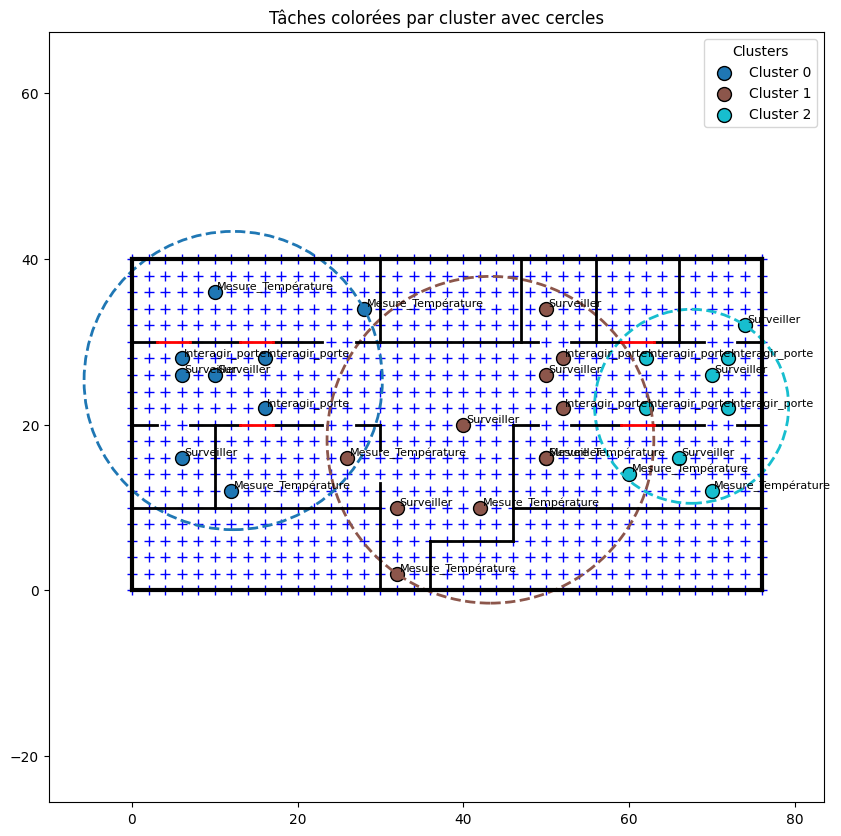

In [337]:
room.afficher_clusters(df_sous_taches)

## K-Means

In [15]:
# 1. Extraire les coordonnées des tâches
coords = df_sous_taches[['Coord_X', 'Coord_Y']].values

# 2. Définir le nombre de clusters souhaité
n_clusters = 4  # Par exemple

# 3. Appliquer K-Means
kmeans = KMeans(n_clusters=n_clusters, random_state=0)
labels = kmeans.fit_predict(coords)

# 4. Ajouter les étiquettes (clusters) au DataFrame
df_sous_taches['Cluster'] = labels

kmeans = KMeans(n_clusters=n_clusters).fit(coords)
df_sous_taches['Cluster'] = kmeans.labels_

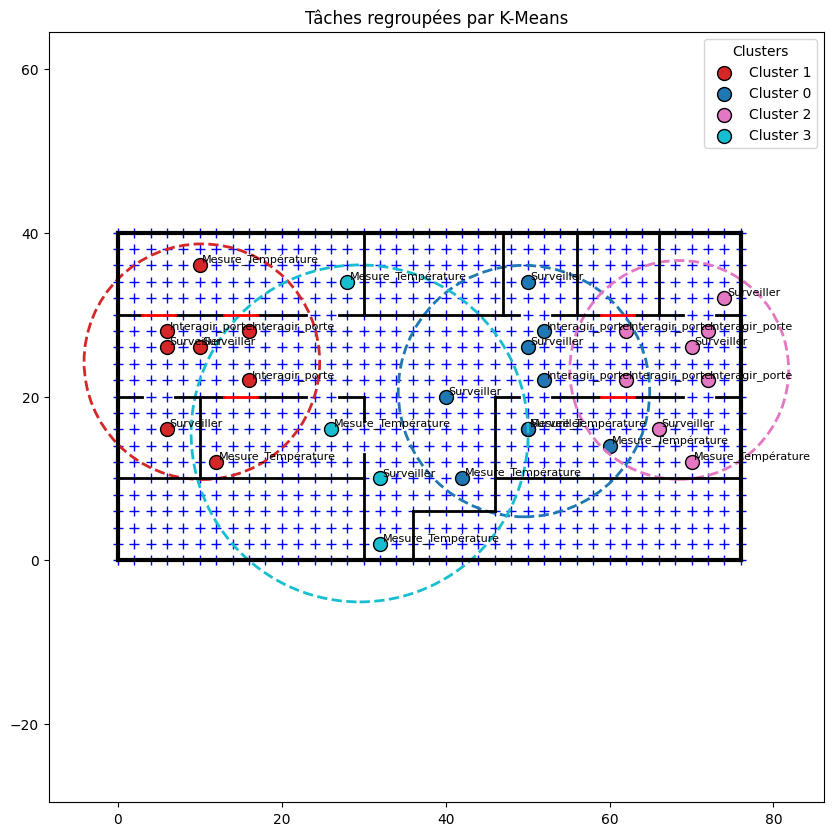

In [16]:
room1 = Piece(longueur, largeur, liste_murs, liste_portes)

room1.afficher_clusters_kmeans(df_sous_taches)

# Minimum Dominating Set (MDS)

### Changer le rapport sur cette partie la, pour qu'elle soit plus compreensible
### Ajouter dans le rapport la verification des obstacles entre les taches (Si il y a un mur ou une porte entre les taches, par example)

Distance entre 11 (26.0, 16.0) et 12 (50.0, 16.0) : 24.00
  → Pas d'arête ajoutée.
Distance entre 11 (26.0, 16.0) et 13 (32.0, 2.0) : 15.23
  → Ajout d'une arête !
Distance entre 11 (26.0, 16.0) et 14 (10.0, 36.0) : 25.61
  → Pas d'arête ajoutée.
Distance entre 11 (26.0, 16.0) et 15 (70.0, 12.0) : 44.18
  → Pas d'arête ajoutée.
Distance entre 11 (26.0, 16.0) et 16 (12.0, 12.0) : 14.56
  → Ajout d'une arête !
Distance entre 11 (26.0, 16.0) et 17 (42.0, 10.0) : 17.09
  → Ajout d'une arête !
Distance entre 11 (26.0, 16.0) et 18 (28.0, 34.0) : 18.11
  → Ajout d'une arête !
Distance entre 11 (26.0, 16.0) et 19 (60.0, 14.0) : 34.06
  → Pas d'arête ajoutée.
Distance entre 12 (50.0, 16.0) et 13 (32.0, 2.0) : 22.80
  → Pas d'arête ajoutée.
Distance entre 12 (50.0, 16.0) et 14 (10.0, 36.0) : 44.72
  → Pas d'arête ajoutée.
Distance entre 12 (50.0, 16.0) et 15 (70.0, 12.0) : 20.40
  → Pas d'arête ajoutée.
Distance entre 12 (50.0, 16.0) et 16 (12.0, 12.0) : 38.21
  → Pas d'arête ajoutée.
Distance e

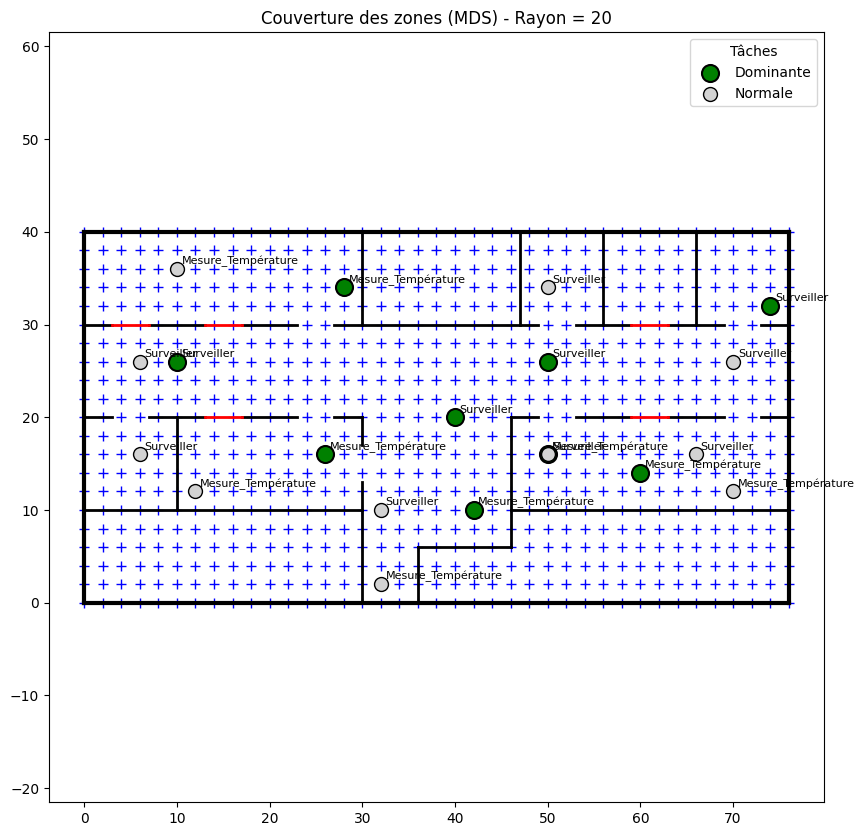

In [17]:
room2 = Piece(longueur, largeur, liste_murs, liste_portes)

# Types de tâches à couvrir
types_cibles = ["Mesure_Température", "Surveiller"]

rayon = 20  # Rayon de couverture

# Affichage visuel dans la carte
room2.afficher_mds(df_sous_taches, types_consideres=types_cibles, rayon=rayon)

Cluster 0:
  - Type 'Mesure_Température': 3 tâches
    → MDS calculé: 2 tâches dominantes sur 3
  - Type 'Surveiller': 3 tâches
    → MDS calculé: 1 tâches dominantes sur 3
  → Résumé cluster 0: 3/6 tâches dominantes (réduction: 50.0%)

Cluster 1:
  - Type 'Mesure_Température': 4 tâches
    → Aucune connexion (rayon trop petit): toutes les 4 tâches restent dominantes
  - Type 'Surveiller': 5 tâches
    → MDS calculé: 3 tâches dominantes sur 5
  → Résumé cluster 1: 7/9 tâches dominantes (réduction: 22.2%)

Cluster 2:
  - Type 'Mesure_Température': 2 tâches
    → MDS calculé: 1 tâches dominantes sur 2
  - Type 'Surveiller': 3 tâches
    → Aucune connexion (rayon trop petit): toutes les 3 tâches restent dominantes
  → Résumé cluster 2: 4/5 tâches dominantes (réduction: 20.0%)



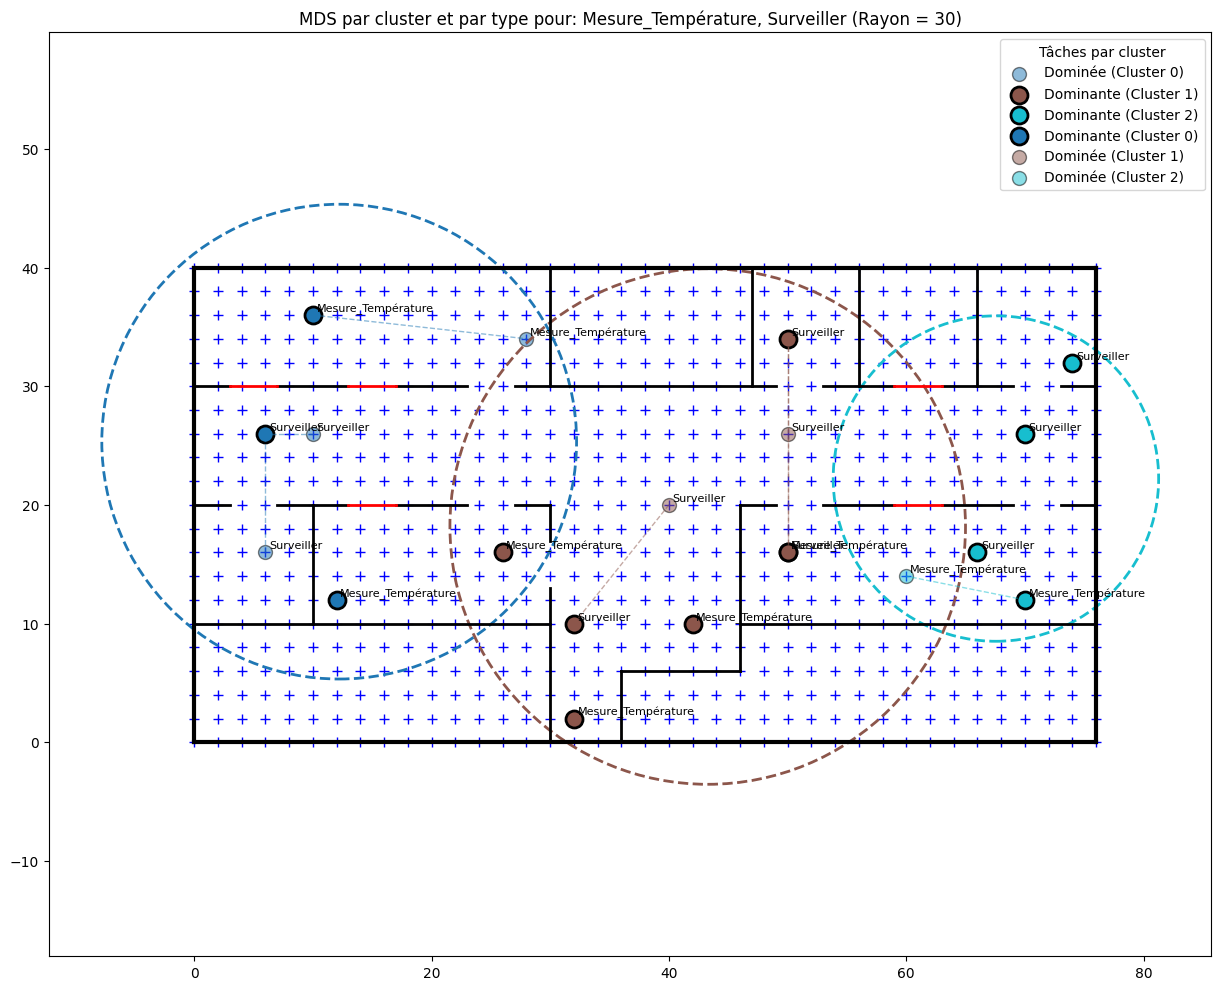

In [237]:
room3 = Piece(longueur, largeur, liste_murs, liste_portes)

types_cibles = ["Mesure_Température", "Surveiller"]

mds_total = room3.trouver_mds_par_cluster_et_type(df_sous_taches, types_consideres=types_cibles, rayon=30)

Attention: L'environnement contient des régions déconnectées.
Nombre de régions déconnectées: 5
Attention: 1 lieux sont inaccessibles.
  Lieu inaccessible (35, 30) remplacé par (34, 28)
Erreur lors de la planification: list index out of range
Tentative de planification alternative...
Essai avec une grille plus fine...
Attention: L'environnement contient des régions déconnectées.
Nombre de régions déconnectées: 5
Attention: 1 lieux sont inaccessibles.
  Lieu inaccessible (35, 30) remplacé par (35.0, 29.0)
Attention: L'environnement contient des régions déconnectées.
Nombre de régions déconnectées: 5
Le point de départ n'est pas dans une région accessible.
Attention: 2 lieux sont inaccessibles.
  Lieu inaccessible (60, 30) remplacé par (60, 28)
  Lieu inaccessible (60, 10) remplacé par (60, 12)


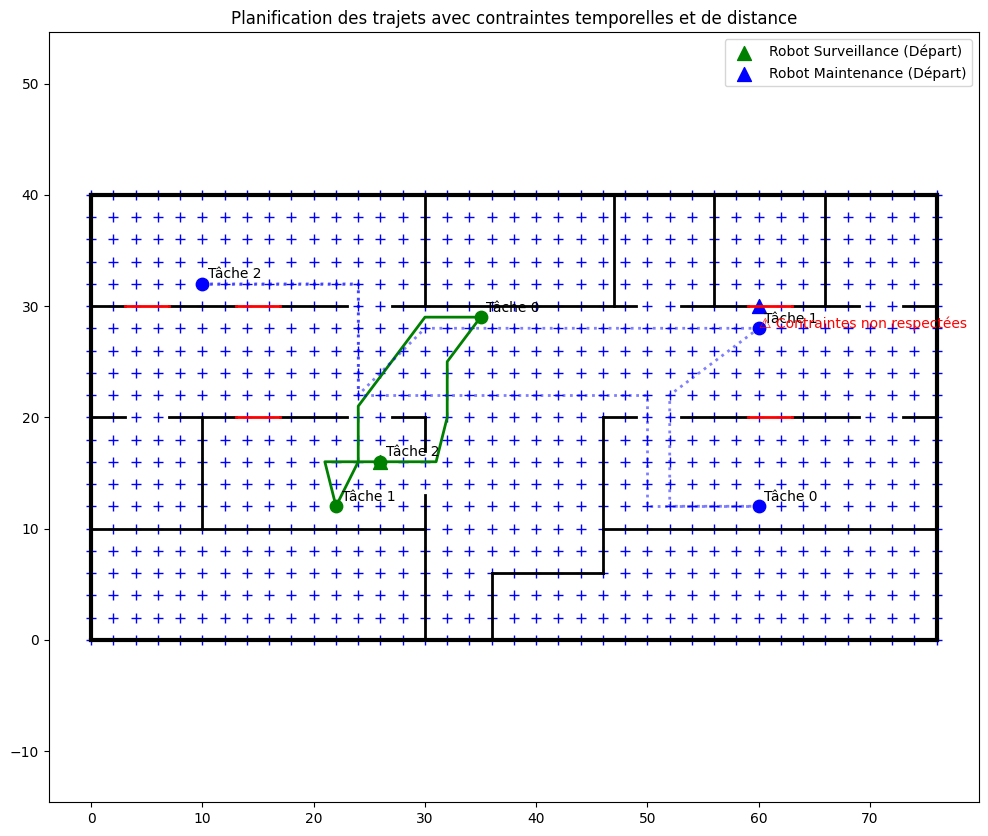


Résumé de la planification:
Robot Surveillance: ✅ OK
  - Distance: 52.72 / 100
  - Temps: 00:33 / 09:00

Robot Maintenance: ❌ Impossible
  - Distance: 160.49 / 50
  - Temps: 00:00 / 08:30



In [19]:
# Créer la pièce
piece = Piece(longueur, largeur, liste_murs, liste_portes)

# Définir des tâches avec des durées réalistes
tache1 = Tache("Surveillance Zone A", [[22, 12]], ["surveiller"], "surveillance", duree=3)
tache2 = Tache("Mesure Température Zone B", [[35, 30]], ["mesurer"], "mesure", duree=4)
tache3 = Tache("Nettoyage Zone C", [[60, 10]], ["nettoyer"], "nettoyage", duree=4)
tache4 = Tache("Maintenance Zone D", [[10, 32]], ["maintenir"], "maintenance", duree=6)

# Créer des robots avec des contraintes réalistes
robot1 = Robot(
    position=[26, 16], 
    taille=1, 
    nom="Robot Surveillance", 
    fonction="surveillance",
    distance_max=100,          # 100 unités max par jour
    heure_debut=(8, 0),        # Commence à 8h00
    heure_fin=(17, 0),         # Finit à 17h00
    vitesse=2.0                # 2 unités par minute
)

robot2 = Robot(
    position=[60, 30], 
    taille=1, 
    nom="Robot Maintenance", 
    fonction="maintenance",
    distance_max=50,           # 50 unités max par jour
    heure_debut=(9, 30),       # Commence à 9h30
    heure_fin=(18, 0),         # Finit à 18h00
    vitesse=1.5                # 1.5 unités par minute
)

# Affecter les tâches aux robots selon leurs fonctions
robot1.taches = [tache1, tache2]  # Surveillance et mesure
robot2.taches = [tache3, tache4]  # Nettoyage et maintenance

# Associer les robots à la pièce
piece.associer_robot(robot1)
piece.associer_robot(robot2)

# Planifier avec contraintes
resultats = piece.planifier_avec_contraintes([robot1, robot2])

# Afficher les résultats
piece.afficher_planification(resultats)

In [20]:
def debug_compatibilite(liste_robots, df_tasks):
    """
    Debug détaillé de la compatibilité robot-tâche
    """
    print("🔍 DEBUG COMPATIBILITÉ DÉTAILLÉ")
    print("=" * 50)
    
    # 1. Vérifier les colonnes disponibles
    print("📊 Colonnes disponibles:")
    print(f"   df_tasks: {list(df_tasks.columns)}")
    
    # 2. Vérifier les fonctions des robots
    print(f"\n🤖 Fonctions des robots:")
    for robot in liste_robots:
        print(f"   {robot.nom}: '{robot.fonction}' (type: {type(robot.fonction)})")
    
    # 3. Vérifier les prérequis des tâches
    print(f"\n📋 Prérequis des tâches:")
    
    # Identifier la bonne colonne pour les prérequis
    colonnes_possibles = ['Prérequis', 'prerequis', 'Prerequis', 'prérequis']
    colonne_prerequis = None
    
    for col in colonnes_possibles:
        if col in df_tasks.columns:
            colonne_prerequis = col
            break
    
    if colonne_prerequis is None:
        print("   ❌ ERREUR: Aucune colonne de prérequis trouvée!")
        print(f"   Colonnes disponibles: {list(df_tasks.columns)}")
        return
    
    print(f"   Colonne utilisée: '{colonne_prerequis}'")
    
    # Afficher un échantillon des prérequis
    prerequis_uniques = df_tasks[colonne_prerequis].unique()
    print(f"   Prérequis uniques: {list(prerequis_uniques)}")
    
    # Afficher quelques exemples
    print(f"\n   Échantillon de tâches:")
    for idx in df_tasks.index[:10]:  # Premiers 10
        tache_info = df_tasks.loc[idx]
        prerequis = tache_info[colonne_prerequis]
        intitule = tache_info.get('Intitulé', 'N/A')
        print(f"      Tâche {idx}: '{intitule}' → prérequis: '{prerequis}' (type: {type(prerequis)})")
    
    # 4. Tester la compatibilité pour des cas spécifiques
    print(f"\n🔧 Test de compatibilité spécifique:")
    
    # Chercher le robot SPOT
    robot_spot = None
    for robot in liste_robots:
        if robot.nom == "SPOT":
            robot_spot = robot
            break
    
    if robot_spot:
        print(f"   Robot SPOT trouvé: fonction = '{robot_spot.fonction}'")
        
        # Chercher les tâches "Interagir_porte"
        taches_interagir = df_tasks[df_tasks['Intitulé'] == 'Interagir_porte']
        print(f"   Tâches 'Interagir_porte' trouvées: {len(taches_interagir)}")
        
        for idx, tache_info in taches_interagir.iterrows():
            prerequis = tache_info[colonne_prerequis]
            print(f"      Tâche {idx}: prérequis = '{prerequis}' (type: {type(prerequis)})")
            
            # Test de compatibilité
            compatible = (robot_spot.fonction == prerequis)
            print(f"      Compatibilité: '{robot_spot.fonction}' == '{prerequis}' → {compatible}")
            
            # Test avec strip() au cas où il y aurait des espaces
            if isinstance(robot_spot.fonction, str) and isinstance(prerequis, str):
                compatible_strip = (robot_spot.fonction.strip() == prerequis.strip())
                print(f"      Compatibilité (avec strip): '{robot_spot.fonction.strip()}' == '{prerequis.strip()}' → {compatible_strip}")
    
    # 5. Matrice de compatibilité complète
    print(f"\n📊 Matrice de compatibilité:")
    
    for robot in liste_robots:
        taches_compatibles = []
        for idx, tache_info in df_tasks.iterrows():
            prerequis = tache_info[colonne_prerequis]
            
            # Test de compatibilité
            if pd.isna(prerequis) or prerequis == "None" or prerequis == "":
                compatible = True  # Pas de prérequis
            elif robot.fonction == "Polyvalent":
                compatible = True  # Robot polyvalent
            elif isinstance(robot.fonction, str) and isinstance(prerequis, str):
                compatible = (robot.fonction.strip().lower() == prerequis.strip().lower())
            else:
                compatible = (robot.fonction == prerequis)
            
            if compatible:
                taches_compatibles.append(idx)
        
        print(f"   {robot.nom} ('{robot.fonction}'): {len(taches_compatibles)} tâches compatibles")
        if len(taches_compatibles) > 0:
            print(f"      Exemples: {taches_compatibles[:5]}")

def verifier_compatibilite(robot, tache_id, df_tasks):
    """
    Version corrigée de la vérification de compatibilité
    """
    import pandas as pd
    
    # Récupérer les informations de la tâche
    tache_info = df_tasks.loc[tache_id]
    
    # Identifier la bonne colonne pour les prérequis
    colonnes_possibles = ['Prérequis', 'prerequis', 'Prerequis', 'prérequis']
    colonne_prerequis = None
    
    for col in colonnes_possibles:
        if col in df_tasks.columns:
            colonne_prerequis = col
            break
    
    if colonne_prerequis is None:
        print(f"⚠️  ATTENTION: Aucune colonne de prérequis trouvée dans {list(df_tasks.columns)}")
        return True  # Par défaut, compatible
    
    # Récupérer le prérequis de la tâche
    tache_prerequis = tache_info[colonne_prerequis]
    
    # Récupérer la fonction du robot
    robot_fonction = robot.fonction
    
    # Vérifier la compatibilité
    if pd.isna(tache_prerequis) or tache_prerequis == "None" or tache_prerequis == "":
        # Tâche sans prérequis → tous les robots peuvent la faire
        return True
    elif robot_fonction == "Polyvalent" or robot_fonction == "polyvalent":
        # Robot polyvalent → peut faire toutes les tâches
        return True
    elif isinstance(robot_fonction, str) and isinstance(tache_prerequis, str):
        # Comparaison en ignorant la casse et les espaces
        return robot_fonction.strip().lower() == tache_prerequis.strip().lower()
    else:
        # Correspondance exacte
        return robot_fonction == tache_prerequis

# === UTILISATION DU DEBUG ===

# 1. Lancer le debug
debug_compatibilite(liste_robots, df_sous_taches)

# 2. Tester la fonction corrigée
print(f"\n🧪 TEST DE LA FONCTION CORRIGÉE:")

robot_spot = None
for robot in liste_robots:
    if robot.nom == "SPOT":
        robot_spot = robot
        break

if robot_spot:
    # Tester avec une tâche spécifique
    taches_interagir = df_sous_taches[df_sous_taches['Intitulé'] == 'Interagir_porte']
    if not taches_interagir.empty:
        tache_test_id = taches_interagir.index[0]
        compatible = verifier_compatibilite(robot_spot, tache_test_id, df_sous_taches)
        print(f"SPOT peut faire la tâche {tache_test_id} (Interagir_porte): {compatible}")

def calculer_cout_robot_tache(robot, tache_id, df_tasks):
    """
    Calcule le coût pour un robot d'effectuer une tâche
    Utilise la colonne 'Duree' du DataFrame
    """
    tache_info = df_tasks.loc[tache_id]
    tache_pos = [tache_info['Coord_X'], tache_info['Coord_Y']]
    
    # Distance du robot à la tâche
    distance = np.sqrt((robot.position[0] - tache_pos[0])**2 + 
                      (robot.position[1] - tache_pos[1])**2)
    
    # Temps de déplacement
    vitesse = getattr(robot, 'vitesse', 2.0)  # Vitesse par défaut
    temps_deplacement = distance / vitesse
    
    # Temps d'exécution (colonne 'Duree' du DataFrame)
    temps_execution = tache_info['Duree']
    
    # Coût total = temps de déplacement + temps d'exécution
    cout_total = temps_deplacement + temps_execution
    
    return cout_total, distance, temps_deplacement, temps_execution

🔍 DEBUG COMPATIBILITÉ DÉTAILLÉ
📊 Colonnes disponibles:
   df_tasks: ['Intitulé', 'Coord_X', 'Coord_Y', 'Prérequis', 'Duree', 'Cluster']

🤖 Fonctions des robots:
   SPOT: 'Bras' (type: <class 'str'>)
   UNITREE_GO1_1: 'Camera' (type: <class 'str'>)
   UNITREE_GO1_2: 'Camera' (type: <class 'str'>)
   UNITREE_GO1_3: 'Camera' (type: <class 'str'>)
   R2D2: 'Thermometre' (type: <class 'str'>)
   R5D4: 'Thermometre' (type: <class 'str'>)

📋 Prérequis des tâches:
   Colonne utilisée: 'Prérequis'
   Prérequis uniques: ['Camera', 'Thermometre', 'Bras']

   Échantillon de tâches:
      Tâche 0: 'Surveiller' → prérequis: 'Camera' (type: <class 'str'>)
      Tâche 1: 'Surveiller' → prérequis: 'Camera' (type: <class 'str'>)
      Tâche 2: 'Surveiller' → prérequis: 'Camera' (type: <class 'str'>)
      Tâche 3: 'Surveiller' → prérequis: 'Camera' (type: <class 'str'>)
      Tâche 4: 'Surveiller' → prérequis: 'Camera' (type: <class 'str'>)
      Tâche 5: 'Surveiller' → prérequis: 'Camera' (type: <class

# Affectation

### Affectation à plusieurs clusters

In [333]:
liste_robots_contrainte_1 = [robot for robot in liste_robots if robot.nom not in ["SPOT_2", "R2D4"]]

liste_robots_contrainte_1

[[Robot] SPOT_1,
 [Robot] UNITREE_GO1_1,
 [Robot] UNITREE_GO1_2,
 [Robot] UNITREE_GO1_3,
 [Robot] R2D2,
 [Robot] R5D4]

In [338]:
def affectation_dynamique_robots_avec_mds(liste_robots, clusters_mds, df_tasks, 
                                                 types_mds, gamma=1.0, un_robot_par_cluster=False):
    """
    Version corrigée qui utilise seulement les tâches dominantes pour les types MDS
    et toutes les tâches pour les autres types
    
    Paramètres:
    -----------
    liste_robots : list
        Liste complète des robots disponibles
    clusters_mds : dict
        Résultats du MDS par cluster (seulement les tâches dominantes)
    df_tasks : DataFrame
        DataFrame avec toutes les tâches
    types_mds : list
        Types de tâches pour lesquels le MDS a été appliqué (ex: ["Surveiller", "Mesure_Température"])
    gamma : float
        Pénalité pour l'utilisation de points de couverture
    un_robot_par_cluster : bool
        Si True, limite chaque robot à un seul cluster
        
    Retourne:
    ---------
    dict
        Résultats complets de l'affectation
    """
    
    print("=== AFFECTATION AVEC MDS CORRECT ===")
    print(f"Robots disponibles: {len(liste_robots)}")
    print(f"Types avec MDS: {types_mds}")
    
    # Afficher les fonctions des robots
    print(f"\n🤖 Fonctions des robots:")
    for robot in liste_robots:
        print(f"   {robot.nom}: {robot.fonction}")
    
    # Préparation des données
    N = len(liste_robots)
    clusters_ids = list(clusters_mds.keys())
    K = len(clusters_ids)
    
    # === CONSTRUCTION DE LA LISTE DES TÂCHES À AFFECTER ===
    
    taches_a_affecter = set()
    
    print(f"\n📋 Construction de la liste des tâches à affecter:")
    
    for cluster_id in clusters_ids:
        print(f"\n🏘️  Cluster {cluster_id}:")
        
        # Toutes les tâches de ce cluster
        taches_cluster = df_tasks[df_tasks['Cluster'] == cluster_id]
        
        # 1. Tâches dominantes (MDS) pour les types concernés
        taches_dominantes_cluster = clusters_mds[cluster_id]
        print(f"   Tâches dominantes (MDS): {len(taches_dominantes_cluster)}")
        
        for tache_id in taches_dominantes_cluster:
            tache_info = df_tasks.loc[tache_id]
            type_tache = tache_info['Intitulé']
            
            if type_tache in types_mds:
                taches_a_affecter.add(tache_id)
                print(f"   ✅ Tâche {tache_id} ({type_tache}) - DOMINANTE ajoutée")
        
        # 2. Toutes les tâches des autres types (non-MDS)
        for tache_id, tache_info in taches_cluster.iterrows():
            type_tache = tache_info['Intitulé']
            
            if type_tache not in types_mds:
                taches_a_affecter.add(tache_id)
                print(f"   ✅ Tâche {tache_id} ({type_tache}) - AUTRE TYPE ajoutée")
    
    # Convertir en liste ordonnée
    toutes_taches = sorted(list(taches_a_affecter))
    M = len(toutes_taches)
    
    print(f"\n📊 RÉSUMÉ:")
    print(f"   Tâches totales dans df_tasks: {len(df_tasks)}")
    print(f"   Tâches à affecter: {M}")
    
    # Statistiques par type
    types_stats = {}
    for tache_id in toutes_taches:
        type_tache = df_tasks.loc[tache_id]['Intitulé']
        if type_tache not in types_stats:
            types_stats[type_tache] = {'total': 0, 'mds': type_tache in types_mds}
        types_stats[type_tache]['total'] += 1
    
    print(f"\n📈 Statistiques par type:")
    for type_tache, stats in types_stats.items():
        status = "MDS (dominantes seulement)" if stats['mds'] else "TOUTES"
        print(f"   {type_tache}: {stats['total']} tâches ({status})")
    
    if M == 0:
        print("❌ Aucune tâche à affecter!")
        return {'status': 'failed', 'message': 'Aucune tâche à affecter'}
    
    # === FONCTION DE COMPATIBILITÉ ===
    
    def verifier_compatibilite_finale(robot, tache_id, df_tasks):
        """Version finale de la vérification de compatibilité"""
        tache_info = df_tasks.loc[tache_id]
        tache_prerequis = tache_info['Prérequis']
        robot_fonction = robot.fonction
        
        if pd.isna(tache_prerequis) or tache_prerequis == "None" or tache_prerequis == "":
            return True
        elif robot_fonction == "Polyvalent" or robot_fonction == "polyvalent":
            return True
        elif isinstance(robot_fonction, str) and isinstance(tache_prerequis, str):
            return robot_fonction.strip().lower() == tache_prerequis.strip().lower()
        else:
            return robot_fonction == tache_prerequis
    
    def calculer_cout_finale(robot, tache_id, df_tasks):
        """Calcule le coût avec la colonne Duree"""
        tache_info = df_tasks.loc[tache_id]
        tache_pos = [tache_info['Coord_X'], tache_info['Coord_Y']]
        
        distance = np.sqrt((robot.position[0] - tache_pos[0])**2 + 
                          (robot.position[1] - tache_pos[1])**2)
        
        vitesse = getattr(robot, 'vitesse', 2.0)
        temps_deplacement = distance / vitesse
        temps_execution = tache_info['Duree']
        cout_total = temps_deplacement + temps_execution
        
        return cout_total
    
    # === CRÉER LE PROBLÈME ===
    
    prob = pulp.LpProblem("Affectation_Robots_MDS_Correct", pulp.LpMinimize)
    
    # === VARIABLES ===
    
    # z[i,k] : robot i affecté au cluster k
    z = {}
    for i, robot in enumerate(liste_robots):
        for k, cluster_id in enumerate(clusters_ids):
            z[i, k] = pulp.LpVariable(f"z_{i}_{k}", cat='Binary')
    
    # x[i,j] : robot i effectue la tâche j
    x = {}
    for i, robot in enumerate(liste_robots):
        for j, tache_id in enumerate(toutes_taches):
            x[i, j] = pulp.LpVariable(f"x_{i}_{j}", cat='Binary')
    
    # === CALCUL DES COÛTS ET COMPATIBILITÉS ===
    
    print(f"\n🔧 Calcul des compatibilités:")
    
    c = {}  # Coûts
    E = {}  # Compatibilités
    compatibilites_par_robot = {}
    
    for i, robot in enumerate(liste_robots):
        compatibilites_par_robot[robot.nom] = []
        
        for j, tache_id in enumerate(toutes_taches):
            cout = calculer_cout_finale(robot, tache_id, df_tasks)
            c[i, j] = cout
            
            compatible = verifier_compatibilite_finale(robot, tache_id, df_tasks)
            E[i, j] = 1 if compatible else 0
            
            if compatible:
                compatibilites_par_robot[robot.nom].append(tache_id)
    
    # Afficher les compatibilités
    for robot_nom, taches_compatibles in compatibilites_par_robot.items():
        print(f"   {robot_nom}: {len(taches_compatibles)} tâches compatibles")
    
    # Vérifier qu'il n'y a pas de tâches sans robot compatible
    taches_sans_robot = []
    for j, tache_id in enumerate(toutes_taches):
        robots_compatibles = [i for i in range(N) if E[i, j] == 1]
        if not robots_compatibles:
            taches_sans_robot.append(tache_id)
    
    if taches_sans_robot:
        print(f"\n❌ ERREUR: {len(taches_sans_robot)} tâches sans robot compatible!")
        print(f"Tâches problématiques: {taches_sans_robot}")
        return {'status': 'failed', 'message': 'Tâches sans robot compatible'}
    
    # === FONCTION OBJECTIF ===
    
    prob += pulp.lpSum([c[i, j] * x[i, j] for i in range(N) for j in range(M)])
    
    # === CONTRAINTES ===
    
    # 1. Chaque tâche doit être effectuée par exactement un robot
    for j, tache_id in enumerate(toutes_taches):
        prob += pulp.lpSum([x[i, j] for i in range(N)]) == 1, f"Tache_{j}_effectuee"
    
    # 2. Chaque cluster doit avoir au moins un robot
    for k, cluster_id in enumerate(clusters_ids):
        prob += pulp.lpSum([z[i, k] for i in range(N)]) >= 1, f"Au_moins_un_robot_cluster_{k}"
    
    # 3. Capacité des robots (nombre de tâches)
    for i, robot in enumerate(liste_robots):
        capacite_max = getattr(robot, 'capacite_max', 15)
        prob += pulp.lpSum([x[i, j] for j in range(M)]) <= capacite_max, f"Capacite_robot_{i}"
    
    # 4. Limite de temps de travail
    for i, robot in enumerate(liste_robots):
        temps_max = getattr(robot, 'temps_max', 600)
        prob += pulp.lpSum([c[i, j] * x[i, j] for j in range(M)]) <= temps_max, f"Temps_robot_{i}"
    
    # 5. Compatibilité robot-tâche
    for i in range(N):
        for j in range(M):
            prob += x[i, j] <= E[i, j], f"Compatibilite_{i}_{j}"
    
    # 6. Lien cluster-tâche
    for i in range(N):
        for j, tache_id in enumerate(toutes_taches):
            cluster_de_tache = df_tasks.loc[tache_id]['Cluster']
            cluster_index = clusters_ids.index(cluster_de_tache)
            prob += x[i, j] <= z[i, cluster_index], f"Lien_cluster_tache_{i}_{j}"
    
    # 7. OPTION : Un robot par cluster maximum
    if un_robot_par_cluster:
        for i, robot in enumerate(liste_robots):
            prob += pulp.lpSum([z[i, k] for k in range(K)]) <= 1, f"Robot_{i}_un_seul_cluster"
    
    # === RÉSOLUTION ===
    
    print(f"\nRésolution du problème...")
    prob.solve(pulp.PULP_CBC_CMD(msg=0))
    
    if prob.status == pulp.LpStatusOptimal:
        print("✅ Solution optimale trouvée !")
        
        # === EXTRAIRE LES RÉSULTATS ===
        
        resultats = {
            'status': 'optimal',
            'cout_total': pulp.value(prob.objective),
            'affectation_clusters': {},
            'affectation_taches': {},
            'robots_utilises': set(),
            'taches_couvertes': set(),
            'details_robots': {},
            'taches_affectees': toutes_taches,  # Liste des tâches effectivement affectées
            'types_mds': types_mds  # Types pour lesquels MDS a été appliqué
        }
        
        # Affectation robots-clusters
        for i, robot in enumerate(liste_robots):
            clusters_robot = []
            for k, cluster_id in enumerate(clusters_ids):
                if pulp.value(z[i, k]) == 1:
                    clusters_robot.append(cluster_id)
                    if cluster_id not in resultats['affectation_clusters']:
                        resultats['affectation_clusters'][cluster_id] = []
                    resultats['affectation_clusters'][cluster_id].append(robot.nom)
            
            if clusters_robot:
                resultats['robots_utilises'].add(robot.nom)
                resultats['details_robots'][robot.nom] = {
                    'clusters': clusters_robot,
                    'taches': [],
                    'cout_total': 0,
                    'temps_total': 0
                }
        
        # Affectation robots-tâches
        for i, robot in enumerate(liste_robots):
            taches_robot = []
            cout_robot = 0
            
            for j, tache_id in enumerate(toutes_taches):
                if pulp.value(x[i, j]) == 1:
                    taches_robot.append(tache_id)
                    resultats['taches_couvertes'].add(tache_id)
                    cout_robot += c[i, j]
            
            if taches_robot:
                resultats['affectation_taches'][robot.nom] = taches_robot
                if robot.nom in resultats['details_robots']:
                    resultats['details_robots'][robot.nom]['taches'] = taches_robot
                    resultats['details_robots'][robot.nom]['cout_total'] = cout_robot
        
        # === AFFICHAGE DES RÉSULTATS ===
        
        print(f"\n💰 Coût total optimal: {resultats['cout_total']:.2f}")
        print(f"🤖 Robots utilisés: {len(resultats['robots_utilises'])}/{N}")
        print(f"📋 Tâches couvertes: {len(resultats['taches_couvertes'])}/{M}")
        
        print(f"\n=== AFFECTATION ROBOTS-CLUSTERS ===")
        for cluster_id, robots_affectes in resultats['affectation_clusters'].items():
            print(f"Cluster {cluster_id}: {', '.join(robots_affectes)}")
        
        print(f"\n=== AFFECTATION ROBOTS-TÂCHES ===")
        for robot_nom, taches in resultats['affectation_taches'].items():
            robot_obj = next(r for r in liste_robots if r.nom == robot_nom)
            print(f"{robot_nom} ({robot_obj.fonction}): {len(taches)} tâches")
            
            # Détails des tâches par type
            taches_par_type = {}
            for tache_id in taches:
                tache_info = df_tasks.loc[tache_id]
                type_tache = tache_info['Intitulé']
                if type_tache not in taches_par_type:
                    taches_par_type[type_tache] = []
                taches_par_type[type_tache].append(tache_id)
            
            for type_tache, taches_type in taches_par_type.items():
                status_mds = " (MDS)" if type_tache in types_mds else ""
                print(f"   - {type_tache}{status_mds}: {len(taches_type)} tâches")
                
                # Afficher quelques exemples
                for tache_id in taches_type[:2]:  # Afficher les 2 premières
                    tache_info = df_tasks.loc[tache_id]
                    print(f"     • Tâche {tache_id}: prérequis {tache_info['Prérequis']}, durée {tache_info['Duree']}min")
                
                if len(taches_type) > 2:
                    print(f"     • ... et {len(taches_type) - 2} autres")
        
        # === VÉRIFICATION DE LA LOGIQUE MDS ===
        
        print(f"\n=== VÉRIFICATION MDS ===")
        for type_tache in types_mds:
            # Compter les tâches de ce type dans le DataFrame original
            taches_originales = len(df_tasks[df_tasks['Intitulé'] == type_tache])
            
            # Compter les tâches de ce type affectées
            taches_affectees_type = 0
            for tache_id in toutes_taches:
                if df_tasks.loc[tache_id]['Intitulé'] == type_tache:
                    taches_affectees_type += 1
            
            reduction = ((taches_originales - taches_affectees_type) / taches_originales * 100) if taches_originales > 0 else 0
            
            print(f"{type_tache}: {taches_originales} → {taches_affectees_type} (réduction: {reduction:.1f}%)")
        
        return resultats
    
    else:
        print(f"❌ Problème non résolu. Status: {pulp.LpStatus[prob.status]}")
        return {'status': 'failed', 'message': pulp.LpStatus[prob.status]}

# === UTILISATION COMPLÈTE ===

# Types pour lesquels le MDS a été appliqué
types_avec_mds = ["Surveiller", "Mesure_Température"]

# Lancer l'affectation corrigée
resultats = affectation_dynamique_robots_avec_mds(
    liste_robots_contrainte_1, mds_total, df_sous_taches, types_avec_mds, 
    gamma=1.0, un_robot_par_cluster=False
)

print(f"\n🎯 RÉSULTAT FINAL:")
if resultats['status'] == 'optimal':
    print(f"✅ Affectation réussie avec {len(resultats['taches_affectees'])} tâches")
    print(f"📊 Types MDS: {resultats['types_mds']}")
    print(f"💰 Coût total: {resultats['cout_total']:.2f}")
else:
    print(f"❌ Échec: {resultats['message']}")


=== AFFECTATION AVEC MDS CORRECT ===
Robots disponibles: 6
Types avec MDS: ['Surveiller', 'Mesure_Température']

🤖 Fonctions des robots:
   SPOT_1: Bras
   UNITREE_GO1_1: Camera
   UNITREE_GO1_2: Camera
   UNITREE_GO1_3: Camera
   R2D2: Thermometre
   R5D4: Thermometre

📋 Construction de la liste des tâches à affecter:

🏘️  Cluster 0:
   Tâches dominantes (MDS): 3
   ✅ Tâche 16 (Mesure_Température) - DOMINANTE ajoutée
   ✅ Tâche 14 (Mesure_Température) - DOMINANTE ajoutée
   ✅ Tâche 6 (Surveiller) - DOMINANTE ajoutée
   ✅ Tâche 20 (Interagir_porte) - AUTRE TYPE ajoutée
   ✅ Tâche 21 (Interagir_porte) - AUTRE TYPE ajoutée
   ✅ Tâche 22 (Interagir_porte) - AUTRE TYPE ajoutée

🏘️  Cluster 1:
   Tâches dominantes (MDS): 7
   ✅ Tâche 17 (Mesure_Température) - DOMINANTE ajoutée
   ✅ Tâche 1 (Surveiller) - DOMINANTE ajoutée
   ✅ Tâche 3 (Surveiller) - DOMINANTE ajoutée
   ✅ Tâche 4 (Surveiller) - DOMINANTE ajoutée
   ✅ Tâche 11 (Mesure_Température) - DOMINANTE ajoutée
   ✅ Tâche 12 (Mesure_Te

=== TEST AVEC 2 ROBOTS ===
🎯 Visualisation avec TSP de 6 robots: ['UNITREE_GO1_2', 'UNITREE_GO1_1', 'R2D2', 'SPOT_1', 'R5D4', 'UNITREE_GO1_3']
🤖 SPOT_1: 9 tâches affectées
🤖 UNITREE_GO1_1: 2 tâches affectées
🤖 UNITREE_GO1_3: 5 tâches affectées
🤖 R2D2: 7 tâches affectées
\n🎨 Génération de la visualisation avec TSP...
🔄 Calcul du chemin pour SPOT_1...
Attention: L'environnement contient des régions déconnectées.
Nombre de régions déconnectées: 5
Erreur lors de la planification: list index out of range
Tentative de planification alternative...
Essai avec une grille plus fine...
Attention: L'environnement contient des régions déconnectées.
Nombre de régions déconnectées: 5
✅ SPOT_1: Chemin affiché avec succès
🔄 Calcul du chemin pour UNITREE_GO1_1...
Attention: L'environnement contient des régions déconnectées.
Nombre de régions déconnectées: 5
Erreur lors de la planification: list index out of range
Tentative de planification alternative...
Essai avec une grille plus fine...
Attention: L'e

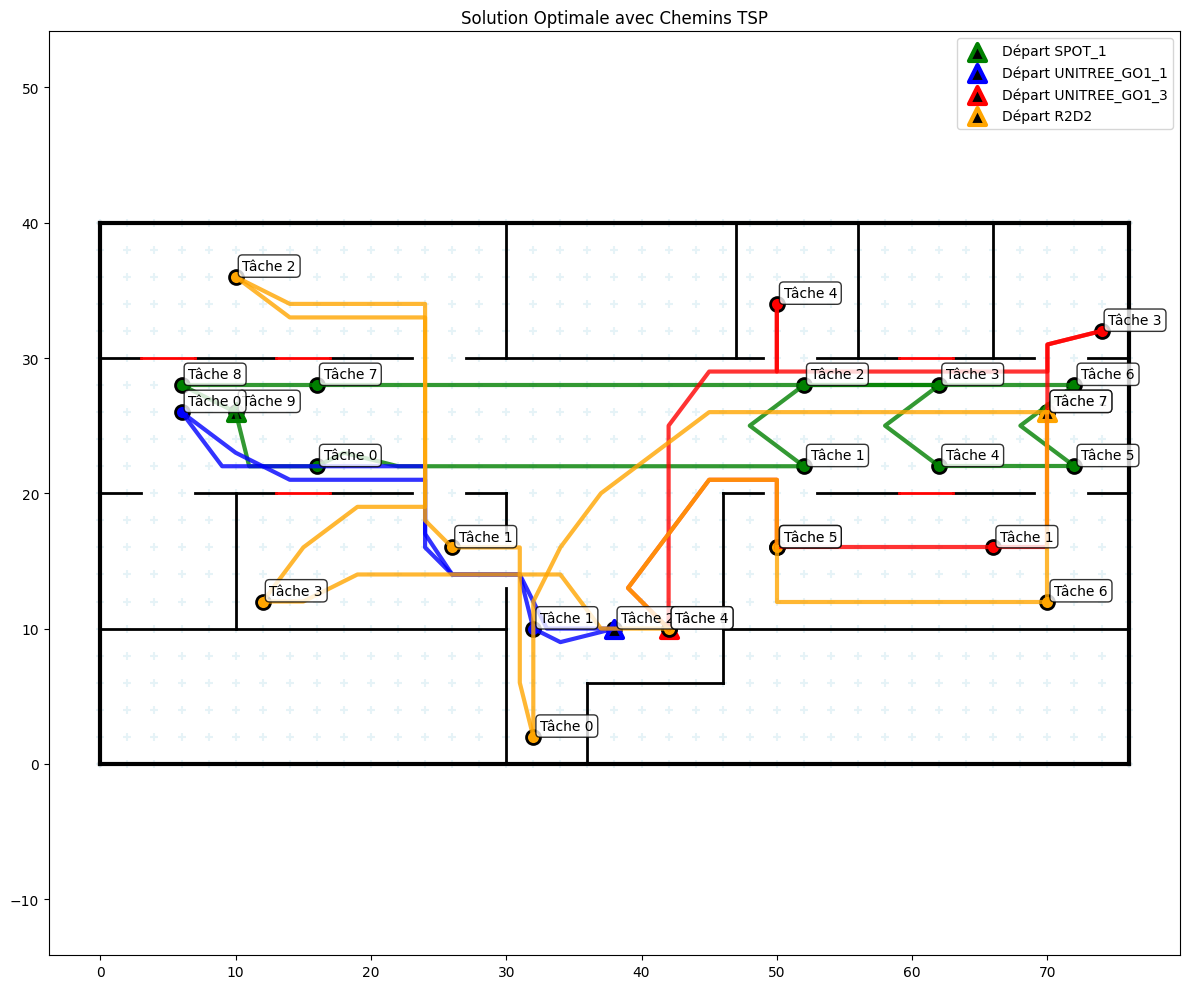

\n📊 INFORMATIONS SUR LA SOLUTION:
💰 Coût total optimal: 897.66
🤖 Robots visualisés: 4
\n🤖 SPOT_1 (Bras):
   - Clusters: [0, 1, 2]
   - Tâches: 9
   - Coût: 375.60
\n🤖 UNITREE_GO1_1 (Camera):
   - Clusters: [0, 1, 2]
   - Tâches: 2
   - Coût: 49.78
\n🤖 UNITREE_GO1_3 (Camera):
   - Clusters: [0, 1, 2]
   - Tâches: 5
   - Coût: 151.12
\n🤖 R2D2 (Thermometre):
   - Clusters: [0, 1, 2]
   - Tâches: 7
   - Coût: 321.17


In [340]:
def visualiser_solution_avec_tsp(resultats_globaux, liste_robots, df_tasks, piece, 
                                         robots_a_visualiser=None, grid_size=2):
    """
    Version corrigée qui gère les erreurs d'index et les régions déconnectées
    """
    
    if resultats_globaux['status'] != 'optimal':
        print("❌ Impossible de visualiser : pas de solution optimale")
        return
    
    # Déterminer quels robots visualiser
    if robots_a_visualiser is None:
        robots_a_visualiser = list(resultats_globaux['robots_utilises'])
    
    print(f"🎯 Visualisation avec TSP de {len(robots_a_visualiser)} robots: {robots_a_visualiser}")
    
    # === PRÉPARER LES ROBOTS ET LEURS TÂCHES ===
    
    # Vider la liste actuelle des robots de la pièce
    piece.robots = []
    if hasattr(piece, 'liste_robot'):
        piece.liste_robot = []
    if hasattr(piece, 'depart'):
        piece.depart = []
    
    robots_selectionnes = []
    positions_depart = []
    
    for robot in liste_robots:
        if robot.nom in robots_a_visualiser and robot.nom in resultats_globaux['affectation_taches']:
            # Vérifier que le robot a des tâches affectées
            taches_affectees = resultats_globaux['affectation_taches'][robot.nom]
            if not taches_affectees:
                print(f"⚠️  {robot.nom}: Aucune tâche affectée, ignoré")
                continue
            
            # Associer le robot à la pièce
            piece.associer_robot(robot)
            robots_selectionnes.append(robot)
            positions_depart.append(robot.position)
            
            # Créer les objets Tache pour ce robot
            robot.taches = []
            for tache_id in taches_affectees:
                tache_info = df_tasks.loc[tache_id]
                
                # Créer un objet Tache simple
                position_tache = [tache_info['Coord_X'], tache_info['Coord_Y']]
                nom_tache = f"{tache_info['Intitulé']}_{tache_id}"
                
                # Utiliser votre classe Tache existante
                try:
                    tache_obj = Tache(nom_tache, [position_tache], [tache_info['Intitulé']], 
                                     prerequis=tache_info['Prérequis'], duree=tache_info['Duree'])
                    robot.taches.append(tache_obj)
                except Exception as e:
                    print(f"⚠️  Erreur création tâche {tache_id}: {e}")
                    # Créer une tâche simple en fallback
                    tache_obj = type('Tache', (), {
                        'nom': nom_tache,
                        'liste_lieux': [position_tache],
                        'liste_action': [tache_info['Intitulé']],
                        'prerequis': tache_info['Prérequis'],
                        'duree': tache_info['Duree']
                    })()
                    robot.taches.append(tache_obj)
            
            print(f"🤖 {robot.nom}: {len(robot.taches)} tâches affectées")
    
    if not robots_selectionnes:
        print("❌ Aucun robot sélectionné avec des tâches")
        return
    
    # Mettre à jour les listes de la pièce
    piece.liste_robot = robots_selectionnes
    piece.depart = positions_depart
    
    # === AFFICHAGE PERSONNALISÉ (ÉVITER L'ERREUR INDEX) ===
    
    print(f"\\n🎨 Génération de la visualisation avec TSP...")
    
    # Utiliser une version modifiée de votre fonction afficher
    afficher_solution_tsp_securisee(piece, grid_size)
    
    # === INFORMATIONS SUPPLÉMENTAIRES ===
    
    print(f"\\n📊 INFORMATIONS SUR LA SOLUTION:")
    print(f"💰 Coût total optimal: {resultats_globaux['cout_total']:.2f}")
    print(f"🤖 Robots visualisés: {len(robots_selectionnes)}")
    
    for robot in robots_selectionnes:
        if robot.nom in resultats_globaux['details_robots']:
            details = resultats_globaux['details_robots'][robot.nom]
            print(f"\\n🤖 {robot.nom} ({robot.fonction}):")
            print(f"   - Clusters: {details['clusters']}")
            print(f"   - Tâches: {len(details['taches'])}")
            print(f"   - Coût: {details['cout_total']:.2f}")

def afficher_solution_tsp_securisee(piece, grid_size=2):
    """
    Version sécurisée de la fonction afficher qui gère les erreurs d'index
    """
    
    # Afficher l'environnement
    list_plot = [piece.murs_exterieurs, piece.liste_murs, piece.portes_fermees]
    liste_couleur = ['black', 'black', 'red']
    liste_largeur = [3, 2, 2]

    plt.figure(figsize=(12, 10))
    
    # Dessiner les murs et portes
    for i in range(len(list_plot)):
        for mur in list_plot[i]:
            position = mur.position
            plt.plot([position[0][0], position[1][0]], [position[0][1], position[1][1]], 
                    color=liste_couleur[i], linewidth=liste_largeur[i])

    # Dessiner la grille
    try:
        x_grille, y_grille = piece.grille(grid_size)
        for x in x_grille:
            for y in y_grille:
                plt.scatter(x, y, color='lightblue', marker='+', s=30, alpha=0.3)
    except Exception as e:
        print(f"⚠️  Erreur grille: {e}")

    # Dessiner les chemins pour chaque robot
    colors = ['green', 'blue', 'red', 'orange', 'purple', 'brown']
    
    if not hasattr(piece, 'liste_robot') or not piece.liste_robot:
        print("❌ Aucun robot à afficher")
        return
    
    for i, robot in enumerate(piece.liste_robot):
        try:
            if not hasattr(robot, 'taches') or not robot.taches:
                print(f"⚠️  {robot.nom}: Aucune tâche à afficher")
                continue
            
            print(f"🔄 Calcul du chemin pour {robot.nom}...")
            
            # Position de départ
            if i < len(piece.depart):
                depart = piece.depart[i]
            else:
                depart = robot.position
            
            # Calculer le chemin TSP
            try:
                pathes, etapes = piece.plus_court_chemin_tsp(depart, grid_size, robot)
                
                # Vérifier que les listes ne sont pas vides
                if not pathes or not etapes:
                    print(f"⚠️  {robot.nom}: Chemin vide, affichage simplifié")
                    afficher_robot_simplifie(robot, depart, colors[i % len(colors)])
                    continue
                
                # Vérifier la cohérence des listes
                if len(pathes) != len(etapes):
                    print(f"⚠️  {robot.nom}: Incohérence pathes/etapes ({len(pathes)}/{len(etapes)})")
                    afficher_robot_simplifie(robot, depart, colors[i % len(colors)])
                    continue
                
                # Afficher le chemin
                couleur = colors[i % len(colors)]
                
                for j in range(len(etapes)):
                    try:
                        # Vérifier que le chemin n'est pas vide
                        if pathes[j] and len(pathes[j]) > 0:
                            plt.plot([p[0] for p in pathes[j]], [p[1] for p in pathes[j]], 
                                    color=couleur, linewidth=3, alpha=0.8)
                        
                        # Vérifier que l'étape existe
                        if etapes[j] and len(etapes[j]) >= 2:
                            plt.scatter(etapes[j][0], etapes[j][1], color=couleur, 
                                      marker='o', s=100, linewidth=2, edgecolor='black')
                            
                            # Texte de l'étape
                            if len(etapes[j]) >= 3:
                                plt.text(etapes[j][0] + 0.5, etapes[j][1] + 0.5, 
                                        str(etapes[j][2]), fontsize=10, color='black',
                                        bbox=dict(boxstyle="round,pad=0.3", facecolor='white', alpha=0.8))
                    
                    except (IndexError, TypeError) as e:
                        print(f"⚠️  {robot.nom}: Erreur étape {j}: {e}")
                        continue
                
                # Position de départ
                plt.scatter(depart[0], depart[1], color='black', marker='^', 
                           s=150, linewidth=3, label=f"Départ {robot.nom}", edgecolor=couleur)
                
                print(f"✅ {robot.nom}: Chemin affiché avec succès")
                
            except Exception as e:
                print(f"❌ {robot.nom}: Erreur calcul TSP: {e}")
                afficher_robot_simplifie(robot, depart, colors[i % len(colors)])
                
        except Exception as e:
            print(f"❌ {robot.nom}: Erreur générale: {e}")
            continue

    plt.title("Solution Optimale avec Chemins TSP")
    plt.legend()
    plt.axis('equal')
    plt.tight_layout()
    plt.show()

def afficher_robot_simplifie(robot, depart, couleur):
    """
    Affichage simplifié en cas d'erreur TSP
    """
    
    # Position de départ
    plt.scatter(depart[0], depart[1], color='black', marker='^', 
               s=150, linewidth=3, label=f"Départ {robot.nom}", edgecolor=couleur)
    
    # Tâches en ligne droite
    for i, tache in enumerate(robot.taches):
        if hasattr(tache, 'liste_lieux') and tache.liste_lieux:
            pos = tache.liste_lieux[0]
            plt.scatter(pos[0], pos[1], color=couleur, marker='s', 
                       s=100, linewidth=2, edgecolor='black')
            plt.plot([depart[0], pos[0]], [depart[1], pos[1]], 
                    color=couleur, linestyle='--', alpha=0.5)
            plt.text(pos[0] + 0.5, pos[1] + 0.5, f"T{i+1}", 
                    fontsize=8, color='black')

# === UTILISATION CORRIGÉE ===

# Tester avec moins de robots d'abord
print("=== TEST AVEC 2 ROBOTS ===")
robots_test = ["SPOT", "R2D2"]
visualiser_solution_avec_tsp(resultats, liste_robots_contrainte_1, df_sous_taches, room3)

### Un robot par cluster

In [107]:
# === UTILISATION COMPLÈTE ===

# Types pour lesquels le MDS a été appliqué
types_avec_mds = ["Surveiller", "Mesure_Température"]

# Lancer l'affectation corrigée
resultats_cluster_1 = affectation_dynamique_robots_avec_mds(
    liste_robots, mds_total, df_sous_taches, types_avec_mds, 
    gamma=1.0, un_robot_par_cluster=True
)

print(f"\n🎯 RÉSULTAT FINAL:")
if resultats_cluster_1['status'] == 'optimal':
    print(f"✅ Affectation réussie avec {len(resultats_cluster_1['taches_affectees'])} tâches")
    print(f"📊 Types MDS: {resultats_cluster_1['types_mds']}")
    print(f"💰 Coût total: {resultats_cluster_1['cout_total']:.2f}")
else:
    print(f"❌ Échec: {resultats_cluster_1['message']}")

=== AFFECTATION AVEC MDS CORRECT ===
Robots disponibles: 8
Types avec MDS: ['Surveiller', 'Mesure_Température']

🤖 Fonctions des robots:
   SPOT_1: Bras
   SPOT_2: Bras
   UNITREE_GO1_1: Camera
   UNITREE_GO1_2: Camera
   UNITREE_GO1_3: Camera
   R2D2: Thermometre
   R5D4: Thermometre
   R2D4: Polyvalent

📋 Construction de la liste des tâches à affecter:

🏘️  Cluster 0:
   Tâches dominantes (MDS): 3
   ✅ Tâche 11 (Mesure_Température) - DOMINANTE ajoutée
   ✅ Tâche 14 (Mesure_Température) - DOMINANTE ajoutée
   ✅ Tâche 6 (Surveiller) - DOMINANTE ajoutée
   ✅ Tâche 20 (Interagir_porte) - AUTRE TYPE ajoutée
   ✅ Tâche 21 (Interagir_porte) - AUTRE TYPE ajoutée
   ✅ Tâche 22 (Interagir_porte) - AUTRE TYPE ajoutée

🏘️  Cluster 1:
   Tâches dominantes (MDS): 6
   ✅ Tâche 17 (Mesure_Température) - DOMINANTE ajoutée
   ✅ Tâche 1 (Surveiller) - DOMINANTE ajoutée
   ✅ Tâche 3 (Surveiller) - DOMINANTE ajoutée
   ✅ Tâche 4 (Surveiller) - DOMINANTE ajoutée
   ✅ Tâche 12 (Mesure_Température) - DOMINA

=== TEST AVEC 2 ROBOTS ===
🎯 Visualisation avec TSP de 8 robots: ['UNITREE_GO1_2', 'UNITREE_GO1_1', 'R2D2', 'R2D4', 'SPOT_1', 'R5D4', 'UNITREE_GO1_3', 'SPOT_2']
🤖 SPOT_1: 3 tâches affectées
🤖 SPOT_2: 4 tâches affectées
🤖 UNITREE_GO1_1: 1 tâches affectées
🤖 UNITREE_GO1_2: 2 tâches affectées
🤖 UNITREE_GO1_3: 3 tâches affectées
🤖 R2D2: 2 tâches affectées
🤖 R5D4: 1 tâches affectées
🤖 R2D4: 6 tâches affectées
\n🎨 Génération de la visualisation avec TSP...
🔄 Calcul du chemin pour SPOT_1...
Attention: L'environnement contient des régions déconnectées.
Nombre de régions déconnectées: 5
Erreur lors de la planification: list index out of range
Tentative de planification alternative...
Essai avec une grille plus fine...
Attention: L'environnement contient des régions déconnectées.
Nombre de régions déconnectées: 5
✅ SPOT_1: Chemin affiché avec succès
🔄 Calcul du chemin pour SPOT_2...
Attention: L'environnement contient des régions déconnectées.
Nombre de régions déconnectées: 5
Erreur lors de la 

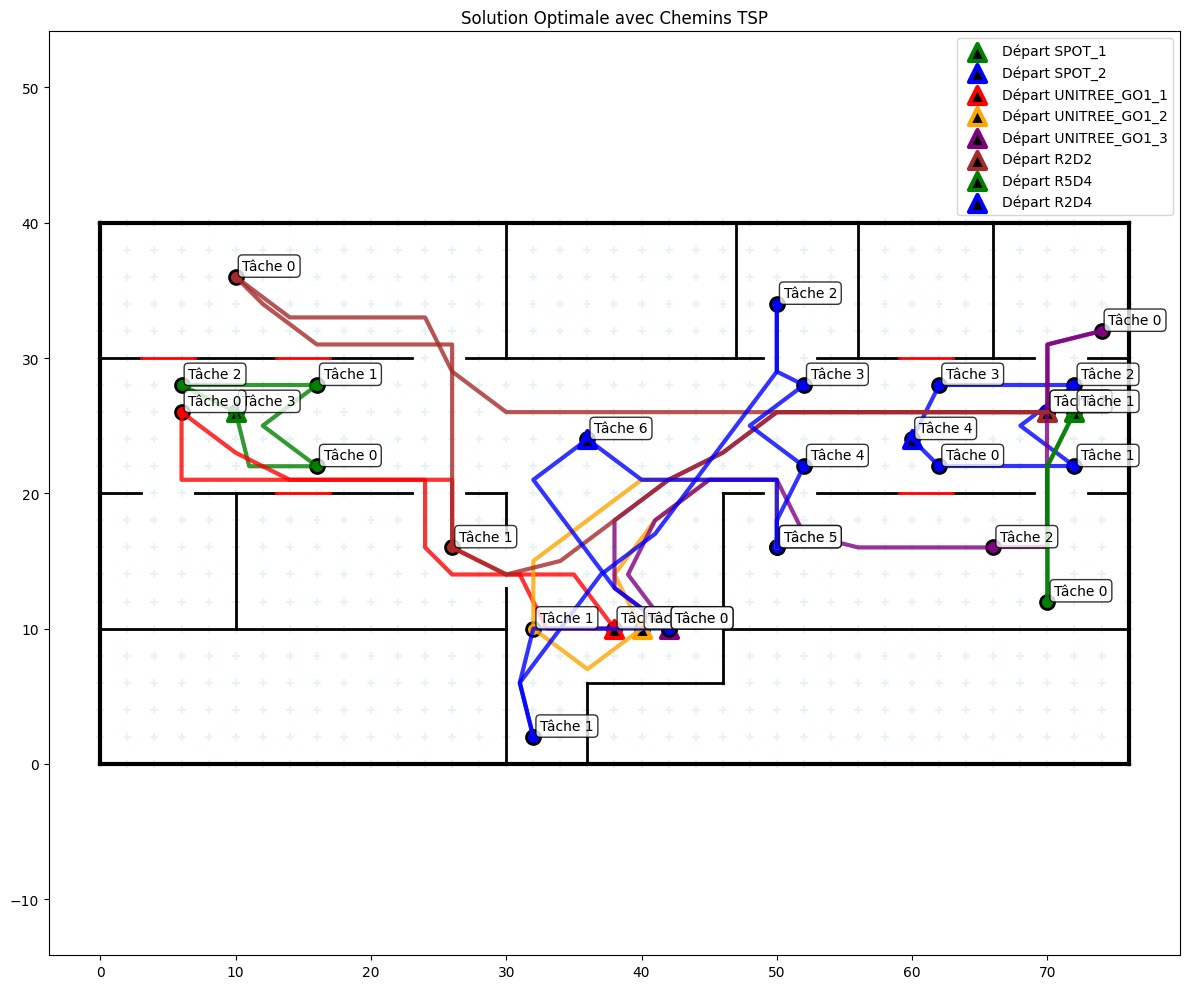

\n📊 INFORMATIONS SUR LA SOLUTION:
💰 Coût total optimal: 534.01
🤖 Robots visualisés: 8
\n🤖 SPOT_1 (Bras):
   - Clusters: [0]
   - Tâches: 3
   - Coût: 33.01
\n🤖 SPOT_2 (Bras):
   - Clusters: [2]
   - Tâches: 4
   - Coût: 52.12
\n🤖 UNITREE_GO1_1 (Camera):
   - Clusters: [0]
   - Tâches: 1
   - Coût: 39.78
\n🤖 UNITREE_GO1_2 (Camera):
   - Clusters: [1]
   - Tâches: 2
   - Coût: 27.66
\n🤖 UNITREE_GO1_3 (Camera):
   - Clusters: [2]
   - Tâches: 3
   - Coût: 107.82
\n🤖 R2D2 (Thermometre):
   - Clusters: [0]
   - Tâches: 2
   - Coût: 117.95
\n🤖 R5D4 (Thermometre):
   - Clusters: [2]
   - Tâches: 1
   - Coût: 20.14
\n🤖 R2D4 (Polyvalent):
   - Clusters: [1]
   - Tâches: 6
   - Coût: 135.54


In [108]:
# === UTILISATION CORRIGÉE ===

# Tester avec moins de robots d'abord
print("=== TEST AVEC 2 ROBOTS ===")
robots_test = ["SPOT", "R2D2"]
visualiser_solution_avec_tsp(resultats_cluster_1, liste_robots, df_sous_taches, room3)

### Multiples affectations

In [238]:
liste_robots_contrainte = [robot for robot in liste_robots if robot.nom not in ["SPOT_2", "R2D4"]]

liste_robots_contrainte

[[Robot] SPOT_1,
 [Robot] UNITREE_GO1_1,
 [Robot] UNITREE_GO1_2,
 [Robot] UNITREE_GO1_3,
 [Robot] R2D2,
 [Robot] R5D4]

In [250]:
def verifier_compatibilite_robot_prerequis(robot, prerequis_tache):
    """
    Vérifie si un robot est compatible avec les prérequis d´une tâche.
    """
    if robot.fonction == "Polyvalent":
        return True
    if isinstance(prerequis_tache, list):
        return robot.fonction in prerequis_tache
    return robot.fonction == prerequis_tache

def calculer_distance(pos1, pos2):
    """
    Calcule la distance euclidienne entre deux points.
    """
    return np.sqrt((pos1[0] - pos2[0])**2 + (pos1[1] - pos2[1])**2)

def resoudre_rodada_unique_amelioree(robots_disponibles, clusters_mds, df_tasks, types_mds,
                                     taches_restantes, numero_rodada, robots_non_utilises):
    """
    Résout l´affectation pour une seule ronde en utilisant PuLP pour l´optimisation.
    Priorise l´affectation du plus grand nombre possible de tâches.
    """
    print(f"DEBUG: resoudre_rodada_unique_amelioree appelée pour la ronde {numero_rodada}")
    print(f"DEBUG: Tâches restantes: {list(taches_restantes)}")
    print(f"DEBUG: Robots disponibles: {[r.nom for r in robots_disponibles]}")

    resultats_rodada = {
        'status': 'optimal',
        'affectation_taches': {},
        'affectation_clusters': {},
        'robots_utilises': [],
        'taches_affectees': [],
        'cout_total': 0,
        'details_robots': {}
    }

    taches_compatibles_disponibles = []
    for tache_id in taches_restantes:
        tache_info = df_tasks.loc[tache_id]
        if any(verifier_compatibilite_robot_prerequis(r, tache_info['Prérequis']) for r in robots_disponibles):
            taches_compatibles_disponibles.append(tache_id)

    if not taches_compatibles_disponibles or not robots_disponibles:
        print("DEBUG: Aucune tâche compatible ou aucun robot disponible pour cette ronde.")
        resultats_rodada['status'] = 'failed'
        resultats_rodada['message'] = 'Aucune tâche compatible ou aucun robot disponible.'
        return resultats_rodada
    print(f"DEBUG: Tâches compatibles pour cette ronde: {taches_compatibles_disponibles}")

    prob = pulp.LpProblem("Affectation_Robots_Rodada", pulp.LpMinimize)

    possible_assignments = []
    for r in robots_disponibles:
        for t_id in taches_compatibles_disponibles:
            if verifier_compatibilite_robot_prerequis(r, df_tasks.loc[t_id]['Prérequis']):
                possible_assignments.append((r.nom, t_id))

    print(f"DEBUG: possible_assignments: {possible_assignments}")

    x_vars = pulp.LpVariable.dicts("x", possible_assignments, 0, 1, pulp.LpBinary)
    z_vars = pulp.LpVariable.dicts("z", taches_compatibles_disponibles, 0, 1, pulp.LpBinary) # Variable pour indiquer si la tâche a été affectée

    print(f"DEBUG: Clés de clusters_mds: {list(clusters_mds.keys())}")

    y_vars = pulp.LpVariable.dicts("y",
                              ((r.nom, c_id) for r in robots_disponibles for c_id in clusters_mds.keys()),
                              0, 1, pulp.LpBinary)

    print(f"DEBUG: Clés de x_vars: {list(x_vars.keys())}")
    print(f"DEBUG: Clés de y_vars: {list(y_vars.keys())}")
    print(f"DEBUG: Clés de z_vars: {list(z_vars.keys())}")

    # Coût total (objectif) - Minimiser le coût ET maximiser les tâches affectées
    # Le poids de 10000 pour z_vars garantit que la maximisation des tâches affectées est prioritaire
    obj_expr = []
    for robot_nom, tache_id in x_vars.keys():
        robot = next((r for r in robots_disponibles if r.nom == robot_nom), None)
        if robot:
            tache_info = df_tasks.loc[tache_id]
            tache_pos = (tache_info['Coord_X'], tache_info['Coord_Y'])
            distance = calculer_distance(robot.position, tache_pos)
            obj_expr += [robot.cout_par_distance * distance * x_vars[(robot_nom, tache_id)]]
    
    # Ajouter un terme pour maximiser le nombre de tâches affectées (multiplié par -1 pour minimiser)
    obj_expr += [-10000 * pulp.lpSum(z_vars[t_id] for t_id in taches_compatibles_disponibles)]
    
    prob += pulp.lpSum(obj_expr), "Coût Total de la Rodada"

    # Contraintes:

    # 1. Chaque tâche peut être affectée au maximum une fois, et si elle est affectée, z_vars[tache_id] doit être 1
    for tache_id in taches_compatibles_disponibles:
        sum_expr = [x_vars[(robot.nom, tache_id)] for robot in robots_disponibles
                    if (robot.nom, tache_id) in x_vars]
        if sum_expr:
            prob += pulp.lpSum(sum_expr) == z_vars[tache_id], f"Tache_{tache_id}_Affectation_Unique"
        else:
            print(f"AVERTISSEMENT: Aucune variable x_vars trouvée pour la tâche {tache_id} dans la contrainte d'affectation unique.")

    # 2. Un robot peut être affecté à au maximum un cluster par ronde
    for robot in robots_disponibles:
        prob += pulp.lpSum(y_vars[(robot.nom, c_id)] for c_id in clusters_mds.keys()) <= 1, f"Robot_{robot.nom}_Un_Seul_Cluster"

    # 3. Si un robot est affecté à une tâche, il doit être affecté au cluster de cette tâche
    for robot_nom, tache_id in x_vars.keys():
        robot = next((r for r in robots_disponibles if r.nom == robot_nom), None)
        if robot:
            tache_info = df_tasks.loc[tache_id]
            cluster_tache = tache_info['Cluster']
            print(f"DEBUG: Tâche {tache_id} (Robot {robot.nom}) - Cluster: {cluster_tache}")
            if (robot.nom, cluster_tache) in y_vars:
                prob += x_vars[(robot.nom, tache_id)] <= y_vars[(robot.nom, cluster_tache)], f"Robot_{robot.nom}_Tache_{tache_id}_Cluster_Coherence"
            else:
                print(f"AVERTISSEMENT: Variable y_vars pour le robot {robot.nom} et le cluster {cluster_tache} non trouvée. Vérifiez si le cluster de la tâche est dans les clusters_mds.keys().")

    # 4. Capacité des robots: un robot peut faire au maximum ´capacite´ tâches par ronde
    for robot in robots_disponibles:
        sum_expr = [x_vars[(robot.nom, tache_id)] for tache_id in taches_compatibles_disponibles
                    if (robot.nom, tache_id) in x_vars]
        if sum_expr:
            prob += pulp.lpSum(sum_expr) <= robot.capacite, f"Robot_{robot.nom}_Capacite"
        else:
            print(f"AVERTISSEMENT: Aucune variable x_vars trouvée pour le robot {robot.nom} dans la contrainte de capacité.")

    print("DEBUG: Problème PuLP avant de résoudre:")
    print(prob)

    prob.solve()

    print("DEBUG: Problème PuLP après résolution:")
    print(prob)

    if pulp.LpStatus[prob.status] == 'Optimal':
        resultats_rodada['status'] = 'optimal'
        # Le coût total inclut maintenant le terme de maximisation des tâches, nous devons donc l'ajuster
        # pour obtenir le coût réel de déplacement.
        real_cost = 0
        for robot_nom, tache_id in x_vars.keys():
            robot = next((r for r in robots_disponibles if r.nom == robot_nom), None)
            if robot and x_vars[(robot_nom, tache_id)].varValue is not None and x_vars[(robot_nom, tache_id)].varValue > 0.5:
                tache_info = df_tasks.loc[tache_id]
                tache_pos = (tache_info['Coord_X'], tache_info['Coord_Y'])
                distance = calculer_distance(robot.position, tache_pos)
                real_cost += robot.cout_par_distance * distance
        resultats_rodada['cout_total'] = real_cost

        for robot in robots_disponibles:
            taches_affectees_robot = []
            clusters_affectes_robot = set()
            cout_robot = 0

            for tache_id in taches_compatibles_disponibles:
                if (robot.nom, tache_id) in x_vars:
                    if x_vars[(robot.nom, tache_id)].varValue is not None and x_vars[(robot.nom, tache_id)].varValue > 0.5:
                        taches_affectees_robot.append(tache_id)
                        resultats_rodada['taches_affectees'].append(tache_id)
                        tache_info = df_tasks.loc[tache_id]
                        clusters_affectes_robot.add(tache_info['Cluster'])
                        distance = calculer_distance(robot.position, (tache_info['Coord_X'], tache_info['Coord_Y']))
                        cout_robot += robot.cout_par_distance * distance

            if taches_affectees_robot:
                resultats_rodada['affectation_taches'][robot.nom] = taches_affectees_robot
                resultats_rodada['robots_utilises'].append(robot.nom)
                resultats_rodada['details_robots'][robot.nom] = {
                    'clusters': list(clusters_affectes_robot),
                    'taches': taches_affectees_robot,
                    'cout_total': cout_robot
                }
                for cluster_id in clusters_affectes_robot:
                    if cluster_id not in resultats_rodada['affectation_clusters']:
                        resultats_rodada['affectation_clusters'][cluster_id] = []
                    resultats_rodada['affectation_clusters'][cluster_id].append(robot.nom)
    else:
        resultats_rodada['status'] = 'failed'
        resultats_rodada['message'] = f"La résolution de la ronde {numero_rodada} a échoué: {pulp.LpStatus[prob.status]}"
        print(f"DEBUG: Statut de la résolution PuLP: {pulp.LpStatus[prob.status]}")

    print("DEBUG: Valeurs des variables x_vars après résolution:")
    for v in prob.variables():
        if v.name.startswith('x_') and v.varValue is not None and v.varValue > 0.0:
            print(f"{v.name} = {v.varValue}")
    print("DEBUG: Valeurs des variables y_vars après résolution:")
    for v in prob.variables():
        if v.name.startswith('y_') and v.varValue is not None and v.varValue > 0.0:
            print(f"{v.name} = {v.varValue}")
    print("DEBUG: Valeurs des variables z_vars après résolution:")
    for v in prob.variables():
        if v.name.startswith('z_') and v.varValue is not None and v.varValue > 0.0:
            print(f"{v.name} = {v.varValue}")

    return resultats_rodada

def resoudre_rodada_contraintes_assouplies(robots_disponibles, clusters_mds, df_tasks, types_mds,
                                           taches_restantes, numero_rodada, robots_non_utilises):
    """
    Tente de résoudre l'affectation avec des contraintes assouplies si la première tentative échoue.
    Par exemple, ignorer certaines contraintes de capacité ou de distance, si nécessaire.
    """
    print(f"DEBUG: resoudre_rodada_contraintes_assouplies appelée pour la ronde {numero_rodada}")
    return {'status': 'failed', 'message': 'Implémentation des contraintes assouplies non disponible.'}

def essayer_redistribution_robots(resultats_globaux, liste_robots, df_tasks, clusters_mds):
    """
    Tente de redistribuer les tâches non affectées ou de réaffecter les robots.
    Priorise les tâches non affectées des rondes précédentes.
    """
    print("DEBUG: essayer_redistribution_robots appelée")
    taches_redistribuables = set()

    if 'toutes_taches_initiales' in resultats_globaux:
        toutes_taches_initiales = set(resultats_globaux['toutes_taches_initiales'])
        taches_affectees_globales = resultats_globaux['taches_affectees_globales']
        taches_non_affectees = toutes_taches_initiales - taches_affectees_globales
        print(f"DEBUG: {len(taches_non_affectees)} tâches non affectées globalement.")
        taches_redistribuables.update(taches_non_affectees)

    robots_non_utilises_globalement = resultats_globaux['robots_non_utilises']
    print(f"DEBUG: {len(robots_non_utilises_globalement)} robots non utilisés globalement.")

    return list(taches_redistribuables)

def analyser_compatibilite_robots_taches(taches_initiales, df_tasks, liste_robots):
    """
    Analyse la compatibilité générale entre les robots et les tâches.
    """
    print("\n🔍 ANALYSE DE COMPATIBILITÉ ROBOTS-TÂCHES:")
    
    taches_par_type = df_tasks.loc[taches_initiales]['Intitulé'].value_counts().to_dict()
    print(f"   Total de tâches par type: {taches_par_type}")
    
    robots_par_fonction = {}
    for robot in liste_robots:
        if robot.fonction not in robots_par_fonction:
            robots_par_fonction[robot.fonction] = 0
        robots_par_fonction[robot.fonction] += 1
    print(f"   Total de robots par fonction: {robots_par_fonction}")
    
    for tache_id in taches_initiales:
        tache_info = df_tasks.loc[tache_id]
        prerequis = tache_info['Prérequis']
        tipo_tache = tache_info['Intitulé']
        
        robos_compativeis = [r.nom for r in liste_robots if verifier_compatibilite_robot_prerequis(r, prerequis)]
        
        if not robos_compativeis:
            print(f"   ❌ AVERTISSEMENT: Aucun robot compatible pour la tâche {tache_id} ({tipo_tache}) avec prérequis {prerequis}")
        else:
            print(f"   ✅ Tâche {tache_id} ({tipo_tache}) compatible avec {len(robos_compativeis)} robots: {robos_compativeis}")

def analyser_robots_non_utilises(robots_non_utilises, liste_robots, df_tasks):
    """
    Analyse pourquoi certains robots n'ont pas été utilisés.
    """
    
    print(f"\n🔍 ANALYSE DES ROBOTS NON UTILISÉS:")
    
    for robot_nom in robots_non_utilises:
        robot = next((r for r in liste_robots if r.nom == robot_nom), None)
        if robot is None:
            continue
        
        print(f"\n   🤖 {robot.nom}:")
        print(f"      Fonction: {robot.fonction}")
        print(f"      Position: {robot.position}")
        
        taches_compatibles = 0
        taches_par_type = {}
        
        for _, tache_info in df_tasks.iterrows():
            if verifier_compatibilite_robot_prerequis(robot, tache_info['Prérequis']):
                taches_compatibles += 1
                type_tache = tache_info['Intitulé']
                if type_tache not in taches_par_type:
                    taches_par_type[type_tache] = 0
                taches_par_type[type_tache] += 1
        
        print(f"      Tâches compatibles: {taches_compatibles}/{len(df_tasks)}")
        
        if taches_compatibles == 0:
            print(f"      ❌ PROBLÈME: Aucune tâche compatible!")
            print(f"      💡 Solution: Vérifier les prérequis ou ajouter la fonction 'Polyvalent'")
        elif taches_compatibles < 5:
            print(f"      ⚠️  ATTENTION: Très peu de tâches compatibles. Vérifier la pertinence de ce robot.")
        else:
            print(f"      ✅ OK: {taches_compatibles} tâches compatibles.")
            
        if taches_par_type:
            print(f"      Détail par type de tâche: {taches_par_type}")

def analyser_taches_non_affectees(taches_non_affectees, df_tasks, liste_robots):
    """
    Analyse pourquoi certaines tâches n'ont pas été affectées.
    """
    print(f"\n🔍 ANALYSE DES TÂCHES NON AFFECTÉES:")
    
    for tache_id in taches_non_affectees:
        tache_info = df_tasks.loc[tache_id]
        prerequis = tache_info['Prérequis']
        tipo_tache = tache_info['Intitulé']
        
        print(f"\n   📝 Tâche {tache_id} ({tipo_tache}):")
        print(f"      Prérequis: {prerequis}")
        
        robos_compativeis = [r.nom for r in liste_robots if verifier_compatibilite_robot_prerequis(r, prerequis)]
        
        if not robos_compativeis:
            print(f"      ❌ PROBLÈME: Aucun robot compatible pour cette tâche!")
            print(f"      💡 Solution: Vérifier les prérequis de la tâche ou ajouter un robot compatible.")
        else:
            print(f"      ✅ {len(robos_compativeis)} robots compatibles: {robos_compativeis}")

def resolver_afectacao_multiplas_rodadas(liste_robots, clusters_mds, df_tasks, types_mds, max_rodadas=5, forcar_todos_robos=True):
    """
    Résout l'affectation des robots aux tâches en plusieurs rondes.
    """
    toutes_taches_initiales = list(df_tasks.index)
    taches_restantes = set(toutes_taches_initiales)
    taches_affectees_globales = set()
    robots_non_utilises_globalement = set(r.nom for r in liste_robots)
    resultats_globaux = {
        'affectation_taches': {},
        'affectation_clusters': {},
        'robots_utilises': set(),
        'taches_affectees_globales': set(),
        'cout_total_global': 0,
        'details_robots': {},
        'toutes_taches_initiales': toutes_taches_initiales,
        'historique_rodadas': []
    }

    print(f"\n============================================================")
    print(f"🎯 DÉBUT DE L'AFFECTATION EN MULTIPLES RONDES")
    print(f"============================================================")

    for numero_rodada in range(1, max_rodadas + 1):
        print(f"\n============================================================")
        print(f"🎯 RONDE {numero_rodada}")
        print(f"============================================================")
        print(f"Tâches restantes: {len(taches_restantes)}")
        print(f"Robots disponibles pour cette ronde: {len(liste_robots)}")
        print(f"Robots non utilisés globalement: {len(robots_non_utilises_globalement)}")

        if not taches_restantes:
            print("Toutes les tâches ont été affectées. Fin de l'affectation.")
            break

        resultat_rodada = resoudre_rodada_unique_amelioree(
            liste_robots, clusters_mds, df_tasks, types_mds,
            taches_restantes, numero_rodada, robots_non_utilises_globalement
        )

        if resultat_rodada['status'] == 'optimal':
            print(f"Ronde {numero_rodada} terminée avec succès. Coût: {resultat_rodada['cout_total']:.2f}")
            
            taches_affectees_nesta_rodada = set(resultat_rodada['taches_affectees'])
            taches_restantes -= taches_affectees_nesta_rodada
            taches_affectees_globales.update(taches_affectees_nesta_rodada)

            for robot_nom in resultat_rodada['robots_utilises']:
                robots_non_utilises_globalement.discard(robot_nom)

            resultats_globaux['cout_total_global'] += resultat_rodada['cout_total']
            for robot_nom, taches in resultat_rodada['affectation_taches'].items():
                if robot_nom not in resultats_globaux['affectation_taches']:
                    resultats_globaux['affectation_taches'][robot_nom] = []
                resultats_globaux['affectation_taches'][robot_nom].extend(taches)
            for cluster_id, robots_in_cluster in resultat_rodada['affectation_clusters'].items():
                if cluster_id not in resultats_globaux['affectation_clusters']:
                    resultats_globaux['affectation_clusters'][cluster_id] = []
                resultats_globaux['affectation_clusters'][cluster_id].extend(robots_in_cluster)
            resultats_globaux['robots_utilises'].update(resultat_rodada['robots_utilises'])
            resultats_globaux['details_robots'].update(resultat_rodada['details_robots'])
            resultats_globaux['historique_rodadas'].append(resultat_rodada)

        else:
            print(f"Ronde {numero_rodada} a échoué: {resultat_rodada['message']}")
            break

    resultats_globaux['taches_affectees_globales'] = taches_affectees_globales
    resultats_globaux['robots_non_utilises'] = list(robots_non_utilises_globalement)

    print(f"\n============================================================")
    print(f"📊 RÉSULTATS FINAUX APRÈS {numero_rodada} RONDES")
    print(f"============================================================")
    print(f"Coût total global: {resultats_globaux['cout_total_global']:.2f}")
    print(f"Total de tâches affectées: {len(resultats_globaux['taches_affectees_globales'])}/{len(toutes_taches_initiales)}")
    print(f"Tâches non affectées: {len(taches_restantes)}")
    if taches_restantes:
        print(f"IDs des tâches non affectées: {list(taches_restantes)}")
        analyser_taches_non_affectees(list(taches_restantes), df_tasks, liste_robots)
    else:
        print("Toutes les tâches ont été affectées avec succès!")

    print(f"Robots utilisés: {len(resultats_globaux['robots_utilises'])}/{len(liste_robots)}")
    if resultats_globaux['robots_non_utilises']:
        print(f"Robots non utilisés: {resultats_globaux['robots_non_utilises']}")
        analyser_robots_non_utilises(resultats_globaux['robots_non_utilises'], liste_robots, df_tasks)
    else:
        print("Tous les robots ont été utilisés!")

    print("\nDétails de l'affectation par robot:")
    for robot_nom, details in resultats_globaux['details_robots'].items():
        print(f"  - {robot_nom}: Tâches {details['taches']} (Coût: {details['cout_total']:.2f})")

    print("\nAffectation par cluster:")
    for cluster_id, robots in resultats_globaux['affectation_clusters'].items():
        print(f"  - Cluster {cluster_id}: Robots {robots}")

    return resultats_globaux

In [259]:
types_mds=["Surveiller", "Mesure_Température"]
resultats_rounds = resolver_afectacao_multiplas_rodadas(
    liste_robots_contrainte, mds_total, df_sous_taches, 
    types_mds=types_mds,
    max_rodadas=10,
    forcar_todos_robos=True
)

# Verificar resultados
print(f"Robots utilisés: {len(resultats_rounds['robots_utilises'])}/{len(liste_robots_contrainte)}")
print(f"Robots non utilisés: {resultats_rounds['robots_non_utilises']}")


🎯 DÉBUT DE L'AFFECTATION EN MULTIPLES RONDES

🎯 RONDE 1
Tâches restantes: 29
Robots disponibles pour cette ronde: 6
Robots non utilisés globalement: 6
DEBUG: resoudre_rodada_unique_amelioree appelée pour la ronde 1
DEBUG: Tâches restantes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28]
DEBUG: Robots disponibles: ['SPOT_1', 'UNITREE_GO1_1', 'UNITREE_GO1_2', 'UNITREE_GO1_3', 'R2D2', 'R5D4']
DEBUG: Tâches compatibles pour cette ronde: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28]
DEBUG: possible_assignments: [('SPOT_1', 20), ('SPOT_1', 21), ('SPOT_1', 22), ('SPOT_1', 23), ('SPOT_1', 24), ('SPOT_1', 25), ('SPOT_1', 26), ('SPOT_1', 27), ('SPOT_1', 28), ('UNITREE_GO1_1', 0), ('UNITREE_GO1_1', 1), ('UNITREE_GO1_1', 2), ('UNITREE_GO1_1', 3), ('UNITREE_GO1_1', 4), ('UNITREE_GO1_1', 5), ('UNITREE_GO1_1', 6), ('UNITREE_GO1_1', 7), ('UNITREE_GO1_1', 8), ('UNITREE_GO1_1', 9), ('

In [299]:
def visualiser_solution_avec_tsp_adaptee_complete(resultats_compatibles, liste_robots, df_tasks, piece, 
                                                 robots_a_visualiser, grid_size, titre_suffixe=""):
    """
    Adapte la fonction de visualisation existante pour être appelée par les fonctions de rodada.
    """
    print(f"🎨 Visualisation adaptée: {titre_suffixe}")
    
    plt.figure(figsize=(12, 10))
    
    # === DESSINER L'ENVIRONNEMENT ===
    list_plot = [piece.murs_exterieurs, piece.liste_murs, piece.portes_fermees]
    liste_couleur = ["black", "black", "red"]
    liste_largeur = [4, 3, 3]
    
    for i in range(len(list_plot)):
        for mur in list_plot[i]:
            position = mur.position
            plt.plot([position[0][0], position[1][0]], [position[0][1], position[1][1]], 
                    color=liste_couleur[i], linewidth=liste_largeur[i])
    
    try:
        x_grille, y_grille = piece.grille(grid_size)
        for x in x_grille:
            for y in y_grille:
                plt.scatter(x, y, color="lightblue", marker="+", s=15, alpha=0.2)
    except Exception as e:
        print(f"⚠️  Erreur grille: {e}")

    # === DESSINER LES ROBOTS ET LEURS CHEMINS ===
    for robot_nom, taches_affectees_ids in resultats_compatibles["affectation_taches"].items():
        robot = next((r for r in liste_robots if r.nom == robot_nom), None)
        if robot is None:
            continue
        
        # Preparar as tarefas para a função plus_court_chemin_tsp
        taches_a_faire = []
        for tache_id in taches_affectees_ids:
            tache_info = df_tasks.loc[tache_id]
            taches_a_faire.append((tache_info["Coord_X"], tache_info["Coord_Y"], tache_info["Intitulé"]))
        
        # Calcular o caminho TSP
        pathes, etapes = piece.plus_court_chemin_tsp(robot.position, taches_a_faire, robot, grid_size)

        # Desenhar o caminho TSP
        if pathes:
            for path_segment in pathes:
                plt.plot([p[0] for p in path_segment], [p[1] for p in path_segment], 
                         color="blue", linestyle="-", linewidth=2, alpha=0.7)
            
            # Desenhar as etapas (tarefas e início/fim)
            for etape in etapes:
                plt.scatter(etape[0], etape[1], color="red", marker="o", s=100)
                plt.text(etape[0] + 0.3, etape[1] + 0.3, etape[2], fontsize=8)
        else:
            print(f"Avertissement: Pas de chemin TSP trouvé pour le robot {robot.nom} dans {titre_suffixe}.")

        # Desenhar a posição inicial do robot
        plt.scatter(robot.position[0], robot.position[1], color="black", marker="s", s=100)
        plt.text(robot.position[0] + 1, robot.position[1] + 1, robot.nom, fontsize=9)
        
    plt.title(f"Visualisation de l'affectation {titre_suffixe}")
    plt.xlabel("Coordonnée X")
    plt.ylabel("Coordonnée Y")
    plt.legend()
    plt.grid(True)
    plt.axis("equal")
    plt.show()

def preparer_tous_robots_pour_rodada(resultats_globaux, numero_rodada, liste_robots, df_tasks):
    """
    Prépare TOUS les robots qui ont participé à une rodada spécifique.
    
    Paramètres:
    -----------
    resultats_globaux : dict
        Résultats globaux
    numero_rodada : int
        Numéro de la rodada
    liste_robots : list
        Liste des robots
    df_tasks : DataFrame
        DataFrame des tâches
        
    Retourne:
    ---------
    list
        Liste des informations de TOUS les robots pour cette rodada
    """
    
    robots_rodada = []
    
    if numero_rodada - 1 >= len(resultats_globaux["historique_rodadas"]) or numero_rodada <= 0:
        return robots_rodada
    
    resultats_rodada = resultats_globaux["historique_rodadas"][numero_rodada - 1]
    
    for robot_nom in resultats_rodada["robots_utilises"]:
        robot_obj = next((r for r in liste_robots if r.nom == robot_nom), None)
        
        if robot_obj is None:
            print(f"⚠️  Robot {robot_nom} non trouvé dans liste_robots.")
            continue
        
        details_robot_rodada = resultats_rodada["details_robots"].get(robot_nom, {})
        taches_affectees_robot_rodada = details_robot_rodada.get("taches", [])
        
        robots_rodada.append({
            "nom": robot_obj.nom,
            "fonction": robot_obj.type, # Usar type como função
            "position_initiale": robot_obj.position,
            "taches": taches_affectees_robot_rodada,
            "cout_total": details_robot_rodada.get("cout_total", 0)
        })
        
    return robots_rodada

def dessiner_robot_rodada_complete(robot_info, style_rodada, piece, grid_size, df_tasks):
    """
    Dessine le chemin d'un robot pour une rodada en utilisant plus_court_chemin_tsp.
    """
    robot_obj = Robot(0, robot_info["nom"], robot_info["fonction"], 0, 0, robot_info["position_initiale"], taille=1) # Placeholder robot
    
    taches_a_faire = []
    for tache_id in robot_info["taches"]:
        tache_info = df_tasks.loc[tache_id]
        taches_a_faire.append((tache_info["Coord_X"], tache_info["Coord_Y"], tache_info["Intitulé"]))

    pathes, etapes = piece.plus_court_chemin_tsp(robot_info["position_initiale"], taches_a_faire, robot_obj, grid_size)

    if pathes:
        for path_segment in pathes:
            plt.plot([p[0] for p in path_segment], [p[1] for p in path_segment], 
                     color=style_rodada["couleur"], 
                     linestyle=style_rodada["style"], 
                     alpha=style_rodada["alpha"], 
                     linewidth=2, 
                     label=f"{robot_info['nom']} (Rodada {style_rodada['nom'].split()[-1]})" if path_segment == pathes[0] else "")
        
        for etape in etapes:
            plt.scatter(etape[0], etape[1], color=style_rodada["couleur"], marker=style_rodada["marker"], s=100, alpha=style_rodada["alpha"])
            plt.text(etape[0] + 0.3, etape[1] + 0.3, etape[2], fontsize=8, color=style_rodada["couleur"])
    else:
        print(f"Avertissement: Pas de chemin TSP trouvé pour le robot {robot_info['nom']} dans cette rodada.")
        # Desenhar apenas a posição inicial se não houver caminho TSP
        plt.scatter(robot_info["position_initiale"][0], robot_info["position_initiale"][1], 
                    color=style_rodada["couleur"], marker="o", s=100, alpha=style_rodada["alpha"])
        plt.text(robot_info["position_initiale"][0] + 1, robot_info["position_initiale"][1] + 1, 
                 f"{robot_info['nom']}", fontsize=9, color=style_rodada['couleur'],
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="white", 
                           edgecolor=style_rodada["couleur"], alpha=style_rodada["alpha"]))


def afficher_informations_detaillees_rodadas(resultats_globaux):
    """
    Affiche les informations détaillées par rodada et par robot.
    
    Paramètres:
    -----------
    resultats_globaux : dict
        Résultats globaux
    """
    
    print(f"\n📊 INFORMATIONS DÉTAILLÉES PAR RODADA:")
    print("-" * 60)
    
    for i, resultats_rodada in enumerate(resultats_globaux["historique_rodadas"]):
        rodada = i + 1
        
        print(f"\n🎯 RODADA {rodada}:")
        print(f"   Tâches affectées: {len(resultats_rodada['taches_affectees'])}")
        print(f"   Coût de la rodada: {resultats_rodada['cout_total']:.2f}")
        print(f"   Robots utilisés: {len(resultats_rodada['robots_utilises'])}")
        
        for robot_nom in sorted(resultats_rodada["robots_utilises"]):
            if robot_nom in resultats_rodada["details_robots"]:
                details = resultats_rodada["details_robots"][robot_nom]
                print(f"      🤖 {robot_nom}:")
                print(f"         Clusters: {details['clusters']}")
                print(f"         Tâches: {len(details['taches'])} - {details['taches']}")
                print(f"         Coût robot: {details['cout_total']:.2f}")

    print(f"\n📊 RÉSUMÉ GLOBAL PAR ROBOT:")
    print("-" * 60)
    
    details_robots_globaux = {}
    for robot_nom, details in resultats_globaux["details_robots"].items():
        details_robots_globaux[robot_nom] = {
            "clusters": details["clusters"],
            "cout_total": details["cout_total"],
            "rodadas_participees": 0,
            "taches_par_rodada": {}
        }
    
    for i, rodada_data in enumerate(resultats_globaux["historique_rodadas"]):
        rodada_num = i + 1
        for robot_nom, taches in rodada_data["affectation_taches"].items():
            if robot_nom in details_robots_globaux:
                details_robots_globaux[robot_nom]["rodadas_participees"] += 1
                details_robots_globaux[robot_nom]["taches_par_rodada"][rodada_num] = taches

    for robot_nom in sorted(resultats_globaux["robots_utilises"]):
        if robot_nom in details_robots_globaux:
            details_global = details_robots_globaux[robot_nom]
            
            print(f"\n🤖 {robot_nom}:")
            print(f"   Clusters visités: {details_global['clusters']}")
            print(f"   Rodadas participées: {details_global['rodadas_participees']}")
            print(f"   Coût total: {details_global['cout_total']:.2f}")

            total_taches = sum(len(taches) for taches in details_global['taches_par_rodada'].values())
            print(f"   Total tâches: {total_taches}")

            for rodada, taches in details_global['taches_par_rodada'].items():
                print(f"      Rodada {rodada}: {len(taches)} tâches - {taches}")

def visualiser_rodada_unique_complete(resultats_globaux, numero_rodada, liste_robots, 
                                     df_tasks, piece, robots_a_visualiser, grid_size):
    """
    Visualise une rodada unique avec TOUS les robots affectés.
    
    Paramètres:
    -----------
    resultats_globaux : dict
        Résultats globaux
    numero_rodada : int
        Numéro de la rodada à visualiser
    liste_robots : list
        Liste des robots
    df_tasks : DataFrame
        DataFrame des tâches
    piece : Piece
        Votre objet Piece
    robots_a_visualiser : list
        Robots à visualiser
    grid_size : float
        Taille de la grille
    """
    
    if numero_rodada - 1 >= len(resultats_globaux["historique_rodadas"]) or numero_rodada <= 0:
        print(f"❌ Rodada {numero_rodada} non trouvée")
        return
    
    resultats_rodada = resultats_globaux["historique_rodadas"][numero_rodada - 1]

    print(f"Robots dans cette rodada: {list(resultats_rodada['robots_utilises'])}")
    print(f"Tâches affectées: {len(resultats_rodada['taches_affectees'])}")
    print(f"Coût de la rodada: {resultats_rodada['cout_total']:.2f}")

    resultats_compatibles = {
        "status": "optimal",
        "cout_total": resultats_rodada["cout_total"],
        "affectation_taches": {},
        "robots_utilises": set(),
        "details_robots": {}
    }
    
    for robot_nom in resultats_rodada["robots_utilises"]:
        if robot_nom in resultats_rodada["details_robots"]:
            details = resultats_rodada["details_robots"][robot_nom]
            
            resultats_compatibles["affectation_taches"][robot_nom] = details["taches"]
            resultats_compatibles["robots_utilises"].add(robot_nom)
            resultats_compatibles["details_robots"][robot_nom] = details
    
    if not resultats_compatibles["affectation_taches"]:
        print(f"⚠️  Aucune tâche à visualiser pour la rodada {numero_rodada}")
        return
    
    visualiser_solution_avec_tsp_adaptee_complete(
        resultats_compatibles, liste_robots, df_tasks, piece, 
        list(resultats_compatibles["robots_utilises"]), 
        grid_size, f"Rodada {numero_rodada}"
    )

def visualiser_toutes_rodadas_ensemble_complete(resultats_globaux, liste_robots, df_tasks, 
                                               piece, robots_a_visualiser, grid_size):
    """
    Visualise toutes les rodadas ensemble avec TOUS les robots affectés.
    
    Paramètres:
    -----------
    resultats_globaux : dict
        Résultats globaux
    liste_robots : list
        Liste des robots
    df_tasks : DataFrame
        DataFrame des tâches
    piece : Piece
        Votre objet Piece
    robots_a_visualiser : list
        Robots à visualiser
    grid_size : float
        Taille de la grille
    """
    
    print(f"🎨 Visualisation de toutes les rodadas ensemble...")
    
    # Couleurs e estilos para até 10 rodadas
    # Usando um colormap para gerar cores distintas
    colors = cm.get_cmap('tab10', 10) # 'tab10' tem 10 cores distintas
    
    couleurs_rodadas = {}
    for i in range(1, 11): # Para rodadas de 1 a 10
        couleurs_rodadas[i] = {
            'couleur': colors(i-1), # i-1 para indexar de 0 a 9
            'style': '-', 
            'alpha': 0.9 - (i-1)*0.05, # Diminuir um pouco a opacidade para rodadas posteriores
            'nom': f'Rodada {i}', 
            'marker': 'o' # Marcador genérico
        }
    
    # Ajustar estilos para maior diferenciação se necessário
    if 2 in couleurs_rodadas: couleurs_rodadas[2]['style'] = '--'
    if 3 in couleurs_rodadas: couleurs_rodadas[3]['style'] = '-.'
    if 4 in couleurs_rodadas: couleurs_rodadas[4]['style'] = ':'
    if 5 in couleurs_rodadas: couleurs_rodadas[5]['marker'] = 's'
    if 6 in couleurs_rodadas: couleurs_rodadas[6]['marker'] = 'D'
    if 7 in couleurs_rodadas: couleurs_rodadas[7]['marker'] = 'v'
    if 8 in couleurs_rodadas: couleurs_rodadas[8]['marker'] = '^'
    if 9 in couleurs_rodadas: couleurs_rodadas[9]['marker'] = '<'
    if 10 in couleurs_rodadas: couleurs_rodadas[10]['marker'] = '>'

    plt.figure(figsize=(18, 14))
    
    # === DESSINER L'ENVIRONNEMENT ===
    list_plot = [piece.murs_exterieurs, piece.liste_murs, piece.portes_fermees]
    liste_couleur = ["black", "black", "red"]
    liste_largeur = [4, 3, 3]
    
    for i in range(len(list_plot)):
        for mur in list_plot[i]:
            position = mur.position
            plt.plot([position[0][0], position[1][0]], [position[0][1], position[1][1]], 
                    color=liste_couleur[i], linewidth=liste_largeur[i])
    
    try:
        x_grille, y_grille = piece.grille(grid_size)
        for x in x_grille:
            for y in y_grille:
                plt.scatter(x, y, color="lightblue", marker="+", s=15, alpha=0.2)
    except Exception as e:
        print(f"⚠️  Erreur grille: {e}")

    # === DESSINER LES ROBOTS ET LEURS CHEMINS POUR CHAQUE RODADA ===
    legend_handles = []

    for i, resultats_rodada in enumerate(resultats_globaux["historique_rodadas"]):
        numero_rodada = i + 1
        style_rodada = couleurs_rodadas.get(numero_rodada, {'couleur': 'gray', 'style': '-', 'alpha': 0.5, 'nom': f'Rodada {numero_rodada}', 'marker': 'o'})
        
        # Adicionar um handle para a legenda da rodada
        legend_handles.append(mpatches.Patch(color=style_rodada['couleur'], 
                                            label=f"Chemins {style_rodada['nom']}", 
                                            linestyle=style_rodada['style']))

        for robot_nom, taches_affectees_ids in resultats_rodada["affectation_taches"].items():
            robot_obj = next((r for r in liste_robots if r.nom == robot_nom), None)
            if robot_obj is None:
                continue
            
            # Preparar as tarefas para a função plus_court_chemin_tsp
            taches_a_faire = []
            for tache_id in taches_affectees_ids:
                tache_info = df_tasks.loc[tache_id]
                taches_a_faire.append((tache_info["Coord_X"], tache_info["Coord_Y"], tache_info["Intitulé"]))
            
            # Calcular o caminho TSP
            pathes, etapes = piece.plus_court_chemin_tsp(robot_obj.position, taches_a_faire, robot_obj, grid_size)

            if pathes:
                for path_segment in pathes:
                    plt.plot([p[0] for p in path_segment], [p[1] for p in path_segment], 
                             color=style_rodada["couleur"], 
                             linestyle=style_rodada["style"], 
                             alpha=style_rodada["alpha"], 
                             linewidth=2)
                
                for etape in etapes:
                    plt.scatter(etape[0], etape[1], color=style_rodada["couleur"], marker=style_rodada["marker"], s=100, alpha=style_rodada["alpha"])
                    plt.text(etape[0] + 0.3, etape[1] + 0.3, etape[2], fontsize=8, color=style_rodada["couleur"])
            else:
                print(f"Avertissement: Pas de chemin TSP trouvé pour le robot {robot_nom} dans {style_rodada['nom']}.")
                # Desenhar apenas a posição inicial se não houver caminho TSP
                plt.scatter(robot_obj.position[0], robot_obj.position[1], 
                            color=style_rodada["couleur"], marker="o", s=100, alpha=style_rodada["alpha"])
                plt.text(robot_obj.position[0] + 1, robot_obj.position[1] + 1, 
                         f"{robot_obj.nom}", fontsize=9, color=style_rodada["couleur"],
                         bbox=dict(boxstyle="round,pad=0.3", facecolor="white", 
                                   edgecolor=style_rodada["couleur"], alpha=style_rodada["alpha"]))

    plt.title("Visualisation de l'affectation des robots sur toutes les rodadas")
    plt.xlabel("Coordonnée X")
    plt.ylabel("Coordonnée Y")
    plt.legend(handles=legend_handles, title="Légende des Rodadas")
    plt.grid(True)
    plt.axis("equal")
    plt.show()

In [ ]:
def visualiser_toutes_rodadas_ensemble_complete2(resultat):
    historiques = resultat["historique_rodadas"]
    robots = sorted(resultat["robots_utilises"])  # ordenação fixa

    # Inicialização
    rodadas = []
    data_costs = {robot: [] for robot in robots}
    cumul_cost = []
    task_heatmap = pd.DataFrame(0, index=resultat["toutes_taches_initiales"], columns=range(len(historiques)))

    cumul = 0
    for idx, rod in enumerate(historiques):
        rodadas.append(f"R{idx}")
        cumul += rod["cout_total"]
        cumul_cost.append(cumul)

        # Preenche heatmap
        for t in rod["taches_affectees"]:
            task_heatmap.loc[t, idx] = 1

        # Preenche custos por robô
        for robot in robots:
            cost = rod["details_robots"].get(robot, {}).get("cout_total", 0)
            data_costs[robot].append(cost)

    # Gráfico 1: barras empilhadas
    df_costs = pd.DataFrame(data_costs, index=rodadas)
    df_costs.plot(kind='bar', stacked=True, figsize=(12,6))
    plt.title("Custo por Robô em cada Rodada")
    plt.ylabel("Custo")
    plt.xlabel("Rodada")
    plt.legend(title="Robô")
    plt.tight_layout()
    plt.show()

    # Gráfico 2: heatmap de tarefas alocadas
    plt.figure(figsize=(14, 8))
    plt.imshow(task_heatmap.values, cmap='YlGnBu', aspect='auto')
    plt.colorbar(label="Tarefa alocada")
    plt.title("Mapa de calor: Tarefa × Rodada")
    plt.ylabel("ID da Tarefa")
    plt.xlabel("Rodada")
    plt.xticks(ticks=np.arange(len(rodadas)), labels=rodadas, rotation=45)
    plt.tight_layout()
    plt.show()

    # Gráfico 3: custo acumulado
    plt.figure(figsize=(10, 5))
    plt.plot(rodadas, cumul_cost, marker='o', color='black')
    plt.title("Custo acumulado ao longo das rodadas")
    plt.xlabel("Rodada")
    plt.ylabel("Custo acumulado")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

🎨 Visualisation de toutes les rodadas ensemble...


Erreur lors de la planification: [Robot] SPOT_1
Tentative de planification alternative...
Essai avec une grille plus fine...
Échec de la stratégie 1: unsupported operand type(s) for /: 'list' and 'int'
Essai avec une taille de robot réduite...
Erreur lors de la planification: [Robot] SPOT_1
Tentative de planification alternative...
Essai avec une grille plus fine...
Échec de la stratégie 1: unsupported operand type(s) for /: 'list' and 'int'
Essai avec une taille de robot réduite...
Erreur lors de la planification: [Robot] SPOT_1
Tentative de planification alternative...
Essai avec une grille plus fine...
Échec de la stratégie 1: unsupported operand type(s) for /: 'list' and 'int'
Essai avec une taille de robot réduite...
Erreur lors de la planification: [Robot] SPOT_1
Tentative de planification alternative...
Essai avec une grille plus fine...
Échec de la stratégie 1: unsupported operand type(s) for /: 'list' and 'int'
Essai avec une taille de robot réduite...
Erreur lors de la planif

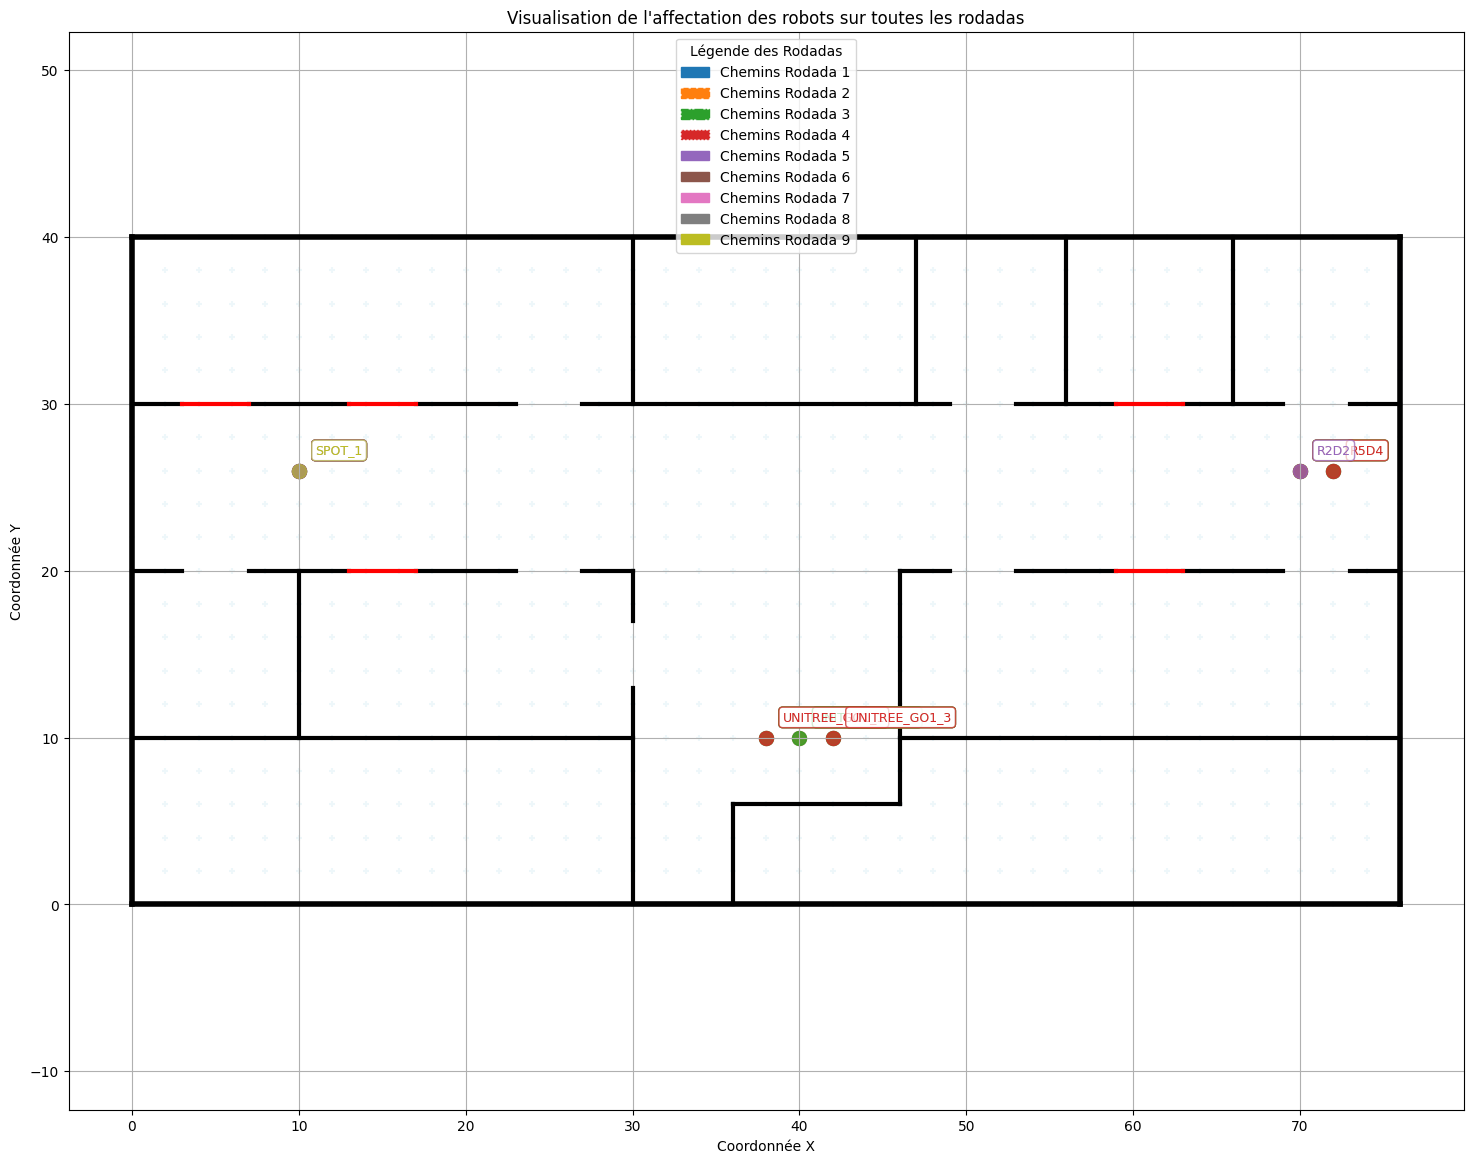

Robots dans cette rodada: ['SPOT_1', 'UNITREE_GO1_1', 'UNITREE_GO1_2', 'UNITREE_GO1_3', 'R2D2', 'R5D4']
Tâches affectées: 6
Coût de la rodada: 133.12
🎨 Visualisation adaptée: Rodada 2
Erreur lors de la planification: [Robot] SPOT_1
Tentative de planification alternative...
Essai avec une grille plus fine...
Échec de la stratégie 1: unsupported operand type(s) for /: 'list' and 'int'
Essai avec une taille de robot réduite...
Erreur lors de la planification: [Robot] SPOT_1
Tentative de planification alternative...
Essai avec une grille plus fine...
Échec de la stratégie 1: unsupported operand type(s) for /: 'list' and 'int'
Essai avec une taille de robot réduite...
Erreur lors de la planification: [Robot] SPOT_1
Tentative de planification alternative...
Essai avec une grille plus fine...
Échec de la stratégie 1: unsupported operand type(s) for /: 'list' and 'int'
Essai avec une taille de robot réduite...
Erreur lors de la planification: [Robot] SPOT_1
Tentative de planification alternati

Erreur lors de la planification: [Robot] R2D2
Tentative de planification alternative...
Essai avec une grille plus fine...
Échec de la stratégie 1: unsupported operand type(s) for /: 'list' and 'int'
Essai avec une taille de robot réduite...
Erreur lors de la planification: [Robot] R2D2
Tentative de planification alternative...
Essai avec une grille plus fine...
Échec de la stratégie 1: unsupported operand type(s) for /: 'list' and 'int'
Essai avec une taille de robot réduite...
Erreur lors de la planification: [Robot] R2D2
Tentative de planification alternative...
Essai avec une grille plus fine...
Échec de la stratégie 1: unsupported operand type(s) for /: 'list' and 'int'
Essai avec une taille de robot réduite...
Erreur lors de la planification: [Robot] R2D2
Tentative de planification alternative...
Essai avec une grille plus fine...
Échec de la stratégie 1: unsupported operand type(s) for /: 'list' and 'int'
Essai avec une taille de robot réduite...
Erreur lors de la planification:

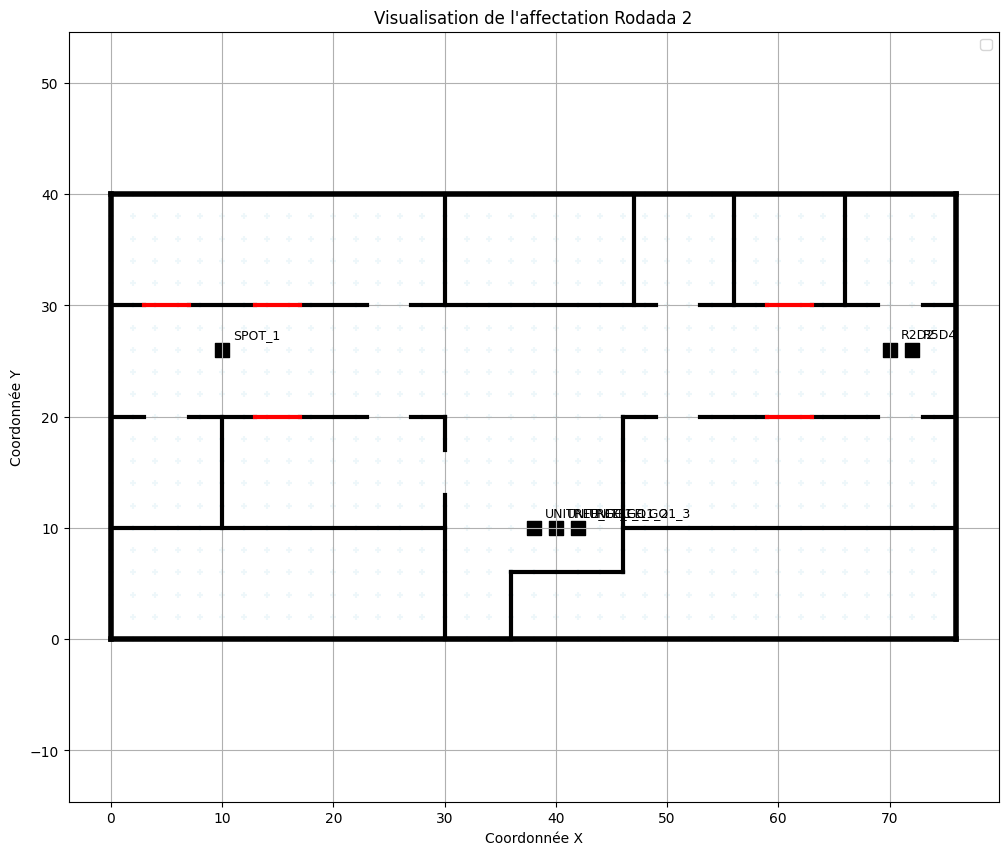


📊 INFORMATIONS DÉTAILLÉES PAR RODADA:
------------------------------------------------------------

🎯 RODADA 1:
   Tâches affectées: 6
   Coût de la rodada: 60.23
   Robots utilisés: 6
      🤖 R2D2:
         Clusters: [2]
         Tâches: 1 - [19]
         Coût robot: 15.62
      🤖 R5D4:
         Clusters: [2]
         Tâches: 1 - [15]
         Coût robot: 14.14
      🤖 SPOT_1:
         Clusters: [0]
         Tâches: 1 - [20]
         Coût robot: 4.47
      🤖 UNITREE_GO1_1:
         Clusters: [1]
         Tâches: 1 - [4]
         Coût robot: 6.00
      🤖 UNITREE_GO1_2:
         Clusters: [1]
         Tâches: 1 - [10]
         Coût robot: 10.00
      🤖 UNITREE_GO1_3:
         Clusters: [1]
         Tâches: 1 - [3]
         Coût robot: 10.00

🎯 RODADA 2:
   Tâches affectées: 6
   Coût de la rodada: 133.12
   Robots utilisés: 6
      🤖 R2D2:
         Clusters: [1]
         Tâches: 1 - [12]
         Coût robot: 22.36
      🤖 R5D4:
         Clusters: [1]
         Tâches: 1 - [17]
         

In [ ]:
# Para visualizar todas as rodadas juntas:
visualiser_toutes_rodadas_ensemble_complete(
    resultats_rounds, liste_robots_contrainte, df_sous_taches, room3, 
    robots_a_visualiser=None, grid_size=2
)

# Para visualizar uma rodada específica (ex: rodada 1):
visualiser_rodada_unique_complete(
    resultats_rounds, 1, liste_robots_contrainte, df_sous_taches, room3, 
    robots_a_visualiser=None, grid_size=2
)

# Para exibir as informações detalhadas no console:
afficher_informations_detaillees_rodadas(resultats_rounds)